<div style="border-top:6px solid #17324d;border-bottom:2px solid #b86b3e;padding:34px 12px;text-align:center">
  <h1 style="margin-bottom:8px">DAC 2026 Preliminary Round</h1>
  <h2 style="margin-top:0;color:#17324d">Integrated Claim Risk and Audit Allocation System</h2>
  <p><b>Ultimate Baseline for Reproducible Analysis and Kaggle Submission</b></p>
  <p>Team details are recorded in the official answer sheet.</p>
</div>

This notebook is the complete analytical record for the preliminary round. It is designed for a **Kaggle Notebook with GPU T4 ×2**, executes from top to bottom without manual edits, and writes the final probability submission to `/kaggle/working/submission.csv`. Its role is decision support: a high score means **priority for investigator review**, never automatic rejection of a claim.

**Integrity statement.** Only the supplied competition data are used for prediction. External sources support theory, interpretation, and governance; no external labels, row matching, identifier lookup, leaderboard probing, or hidden-outcome reconstruction is used.


## Table of Contents

1. [CHAPTER I: Introduction](#chapter-i-introduction)
2. [CHAPTER II: Theoretical Framework](#chapter-ii-theoretical-framework)
3. [CHAPTER III: Analytical Steps](#chapter-iii-analytical-steps)
4. [CHAPTER IV: Analysis of Results](#chapter-iv-analysis-of-results)
5. [CHAPTER V: Conclusion and Recommendation](#chapter-v-conclusion-and-recommendation)
6. [REFERENCES](#references)
7. [ATTACHMENT](#attachment)

All tables and figures are numbered for direct transfer to the official answer sheet. Empty notebook outputs are intentional: every empirical statement is generated from the supplied data when this notebook runs on Kaggle.


# CHAPTER I: Introduction

## 1.1 Background

Healthcare-claim administration converts clinical and administrative records into payment decisions at very high volume. That process must pay legitimate claims promptly while identifying billing errors, abuse, and deliberate fraud. Fraud analytics is therefore not merely a classification exercise: it is a resource-allocation problem embedded in a public-service workflow. Reviews of healthcare-fraud detection emphasize that data mining can narrow a large claims universe to a smaller investigable portfolio, but that data quality, label construction, and organizational implementation determine whether the resulting system is useful [5]–[7]. The World Health Organization’s PhilHealth case study similarly presents machine learning as a complement to, rather than a replacement for, established claims review [2].

The operational asymmetry is central. Undetected fraud can divert pooled resources, distort utilization signals, and weaken trust. Conversely, an unnecessary audit can delay a legitimate claim, increase administrative burden, and expose a policyholder or provider to avoidable scrutiny. OECD and WHO analyses therefore place integrity controls within a broader objective of efficient, transparent, and equitable health financing [3], [4]. A defensible system must concentrate likely fraud while protecting legitimate policyholders from disproportionate audit exposure.

DAC 2026 formalizes this constraint. For $N$ evaluation claims, only $K=\lfloor0.05N\rfloor$ claims are audited. The model must return a probability $\hat p_i\in[0,1]$ for each claim and the portfolio is the $K$ largest values. Ranking quality is consequently necessary but insufficient. Average Precision evaluates concentration across the ranking; Normalized Recall@5% measures capture relative to the maximum possible at that budget; the Brier component rewards reliable probabilities; and the protection component penalizes demographic false-positive-rate disparity [1].

Probability reliability matters because a displayed value may inform triage intensity, investigator staffing, and escalation. Calibration is distinct from discrimination: a model can rank well while its numeric probabilities are systematically too high or low [10], [11]. The distinction is especially important if the labeled training sample was constructed with a fraud prevalence different from the operational population. This notebook therefore reports ranking and calibration separately, does not assume that the training prevalence is the deployment base rate, and includes a prior-shift sensitivity tool rather than inventing an operational prevalence [12].

Interpretability and human oversight complete the design. Feature attribution can reveal which recorded facts influenced a score, but neither attribution nor association establishes causality [26], [27]. Explanations are used to support case review, detect proxies or leakage, and communicate limitations—not to rationalize an automatic denial. Governance follows the WHO and NIST emphasis on accountable human control, ongoing monitoring, documentation, and contestability [29], [30].

## 1.2 Problem Formulation

Let $\mathcal D=\{(x_i,y_i,a_i)\}_{i=1}^{n}$ denote labeled claims, where $x_i$ is the permitted claim information, $y_i\in\{0,1\}$ is the fraud label, and $a_i$ contains protected-group information used for evaluation. A model $f_\theta$ estimates

$$\hat p_i=f_\theta(x_i)\approx \Pr(Y_i=1\mid X_i=x_i).$$

For a capacity $c=0.05$, let $S_c(\hat p)$ be the stable descending top-$\lfloor cn\rfloor$ set. The primary objective is to maximize the official Technical Score while preserving reproducibility and defensible use:

$$
0.55\,NR@5\%+0.20\,AP+0.15(1-\text{Brier})+0.10\left[1-\max(\Delta_{gender},\Delta_{age})\right].
$$

This is a predictive and allocative study. Unless an explicit design supports otherwise, every observed relationship is interpreted as association—not a clinical, behavioral, or causal effect.

## 1.3 Research Questions

**RQ1.** Which schema characteristics, quality defects, duplicates, implausible values, and sampling limitations affect defensible claim-risk estimation?

**RQ2.** Which signals are legitimate predictors, possible proxies, identifiers, or leakage risks, and does performance survive their removal?

**RQ3.** Which validation design best represents both the competition test set and deployment to new claim patterns or locations?

**RQ4.** How much fraud can progressively stronger models capture within a 5% audit portfolio, and how stable is that conclusion across folds, seeds, and model families?

**RQ5.** Are the estimated probabilities reliable, and what calibration method improves Brier performance without optimistic reuse of calibration labels?

**RQ6.** How does audit performance change at 3%, 5%, and 7% capacity, relative to random allocation and a transparent burden baseline?

**RQ7.** Do legitimate claims in eligible gender and age groups experience differential audit exposure, and do protected-attribute or proxy ablations change that disparity?

**RQ8.** Which recorded factors drive high-risk predictions, how stable and plausible are they, and how should investigators use them without causal overinterpretation?

**RQ9.** How should NHPA deploy, monitor, recalibrate, retrain, override, and allow escalation of this decision-support system?


# CHAPTER II: Theoretical Framework

## 2.1 Healthcare Fraud Analytics as Constrained Prioritization

Healthcare-fraud analytics combines claim-domain scrutiny with statistical learning. Earlier work describes a sequence of data cleaning, feature construction, model development, and expert investigation rather than a single automated verdict [5]. Recent systematic evidence highlights continuing challenges from inconsistent data, limited reliable labels, privacy, and weak comparability among studies [6], while data-centric work shows why label and representation quality can dominate algorithm choice [7]. These findings motivate the notebook’s integrity audit, leakage review, ablations, and explicit limits on interpretation.

Under a fixed audit budget, the action is a ranking. If $P=\sum_i y_i$ and $TP_K=\sum_{i\in S_{0.05}}y_i$, then

$$Recall@5\%=\frac{TP_K}{P},\qquad Recall_{max}=\min\left(1,\frac{K}{P}\right),$$

$$NormalizedRecall@5\%=\frac{Recall@5\%}{Recall_{max}}.$$

Normalization recognizes that the capacity itself bounds attainable raw recall. For explicit computational edge handling, normalized recall is undefined when the evaluation set contains no fraud, and is set to zero when fraud exists but $K=0$. Precision–recall analysis is more decision-relevant than accuracy in settings where the positive class or operational action is selective [8], [9]. Average Precision (AP) summarizes precision at successive positive ranks:

$$AP=\sum_n(R_n-R_{n-1})P_n.$$

At a chosen capacity, the notebook also reports precision, legitimate audits, lift over random allocation, and cumulative gains. These quantities translate model performance into investigator workload.

## 2.2 Probability Estimation and Calibration

The Brier score is the mean squared error of probabilistic forecasts [10]:

$$Brier=\frac{1}{n}\sum_{i=1}^n(\hat p_i-y_i)^2,\qquad CalibrationScore=1-Brier.$$

It measures overall probability accuracy and reflects both calibration and refinement; a reliability diagram adds the conditional comparison between predicted and observed rates [11]. This study compares uncalibrated output, logistic sigmoid scaling, and isotonic regression [33]. Calibration assessment is cross-fitted: every reported calibrated OOF value is produced by a calibrator that did not see its label. Isotonic regression is accepted only when its improvement is material and it does not create unstable plateaus near the audit boundary. A monotone sigmoid can improve probability scale while preserving rank.

When deployment prevalence differs from the labeled sample, probabilities can require prior-probability correction under restrictive prior-shift assumptions [12]. Because DAC supplies no operational base rate, the main result retains data-estimated probabilities and presents alternative prevalence correction strictly as sensitivity analysis.

## 2.3 Leakage-Conscious Validation

Leakage occurs when training information would not legitimately be available at prediction time or when validation structure lets information about held-out outcomes enter model construction [13]. Semantic review is therefore combined with uniqueness, univariate behavior, near-deterministic rules, duplicate signatures, distribution shift, importance concentration, and ablation. A variable is not called leakage solely because it predicts well.

Claims can share identical or related patterns. Random row splitting may then estimate performance on repeated patterns rather than unseen ones. Structured cross-validation is recommended when data have hierarchical, spatial, or temporal dependence [14]. The primary design groups identical feature signatures inside one fold and stratifies labels as far as possible. Ordinary stratification is retained as an optimism diagnostic, while a location-held-out split probes transportability. Model and calibration selection are separated from their held-out predictions to reduce selection bias [15], [34].

## 2.4 Progressive Predictive Models

The baselines establish incremental value: fold prevalence, a deliberately simple low-dimensional claim-burden heuristic expressed as a logistic score, and regularized logistic regression. Logistic regression supplies a transparent linear log-odds benchmark. Gradient-boosted trees then model nonlinearities and interactions by sequentially fitting residual structure [16].

CatBoost is included because it natively represents categorical variables and uses ordered target-statistic machinery designed to reduce target leakage in categorical boosting [17]. XGBoost provides a strong, complementary regularized tree ensemble with GPU-accelerated histogram construction [18]. Both use early stopping and the same primary folds. Neural networks and exhaustive searches are excluded: GPU availability is not methodological evidence, and targeted models provide a stronger reproducibility–performance trade-off for heterogeneous tabular claims.

Ensembling is considered only when CatBoost and XGBoost predictions are not redundant and a low-dimensional, cross-fitted weight improves the composite score consistently. Otherwise the simpler single model is retained.

## 2.5 Statistical Association and Distribution Shift

Categorical association is summarized by chi-square testing and Cramér’s $V$; numeric separation uses the Mann–Whitney statistic, rank-biserial effect size, and Kolmogorov–Smirnov distance. Benjamini–Hochberg adjustment controls the expected false-discovery proportion across screened features [19]. Large samples can make negligible effects statistically significant, so effect size and uncertainty—not $p$-value alone—drive interpretation.

Train–test shift is assessed through standardized mean difference, KS distance, Jensen–Shannon divergence [20], unseen levels, and adversarial-validation AUC. These diagnose covariate shift, not hidden-label behavior. Bootstrap intervals quantify sampling variation of selected operational metrics [21], while Wilson intervals describe group false-positive rates without relying on unstable Wald approximations [22].

## 2.6 Policyholder Protection, Explainability, and Governance

For eligible group $g$ with at least 100 legitimate claims, the competition defines

$$FPR_g=\frac{\#\{i\in g:y_i=0,\ i\in S_c\}}{\#\{i\in g:y_i=0\}},\qquad
\Delta=\max_gFPR_g-\min_gFPR_g.$$

The Protection Score is $1-\max(\Delta_{gender},\Delta_{age})$. This resembles false-positive-rate parity [23], but a gap is an observed disparity rather than proof of discrimination. Healthcare fairness depends on label validity, case mix, access, measurement, and proxy structure [24], [25]. The notebook therefore reports denominators and uncertainty, tests protected/proxy ablations, and avoids demographic score manipulation.

Global permutation importance and model-native importance show predictive reliance; SHAP decomposes an individual model output into feature contributions [26]. Shapley-based importance can be sensitive to feature dependence and should not be treated as a causal ranking [27]. Explanations are consequently triangulated and framed as review aids, consistent with multidisciplinary recommendations for healthcare explainability [28].

Finally, deployment is governed as a monitored human–AI system. WHO and NIST guidance supports documentation, oversight, contestability, and continuing risk management [29], [30]. Covariate and concept drift must be distinguished [31], and clinical-AI deployment literature cautions that retrospective accuracy alone does not establish real-world impact [32]. The operational framework therefore monitors ranking, calibration, disparities, inputs, prevalence, workload, overrides, and appeals.


# CHAPTER III: Analytical Steps

## 3.1 Reproducible Analytical Design

The workflow below follows the official Tasks A–E and separates empirical description, predictive validation, probability calibration, allocation, policyholder protection, and operational governance. Every transformation that learns from data is fit inside the relevant training fold. Pure identifiers and constants are excluded before modeling; protected attributes remain available for evaluation even when removed in an ablation.


In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss


In [2]:
def _as_binary(y):
    y = np.asarray(y)
    if y.ndim != 1 or not np.isin(y, [0, 1]).all():
        raise ValueError("y_true must be a one-dimensional binary array")
    return y.astype(int)


def top_k_mask(probabilities, capacity=0.05):
    """Stable top-k selection; input order deterministically breaks exact ties."""
    p = np.asarray(probabilities, dtype=float)
    if p.ndim != 1 or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("probabilities must be finite values in [0, 1]")
    if not 0 <= capacity <= 1:
        raise ValueError("capacity must be in [0, 1]")
    k = int(np.floor(capacity * len(p)))
    selected = np.zeros(len(p), dtype=bool)
    if k:
        selected[np.argsort(-p, kind="mergesort")[:k]] = True
    return selected


def age_groups(age):
    values = pd.to_numeric(pd.Series(age), errors="coerce")
    values = values.mask(values < 0)
    bands = pd.cut(
        values,
        bins=[-np.inf, 17, 39, 59, np.inf],
        labels=["0–17", "18–39", "40–59", "60+"],
        right=True,
    ).astype("object")
    return pd.Series(bands, index=values.index).fillna("Missing")


def group_fpr_table(y_true, selected, group, attribute, min_nonfraud=100):
    y = _as_binary(y_true)
    selected = np.asarray(selected, dtype=bool)
    if len(y) != len(selected) or len(y) != len(group):
        raise ValueError("y_true, selected, and group must have equal length")
    values = pd.Series(group).astype("string").str.strip().fillna("Missing")
    values = values.mask(values.eq(""), "Missing")
    rows = []
    for level in sorted(values.unique().tolist()):
        member = values.eq(level).to_numpy()
        legitimate = member & (y == 0)
        denominator = int(legitimate.sum())
        false_positive = int((legitimate & selected).sum())
        eligible = denominator >= min_nonfraud
        rows.append(
            {
                "attribute": attribute,
                "group": str(level),
                "population": int(member.sum()),
                "nonfraud": denominator,
                "audit_count": int((member & selected).sum()),
                "legitimate_audits": false_positive,
                "FPR": false_positive / denominator if denominator else np.nan,
                "eligible": eligible,
            }
        )
    table = pd.DataFrame(rows)
    eligible_fpr = table.loc[table["eligible"], "FPR"].dropna()
    gap = float(eligible_fpr.max() - eligible_fpr.min()) if len(eligible_fpr) >= 2 else 0.0
    return table, gap


def protection_score(y_true, selected, groups):
    gender = groups["gender"] if "gender" in groups else pd.Series("Missing", index=groups.index)
    age = groups["age"] if "age" in groups else pd.Series(np.nan, index=groups.index)
    gender_table, gender_gap = group_fpr_table(y_true, selected, gender, "gender")
    age_table, age_gap = group_fpr_table(y_true, selected, age_groups(age), "age_group")
    score = 1.0 - max(gender_gap, age_gap)
    return float(score), gender_gap, age_gap, gender_table, age_table


def combine_technical_score(normalized_recall, average_precision, calibration, protection):
    values = np.asarray([normalized_recall, average_precision, calibration, protection], dtype=float)
    if not np.isfinite(values).all():
        return np.nan
    return float(0.55 * values[0] + 0.20 * values[1] + 0.15 * values[2] + 0.10 * values[3])


def official_metrics(y_true, probabilities, groups, capacity=0.05):
    """Exact DAC score components plus transparent audit diagnostics."""
    y = _as_binary(y_true)
    p = np.asarray(probabilities, dtype=float)
    if len(y) != len(p) or len(y) != len(groups):
        raise ValueError("labels, probabilities, and protected groups must align")
    selected = top_k_mask(p, capacity)
    n = len(y)
    k = int(selected.sum())
    positives = int(y.sum())
    captured = int(y[selected].sum())
    raw_recall = captured / positives if positives else np.nan
    recall_max = min(1.0, k / positives) if positives else np.nan
    normalized = raw_recall / recall_max if positives and recall_max > 0 else (0.0 if positives else np.nan)
    ap = float(average_precision_score(y, p)) if positives else np.nan
    brier = float(brier_score_loss(y, p))
    calibration = 1.0 - brier
    protection, gender_gap, age_gap, _, _ = protection_score(y, selected, groups)
    technical = combine_technical_score(normalized, ap, calibration, protection)
    precision = captured / k if k else np.nan
    prevalence = positives / n if n else np.nan
    return {
        "N": n,
        "K": k,
        "P": positives,
        "TP_K": captured,
        "Recall@5%": raw_recall,
        "Recall@capacity": raw_recall,
        "Recall_max": recall_max,
        "NormalizedRecall@5%": normalized,
        "NormalizedRecall@capacity": normalized,
        "AveragePrecision": ap,
        "Brier": brier,
        "CalibrationScore": calibration,
        "Gap_gender": gender_gap,
        "Gap_age": age_gap,
        "ProtectionScore": protection,
        "TechnicalScore": technical,
        "Precision@capacity": precision,
        "LegitimateAudits": k - captured,
        "AuditFPR": (k - captured) / max(n - positives, 1),
        "Lift@capacity": precision / prevalence if k and prevalence else np.nan,
    }


In [3]:
# Table-driven sanity checks for competition edge cases.
_groups20 = pd.DataFrame({"gender": ["F"] * 20, "age": [30] * 20})
_case = official_metrics(
    np.array([1, 1, 0, 0] + [0] * 16), np.linspace(1, 0, 20), _groups20
)
assert _case["K"] == 1 and np.isclose(_case["Recall@5%"], 0.5)
assert np.isclose(_case["NormalizedRecall@5%"], 1.0)
assert np.flatnonzero(top_k_mask(np.full(40, 0.5), 0.05)).tolist() == [0, 1]
_zero_capacity = official_metrics(
    np.array([1] + [0] * 18), np.ones(19),
    pd.DataFrame({"gender": ["F"] * 19, "age": [30] * 19}),
)
assert _zero_capacity["K"] == 0 and _zero_capacity["NormalizedRecall@5%"] == 0.0
assert age_groups([0, 17, 18, 39, 40, 59, 60]).tolist() == [
    "0–17", "0–17", "18–39", "18–39", "40–59", "40–59", "60+"
]
assert np.isnan(official_metrics(np.zeros(20), np.full(20, 0.5), _groups20)["NormalizedRecall@5%"])
assert np.isclose(combine_technical_score(0.5, 0.4, 0.8, 0.9), 0.565)

_edge_groups = pd.DataFrame(
    {"gender": ["F"] * 200 + [None] * 200, "age": [30] * 200 + [65] * 200}
)
_edge_selected = np.array([True] * 20 + [False] * 380)
_edge_table, _edge_gap = group_fpr_table(
    np.zeros(400, dtype=int), _edge_selected, _edge_groups["gender"], "gender"
)
assert _edge_table["eligible"].all() and np.isclose(_edge_gap, 0.1)
_small_table, _ = group_fpr_table(
    np.zeros(400, dtype=int), _edge_selected, pd.Series(["A"] * 99 + ["B"] * 301), "small"
)
assert not bool(_small_table.loc[_small_table["group"].eq("A"), "eligible"].iloc[0])
print("Official metric sanity checks passed, including ties, missing groups, eligibility, no-fraud, and K=0 cases.")


Official metric sanity checks passed, including ties, missing groups, eligibility, no-fraud, and K=0 cases.


## 3.2 Environment, Configuration, and Hardware

The configuration below is the single source of truth. Full mode is the default. A smoke run can be requested externally with the environment variable `DAC_FAST_MODE=1`; no cell editing is required. CatBoost uses both visible GPUs through `devices="0:1"` when two devices are available [35]. XGBoost uses `tree_method="hist", device="cuda"` on one device, following its stable scikit-learn interface [36]. Fold training remains sequential to avoid competing for the same accelerators. CatBoost documents that GPU floating-point reduction order can introduce small run-to-run differences even with a fixed seed; seed sensitivity is therefore measured rather than concealed [35].


In [4]:
import gc
import json
import math
import os
import platform
import random
import subprocess
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from scipy.spatial.distance import jensenshannon
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    log_loss,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from catboost import CatBoostClassifier, Pool
from catboost.utils import get_gpu_device_count
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass(frozen=True)
class Config:
    seed: int = 2026
    folds: int = 5
    calibration_folds: int = 5
    capacities: tuple = (0.03, 0.05, 0.07)
    fast_mode: bool = os.getenv("DAC_FAST_MODE", "0") == "1"
    cat_iterations: int = 2200
    xgb_estimators: int = 2200
    early_stopping: int = 180
    bootstrap_repetitions: int = 250
    shap_sample: int = 1000
    min_group_nonfraud: int = 100


CFG = Config()
if CFG.fast_mode:
    CFG = Config(
        fast_mode=True,
        cat_iterations=350,
        xgb_estimators=350,
        early_stopping=60,
        bootstrap_repetitions=40,
        shap_sample=250,
    )

IS_KAGGLE = Path("/kaggle/input").exists()
OUTPUT_DIR = Path("/kaggle/working" if IS_KAGGLE else "/tmp/dac2026_working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(CFG.seed)
np.random.seed(CFG.seed)
os.environ["PYTHONHASHSEED"] = str(CFG.seed)

GPU_COUNT = int(get_gpu_device_count())
CAT_TASK = "GPU" if GPU_COUNT else "CPU"
CAT_DEVICES = ":".join(map(str, range(GPU_COUNT))) if GPU_COUNT else None
XGB_DEVICE = "cuda" if GPU_COUNT else "cpu"

REPORT_FACTS, METRICS, TABLES, FIGURES = {}, {}, {}, {}
OOF_PREDICTIONS, TEST_PREDICTIONS, MODEL_ARTIFACTS = {}, {}, {}
FOLD_RECORDS, EXPERIMENTS = [], []

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"navy": "#17324d", "teal": "#2a7f7f", "orange": "#b86b3e", "gray": "#64748b", "red": "#a23b3b"}
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "axes.titleweight": "bold"})


def report_block(question, method, result, implication, limitation):
    display(Markdown(
        f"**Question.** {question}\n\n"
        f"**Method.** {method}\n\n"
        f"**Result.** {result}\n\n"
        f"**Decision implication.** {implication}\n\n"
        f"**Limitation / alternative explanation.** {limitation}"
    ))


def show_table(frame, number, title, precision=4):
    TABLES[number] = frame.copy()
    display(Markdown(f"**Table {number}. {title}**"))
    display(frame.style.format(precision=precision, na_rep="—"))


def finish_figure(fig, number, caption):
    path = OUTPUT_DIR / f"figure_{number.replace('.', '_')}.png"
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    FIGURES[number] = str(path)
    plt.show()
    display(Markdown(f"*Figure {number}. {caption}*"))


hardware = "\n".join(
    subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        check=False,
    ).stdout.strip().splitlines()
) if GPU_COUNT else "No CUDA GPU detected; CPU fallbacks will be used."

display(Markdown(
    f"**Runtime.** Python {platform.python_version()} on `{platform.platform()}`  \n"
    f"**Mode.** {'smoke' if CFG.fast_mode else 'full competition'}  \n"
    f"**Visible GPU count.** {GPU_COUNT}  \n"
    f"**CatBoost devices.** `{CAT_DEVICES or 'CPU'}`  \n"
    f"**Detected hardware.** {hardware.replace(chr(10), '; ')}"
))


**Runtime.** Python 3.12.13 on `Linux-6.12.90+-x86_64-with-glibc2.35`  
**Mode.** full competition  
**Visible GPU count.** 2  
**CatBoost devices.** `0:1`  
**Detected hardware.** Tesla T4, 15360 MiB; Tesla T4, 15360 MiB

## 3.3 Analytical Flow

The workflow is deliberately linear. Results are generated once, stored in named registries, and reused in Chapter IV and the final conclusion so that prose, tables, figures, and submission probabilities cannot silently diverge.


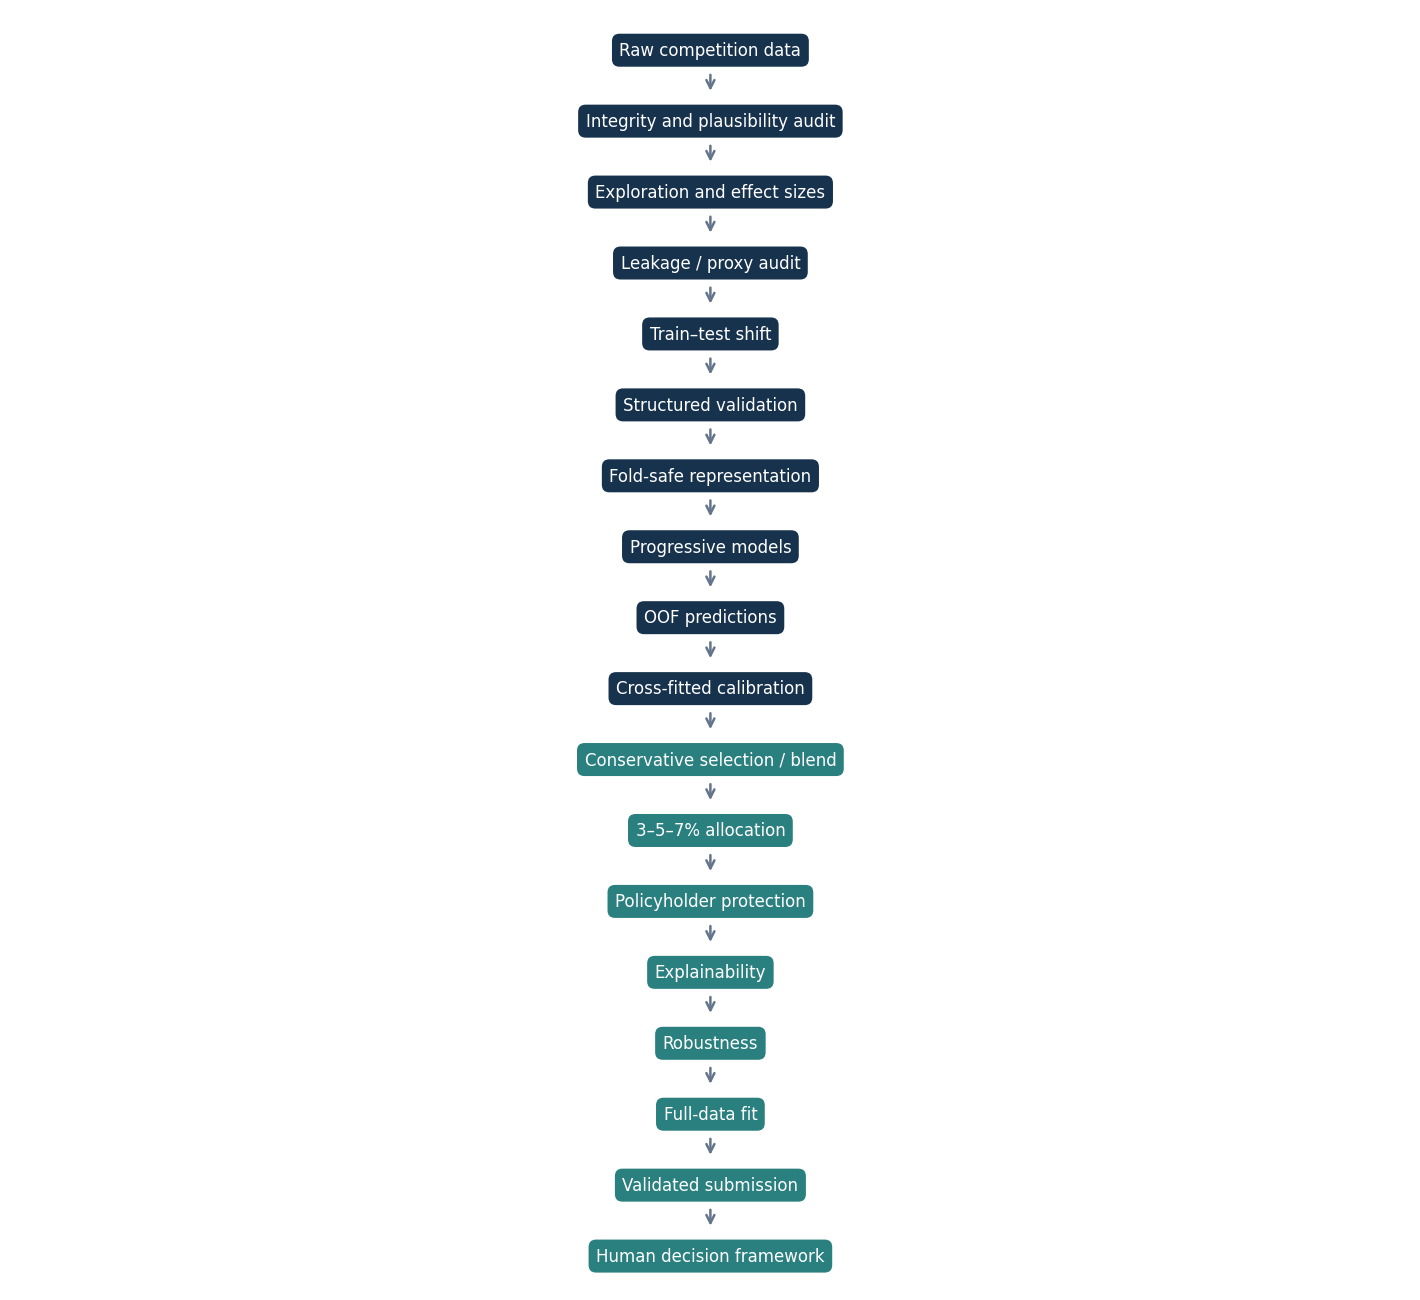

*Figure 3.1. End-to-end leakage-conscious claim-risk and audit-allocation workflow.*

In [5]:
steps = [
    "Raw competition data", "Integrity and plausibility audit", "Exploration and effect sizes",
    "Leakage / proxy audit", "Train–test shift", "Structured validation",
    "Fold-safe representation", "Progressive models", "OOF predictions",
    "Cross-fitted calibration", "Conservative selection / blend", "3–5–7% allocation",
    "Policyholder protection", "Explainability", "Robustness",
    "Full-data fit", "Validated submission", "Human decision framework",
]
fig, ax = plt.subplots(figsize=(12, 11))
ax.set_xlim(0, 1); ax.set_ylim(0, len(steps)); ax.axis("off")
for i, step in enumerate(steps):
    y_pos = len(steps) - i - 0.55
    color = COLORS["navy"] if i < 10 else COLORS["teal"]
    ax.text(0.5, y_pos, step, ha="center", va="center", color="white", fontsize=10,
            bbox={"boxstyle": "round,pad=0.45", "facecolor": color, "edgecolor": "none"})
    if i < len(steps) - 1:
        ax.annotate("", xy=(0.5, y_pos - 0.62), xytext=(0.5, y_pos - 0.30),
                    arrowprops={"arrowstyle": "->", "color": COLORS["gray"], "lw": 1.5})
finish_figure(fig, "3.1", "End-to-end leakage-conscious claim-risk and audit-allocation workflow.")


## 3.4 Data Discovery and Contract Validation

The loader searches Kaggle inputs by schema rather than competition slug. A training candidate must contain `claim_id` and `label`; a test candidate must contain `claim_id` without `label`; and the sample must contain exactly `claim_id` and `fraud_probability`. The largest matching files are chosen and their contracts are asserted before analysis.


In [6]:
def discover_competition_files():
    roots = [Path("/kaggle/input")] if IS_KAGGLE else [Path.cwd() / "data", Path.cwd().parent / "data"]
    csv_files = []
    for root in roots:
        if root.exists():
            csv_files.extend(root.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV files found under Kaggle input or the local data directory.")

    candidates = []
    for path in csv_files:
        try:
            columns = pd.read_csv(path, nrows=2).columns.tolist()
            candidates.append((path, columns, path.stat().st_size))
        except Exception:
            continue
    train_options = [x for x in candidates if {"claim_id", "label"}.issubset(x[1])]
    sample_options = [x for x in candidates if set(x[1]) == {"claim_id", "fraud_probability"}]
    if not train_options or not sample_options:
        raise FileNotFoundError("Could not identify train, test, and sample submission by schema.")
    largest = lambda options: max(options, key=lambda x: x[2])[0]
    train_record = max(train_options, key=lambda x: x[2])
    expected_test_columns = set(train_record[1]) - {"label"}
    test_options = [x for x in candidates if set(x[1]) == expected_test_columns]
    if not test_options:
        raise FileNotFoundError("No test CSV exactly matches the training feature schema.")
    return train_record[0], largest(test_options), largest(sample_options)


TRAIN_PATH, TEST_PATH, SAMPLE_PATH = discover_competition_files()
train_raw = pd.read_csv(TRAIN_PATH, low_memory=False)
test_raw = pd.read_csv(TEST_PATH, low_memory=False)
sample_submission = pd.read_csv(SAMPLE_PATH, low_memory=False)

ID_COL, TARGET_COL = "claim_id", "label"
assert TARGET_COL in train_raw and TARGET_COL not in test_raw
assert ID_COL in train_raw and ID_COL in test_raw
assert list(sample_submission.columns) == [ID_COL, "fraud_probability"]
assert set(test_raw[ID_COL].astype(str)) == set(sample_submission[ID_COL].astype(str))

test_raw = (
    sample_submission[[ID_COL]].assign(_order=np.arange(len(sample_submission)))
    .merge(test_raw, on=ID_COL, how="left", validate="one_to_one")
    .sort_values("_order").drop(columns="_order").reset_index(drop=True)
)
assert len(test_raw) == len(sample_submission) and not test_raw[ID_COL].isna().any()

REPORT_FACTS.update({
    "train_rows": len(train_raw), "test_rows": len(test_raw), "columns": train_raw.shape[1],
    "train_path": str(TRAIN_PATH), "test_path": str(TEST_PATH), "sample_path": str(SAMPLE_PATH),
})
display(Markdown(
    f"Loaded **{len(train_raw):,} labeled claims** with **{train_raw.shape[1]:,} columns** and "
    f"**{len(test_raw):,} evaluation claims**. Files were identified as `{TRAIN_PATH}`, `{TEST_PATH}`, "
    f"and `{SAMPLE_PATH}`. Evaluation rows now follow the official sample-submission order."
))


Loaded **160,174 labeled claims** with **53 columns** and **40,043 evaluation claims**. Files were identified as `/kaggle/input/competitions/dac-its-2026/train.csv`, `/kaggle/input/competitions/dac-its-2026/test.csv`, and `/kaggle/input/competitions/dac-its-2026/sample_submission.csv`. Evaluation rows now follow the official sample-submission order.

## 3.5 Cleaning and Domain-Safe Representation

Whitespace is stripped from categorical codes and blank text becomes an explicit missing level. Numeric fields are coerced without deleting extremes: unusual values remain available for forensic review and tree models. `claim_id` is retained only for alignment. Constant training fields are documented and excluded. Feature engineering is restricted to claim-level quantities available at scoring time: age band, log length of stay, diagnosis/procedure burden, sparsity counts, and a small set of categorical interactions. No target encoding or test-label information is used.


In [7]:
SEMANTIC_CATEGORICAL = {
    "kdkc", "dati2", "typeppk", "jkpst", "jnspelsep", "cmg", "severitylevel", "diagprimer"
}


def clean_claims(frame):
    out = frame.copy()
    for column in out.columns:
        if column in {ID_COL, TARGET_COL}:
            continue
        if column in SEMANTIC_CATEGORICAL or out[column].dtype == "object":
            values = out[column].astype("string").str.strip()
            out[column] = values.mask(values.eq(""), "__MISSING__").fillna("__MISSING__")
        else:
            out[column] = pd.to_numeric(out[column], errors="coerce")
    return out


def engineer_features(frame):
    out = frame.copy()
    dx = [c for c in out if c.startswith("dx2_")]
    proc = [c for c in out if c.startswith("proc")]
    if "umur" in out:
        out["age_band"] = age_groups(out["umur"]).astype("string")
        out["is_pediatric"] = (pd.to_numeric(out["umur"], errors="coerce") <= 17).astype(int)
        out["is_older_adult"] = (pd.to_numeric(out["umur"], errors="coerce") >= 60).astype(int)
    if "los" in out:
        out["log1p_los"] = np.log1p(pd.to_numeric(out["los"], errors="coerce").clip(lower=0))
    for prefix, columns in (("diagnosis", dx), ("procedure", proc)):
        if columns:
            block = out[columns].apply(pd.to_numeric, errors="coerce").fillna(0)
            out[f"{prefix}_total"] = block.sum(axis=1)
            out[f"{prefix}_nonzero_groups"] = block.ne(0).sum(axis=1)
            out[f"{prefix}_max_group"] = block.max(axis=1)
    if {"diagnosis_total", "procedure_total"}.issubset(out):
        out["total_coded_burden"] = out["diagnosis_total"] + out["procedure_total"]
        out["log1p_coded_burden"] = np.log1p(out["total_coded_burden"].clip(lower=0))
    interactions = {
        "cmg__severity": ("cmg", "severitylevel"),
        "service__facility": ("jnspelsep", "typeppk"),
        "geo__facility": ("dati2", "typeppk"),
    }
    for name, (left, right) in interactions.items():
        if left in out and right in out:
            out[name] = out[left].astype("string") + "__" + out[right].astype("string")
    return out


train_clean = clean_claims(train_raw)
test_clean = clean_claims(test_raw)
train_model = engineer_features(train_clean)
test_model = engineer_features(test_clean)

raw_feature_columns = [c for c in train_clean if c not in {ID_COL, TARGET_COL}]
CONSTANT_COLUMNS = [c for c in raw_feature_columns if train_clean[c].nunique(dropna=False) <= 1]
FEATURE_COLUMNS = [c for c in train_model if c not in {ID_COL, TARGET_COL, *CONSTANT_COLUMNS}]
CATEGORICAL_COLUMNS = [
    c for c in FEATURE_COLUMNS
    if c in SEMANTIC_CATEGORICAL or str(train_model[c].dtype) in {"object", "string"}
]
NUMERIC_COLUMNS = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]

X = train_model[FEATURE_COLUMNS].copy()
X_test = test_model[FEATURE_COLUMNS].copy()
target_values = pd.to_numeric(train_model[TARGET_COL], errors="raise")
if target_values.isna().any() or not target_values.isin([0, 1]).all():
    raise ValueError("The training label must be complete and binary (0/1).")
y = target_values.astype(int).to_numpy()
PROTECTED = pd.DataFrame({
    "gender": train_clean["jkpst"] if "jkpst" in train_clean else pd.Series("Missing", index=train_clean.index),
    "age": train_clean["umur"] if "umur" in train_clean else pd.Series(np.nan, index=train_clean.index),
})
TEST_PROTECTED = pd.DataFrame({
    "gender": test_clean["jkpst"] if "jkpst" in test_clean else pd.Series("Missing", index=test_clean.index),
    "age": test_clean["umur"] if "umur" in test_clean else pd.Series(np.nan, index=test_clean.index),
})

REPORT_FACTS.update({
    "target_prevalence": float(y.mean()), "categorical_features": len(CATEGORICAL_COLUMNS),
    "numeric_features": len(NUMERIC_COLUMNS), "constant_columns": CONSTANT_COLUMNS,
})
display(Markdown(
    f"The model matrix contains **{len(FEATURE_COLUMNS)} features** "
    f"({len(CATEGORICAL_COLUMNS)} categorical and {len(NUMERIC_COLUMNS)} numeric). "
    f"The labeled fraud prevalence is **{y.mean():.2%}**. This prevalence is described as a property of the "
    "competition sample, not an asserted operational base rate."
))


The model matrix contains **63 features** (12 categorical and 51 numeric). The labeled fraud prevalence is **50.07%**. This prevalence is described as a property of the competition sample, not an asserted operational base rate.

## 3.6 Dataset Forensics

The integrity audit covers schema, completeness, special codes, duplicates, repeated feature signatures, label conflicts, plausibility, rare and unseen categories, numeric extremes, and grouped-code sparsity. Plausibility flags are prompts for review; without a data dictionary or clinical adjudication, they are not grounds for deleting a claim.


In [8]:
def feature_signature(frame, columns):
    normalized = frame[columns].copy()
    for column in columns:
        normalized[column] = normalized[column].astype("string").fillna("__NA__")
    return pd.util.hash_pandas_object(normalized, index=False).astype("uint64")


def quality_profile(train_frame, test_frame):
    rows = []
    for column in train_frame.columns:
        if column == TARGET_COL:
            continue
        series = train_frame[column]
        test_series = test_frame[column] if column in test_frame else pd.Series(dtype=series.dtype)
        blank = int(series.astype("string").str.strip().eq("").sum()) if series.dtype == "object" else 0
        numeric = pd.to_numeric(series, errors="coerce") if column not in CATEGORICAL_COLUMNS else None
        train_levels = set(series.dropna().astype(str).unique())
        test_levels = set(test_series.dropna().astype(str).unique())
        level_counts = series.astype("string").fillna("Missing").value_counts()
        rows.append({
            "feature": column,
            "dtype": str(series.dtype),
            "missing_n": int(series.isna().sum()),
            "missing_pct": float(series.isna().mean()),
            "blank_n": blank,
            "cardinality": int(series.nunique(dropna=False)),
            "rare_levels_lt20": int((level_counts < 20).sum()),
            "rows_in_rare_levels": int(level_counts[level_counts < 20].sum()),
            "train_only_levels": len(train_levels - test_levels),
            "test_only_levels": len(test_levels - train_levels),
            "min": float(numeric.min()) if numeric is not None and numeric.notna().any() else np.nan,
            "median": float(numeric.median()) if numeric is not None and numeric.notna().any() else np.nan,
            "max": float(numeric.max()) if numeric is not None and numeric.notna().any() else np.nan,
        })
    return pd.DataFrame(rows)


QUALITY_PROFILE = quality_profile(train_raw, test_raw)
signature_columns = [c for c in train_clean if c not in {ID_COL, TARGET_COL}]
SIGNATURE_GROUPS = feature_signature(train_clean, signature_columns)
TEST_SIGNATURES = feature_signature(test_clean, signature_columns)
signature_summary = (
    pd.DataFrame({"signature": SIGNATURE_GROUPS, "label": y})
    .groupby("signature", observed=True)["label"]
    .agg(rows="size", positives="sum", label_values="nunique")
)

SPECIAL_CODES = {-1, -9, -99, -999}
special_code_count = 0
negative_count = 0
for column in train_clean.select_dtypes(include=np.number).columns.difference([TARGET_COL]):
    values = train_clean[column]
    special_code_count += int(values.isin(SPECIAL_CODES).sum())
    if column.startswith("dx2_") or column.startswith("proc") or column in {"umur", "los"}:
        negative_count += int(values.lt(0).sum())

plausibility_rows = []
checks = {
    "age below 0": train_clean.get("umur", pd.Series(dtype=float)).lt(0),
    "age above 120": train_clean.get("umur", pd.Series(dtype=float)).gt(120),
    "negative length of stay": train_clean.get("los", pd.Series(dtype=float)).lt(0),
    "length of stay above 365 (review flag)": train_clean.get("los", pd.Series(dtype=float)).gt(365),
    "non-binary label": ~train_clean[TARGET_COL].isin([0, 1]),
}
grouped_numeric = train_clean[[c for c in train_clean if c.startswith("dx2_") or c.startswith("proc")]].apply(pd.to_numeric, errors="coerce")
checks["row with a negative diagnosis/procedure count"] = grouped_numeric.lt(0).any(axis=1)
checks["row with a non-integer diagnosis/procedure count"] = grouped_numeric.notna().any(axis=1) & grouped_numeric.mod(1).fillna(0).ne(0).any(axis=1)
for check, mask in checks.items():
    plausibility_rows.append({"check": check, "flagged_claims": int(mask.fillna(False).sum())})
PLAUSIBILITY = pd.DataFrame(plausibility_rows)

DUPLICATE_SUMMARY = pd.DataFrame([
    {"check": "duplicate claim_id (train)", "count": int(train_raw[ID_COL].duplicated().sum())},
    {"check": "duplicate claim_id (test)", "count": int(test_raw[ID_COL].duplicated().sum())},
    {"check": "exact duplicate rows (train)", "count": int(train_raw.duplicated().sum())},
    {"check": "feature signatures occurring more than once", "count": int((signature_summary["rows"] > 1).sum())},
    {"check": "rows belonging to repeated signatures", "count": int(signature_summary.loc[signature_summary["rows"] > 1, "rows"].sum())},
    {"check": "signatures with conflicting labels", "count": int((signature_summary["label_values"] > 1).sum())},
    {"check": "train signatures also present in test", "count": int(len(set(SIGNATURE_GROUPS) & set(TEST_SIGNATURES)))},
])

GROUPED_CODE_COLUMNS = [c for c in train_clean if c.startswith("dx2_") or c.startswith("proc")]
SPARSITY = pd.DataFrame({
    "feature": GROUPED_CODE_COLUMNS,
    "zero_pct": [float(pd.to_numeric(train_clean[c], errors="coerce").fillna(0).eq(0).mean()) for c in GROUPED_CODE_COLUMNS],
    "nonzero_n": [int(pd.to_numeric(train_clean[c], errors="coerce").fillna(0).ne(0).sum()) for c in GROUPED_CODE_COLUMNS],
}).sort_values("zero_pct", ascending=False)

numeric_profile_columns = [
    c for c in train_clean.select_dtypes(include=np.number)
    if c not in {TARGET_COL, ID_COL} and c not in CONSTANT_COLUMNS
]
NUMERIC_SUMMARY = train_clean[numeric_profile_columns].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T.rename(columns={"50%": "median"})
NUMERIC_SUMMARY["skewness"] = train_clean[numeric_profile_columns].skew(numeric_only=True)
NUMERIC_SUMMARY = NUMERIC_SUMMARY.reset_index().rename(columns={"index": "feature"})

presence = grouped_numeric.fillna(0).ne(0).to_numpy(dtype=np.uint32)
intersections = presence.T @ presence
marginals = np.diag(intersections)
cooccurrence_rows = []
for left in range(len(GROUPED_CODE_COLUMNS)):
    for right in range(left + 1, len(GROUPED_CODE_COLUMNS)):
        both = int(intersections[left, right])
        union = int(marginals[left] + marginals[right] - both)
        cooccurrence_rows.append({
            "feature_1": GROUPED_CODE_COLUMNS[left], "feature_2": GROUPED_CODE_COLUMNS[right],
            "cooccurring_claims": both, "jaccard": both / union if union else 0.0,
        })
GROUP_COOCCURRENCE = pd.DataFrame(cooccurrence_rows).sort_values(
    ["jaccard", "cooccurring_claims"], ascending=False
)

binary_rows = []
for column in raw_feature_columns:
    values = pd.to_numeric(train_clean[column], errors="coerce")
    observed = set(values.dropna().unique().tolist())
    if observed and observed.issubset({0, 1}) and len(observed) == 2:
        binary_rows.append({
            "feature": column, "one_n": int(values.eq(1).sum()),
            "one_pct": float(values.eq(1).mean()),
            "fraud_rate_when_0": float(np.mean(y[values.eq(0).to_numpy()])),
            "fraud_rate_when_1": float(np.mean(y[values.eq(1).to_numpy()])),
        })
BINARY_PROFILE = pd.DataFrame(binary_rows).sort_values("one_pct") if binary_rows else pd.DataFrame(
    columns=["feature", "one_n", "one_pct", "fraud_rate_when_0", "fraud_rate_when_1"]
)

TABLES["A.quality_profile"] = QUALITY_PROFILE
TABLES["A.duplicate_summary"] = DUPLICATE_SUMMARY
TABLES["A.plausibility"] = PLAUSIBILITY
TABLES["A.grouped_code_sparsity"] = SPARSITY
TABLES["A.numeric_summary"] = NUMERIC_SUMMARY
TABLES["A.grouped_code_cooccurrence"] = GROUP_COOCCURRENCE
TABLES["A.binary_profile"] = BINARY_PROFILE
REPORT_FACTS.update({
    "missing_cells": int(train_raw.isna().sum().sum()),
    "blank_cells": int(QUALITY_PROFILE["blank_n"].sum()),
    "special_codes": special_code_count,
    "negative_counts": negative_count,
    "repeated_signature_rows": int(signature_summary.loc[signature_summary["rows"] > 1, "rows"].sum()),
    "conflicting_signatures": int((signature_summary["label_values"] > 1).sum()),
    "test_signature_overlap": int(len(set(SIGNATURE_GROUPS) & set(TEST_SIGNATURES))),
})


## 3.7 Association Analysis

The screening layer asks whether recorded variables differ between labels and how large those differences are. It is descriptive and multiplicity-adjusted. Categorical levels with very small counts are pooled for stable contingency tables; high-cardinality output is kept in the Attachment. Numeric tests are paired with rank-biserial and KS effect sizes. No result is described as causal.


In [9]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    ranked = p[order]
    adjusted = np.minimum.accumulate((ranked * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    result = np.empty_like(adjusted)
    result[order] = np.clip(adjusted, 0, 1)
    return result


def categorical_associations(frame, target, columns):
    rows = []
    for column in columns:
        values = frame[column].astype("string").fillna("Missing")
        counts = values.value_counts()
        values = values.where(values.map(counts) >= 20, "__RARE__")
        table = pd.crosstab(values, target)
        if min(table.shape) < 2:
            continue
        chi2, p_value, _, _ = stats.chi2_contingency(table, correction=False)
        denominator = len(values) * max(min(table.shape[0] - 1, table.shape[1] - 1), 1)
        rows.append({
            "feature": column, "test": "chi-square", "p_value": p_value,
            "effect_size": math.sqrt(chi2 / denominator), "effect": "Cramer's V",
            "levels_after_pooling": table.shape[0],
        })
    result = pd.DataFrame(rows)
    if len(result):
        result["p_bh"] = benjamini_hochberg(result["p_value"])
    return result.sort_values("effect_size", ascending=False)


def numeric_associations(frame, target, columns):
    rows = []
    target = np.asarray(target)
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce")
        a = values[target == 1].dropna().to_numpy()
        b = values[target == 0].dropna().to_numpy()
        if not len(a) or not len(b) or values.nunique(dropna=True) <= 1:
            continue
        u, p_value = stats.mannwhitneyu(a, b, alternative="two-sided")
        rank_biserial = 2 * u / (len(a) * len(b)) - 1
        ks = stats.ks_2samp(a, b, method="asymp").statistic
        rows.append({
            "feature": column, "test": "Mann–Whitney U", "p_value": p_value,
            "effect_size": abs(rank_biserial), "signed_rank_biserial": rank_biserial,
            "KS": ks, "fraud_median": np.median(a), "nonfraud_median": np.median(b),
        })
    result = pd.DataFrame(rows)
    if len(result):
        result["p_bh"] = benjamini_hochberg(result["p_value"])
    return result.sort_values("effect_size", ascending=False)


def categorical_level_rates(frame, target, columns, confidence=0.95):
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    rows = []
    for column in columns:
        summary = pd.DataFrame({
            "level": frame[column].astype("string").fillna("Missing").to_numpy(),
            "label": np.asarray(target),
        }).groupby("level", observed=True)["label"].agg(["size", "sum", "mean"]).reset_index()
        denominator = 1 + z**2 / summary["size"]
        center = (summary["mean"] + z**2 / (2 * summary["size"])) / denominator
        half = z * np.sqrt(summary["mean"] * (1 - summary["mean"]) / summary["size"] + z**2 / (4 * summary["size"]**2)) / denominator
        summary["feature"] = column
        summary["ci_low"] = (center - half).clip(0, 1)
        summary["ci_high"] = (center + half).clip(0, 1)
        summary["abs_rate_difference"] = (summary["mean"] - np.mean(target)).abs()
        rows.append(summary.rename(columns={"size": "claims", "sum": "frauds", "mean": "fraud_rate"}))
    return pd.concat(rows, ignore_index=True).sort_values(
        ["abs_rate_difference", "claims"], ascending=[False, False]
    )


CATEGORICAL_ASSOCIATIONS = categorical_associations(train_clean, y, [c for c in CATEGORICAL_COLUMNS if c in train_clean])
NUMERIC_ASSOCIATIONS = numeric_associations(train_clean, y, [c for c in NUMERIC_COLUMNS if c in train_clean])
CATEGORY_LEVEL_RATES = categorical_level_rates(train_clean, y, [c for c in CATEGORICAL_COLUMNS if c in train_clean])
TABLES["A.categorical_associations"] = CATEGORICAL_ASSOCIATIONS
TABLES["A.numeric_associations"] = NUMERIC_ASSOCIATIONS
TABLES["A.categorical_level_rates"] = CATEGORY_LEVEL_RATES


## 3.8 Leakage and Proxy Audit

Five distinctions guide the audit: a legitimate predictor is available before triage and has a defensible claim-level meaning; a proxy is available but may encode protected or structural information; a suspicious feature has anomalous behavior requiring ablation; leakage contains outcome or future information; and an identifier primarily names a row. The audit below combines semantics with fold-safe univariate AP, uniqueness, deterministic-level coverage, and exclusions. High AP is a warning, not an automatic conviction.


In [10]:
def fold_safe_univariate_ap(frame, target, columns, seed=CFG.seed):
    splitter = StratifiedKFold(3, shuffle=True, random_state=seed)
    rows = []
    for column in columns:
        values = frame[column]
        predictions = np.zeros(len(frame), dtype=float)
        if column in CATEGORICAL_COLUMNS or values.dtype == "object":
            text_values = values.astype("string").fillna("Missing")
            for train_idx, valid_idx in splitter.split(frame, target):
                means = pd.DataFrame({
                    "x": text_values.iloc[train_idx].to_numpy(),
                    "y": target[train_idx],
                }).groupby("x")["y"].mean()
                predictions[valid_idx] = text_values.iloc[valid_idx].map(means).fillna(target[train_idx].mean())
        else:
            numeric = pd.to_numeric(values, errors="coerce")
            for train_idx, valid_idx in splitter.split(frame, target):
                median = numeric.iloc[train_idx].median()
                train_values = numeric.iloc[train_idx].fillna(median).to_numpy().reshape(-1, 1)
                valid_values = numeric.iloc[valid_idx].fillna(median).to_numpy().reshape(-1, 1)
                model = LogisticRegression(max_iter=200, random_state=seed)
                model.fit(train_values, target[train_idx])
                predictions[valid_idx] = model.predict_proba(valid_values)[:, 1]
        rows.append({
            "feature": column,
            "univariate_oof_AP": average_precision_score(target, predictions),
            "uniqueness_ratio": values.nunique(dropna=False) / len(values),
        })
    return pd.DataFrame(rows).sort_values("univariate_oof_AP", ascending=False)


UNIVARIATE_AUDIT = fold_safe_univariate_ap(train_clean, y, raw_feature_columns)
DETERMINISTIC_LEVELS = []
for column in [c for c in raw_feature_columns if train_clean[c].nunique(dropna=False) <= 500]:
    rates = pd.DataFrame({"x": train_clean[column].astype("string"), "y": y}).groupby("x")["y"].agg(["size", "mean"])
    deterministic = rates[(rates["size"] >= 20) & ((rates["mean"] <= 0.005) | (rates["mean"] >= 0.995))]
    DETERMINISTIC_LEVELS.append({
        "feature": column,
        "qualifying_levels": len(deterministic),
        "coverage": float(deterministic["size"].sum() / len(train_clean)),
    })
DETERMINISTIC_LEVELS = pd.DataFrame(DETERMINISTIC_LEVELS).sort_values("coverage", ascending=False)

SUSPICIOUS_SIGNAL_FEATURES = sorted(set(
    UNIVARIATE_AUDIT.loc[UNIVARIATE_AUDIT["univariate_oof_AP"] >= 0.95, "feature"].tolist()
    + DETERMINISTIC_LEVELS.loc[DETERMINISTIC_LEVELS["coverage"] >= 0.30, "feature"].tolist()
))
PROTECTED_FEATURES = [c for c in ["jkpst", "umur", "age_band", "is_pediatric", "is_older_adult"] if c in FEATURE_COLUMNS]
LOCATION_PROXY_FEATURES = [c for c in ["kdkc", "dati2", "geo__facility"] if c in FEATURE_COLUMNS]

LEAKAGE_REGISTER = pd.DataFrame([
    {"feature_set": ID_COL, "classification": "identifier", "decision": "excluded", "rationale": "unique row alignment key; no legitimate risk meaning"},
    {"feature_set": ", ".join(CONSTANT_COLUMNS) or "none", "classification": "non-informative", "decision": "excluded", "rationale": "constant in the labeled sample"},
    {"feature_set": ", ".join(PROTECTED_FEATURES) or "none", "classification": "protected / proxy-sensitive", "decision": "retain then ablate", "rationale": "evaluate direct and proxy reliance; never post-process by group"},
    {"feature_set": ", ".join(LOCATION_PROXY_FEATURES) or "none", "classification": "possible structural proxy", "decision": "retain then ablate", "rationale": "location may encode case mix, access, or institutional practice"},
    {"feature_set": ", ".join(SUSPICIOUS_SIGNAL_FEATURES) or "none", "classification": "empirically suspicious", "decision": "semantic review and ablation", "rationale": "extreme univariate or near-deterministic behavior, if present"},
    {"feature_set": "diagnosis, procedure, stay, service codes", "classification": "claim information", "decision": "retained", "rationale": "available within a submitted claim; effects remain associational"},
])
TABLES["A.univariate_leakage_audit"] = UNIVARIATE_AUDIT
TABLES["A.deterministic_levels"] = DETERMINISTIC_LEVELS
TABLES["A.leakage_register"] = LEAKAGE_REGISTER


## 3.9 Train–Test Shift

Feature-level diagnostics compare only covariates. Adversarial validation asks whether a fold-safe classifier can distinguish train from test; AUC near 0.5 implies little separability, while a high AUC warns that conventional CV may not represent the evaluation distribution. It cannot reveal test labels or guarantee concept stability.


In [11]:
def standardized_mean_difference(a, b):
    a, b = pd.to_numeric(a, errors="coerce"), pd.to_numeric(b, errors="coerce")
    pooled = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return float((a.mean() - b.mean()) / pooled) if pooled > 0 else 0.0


def categorical_js(a, b):
    a = pd.Series(a).astype("string").fillna("Missing")
    b = pd.Series(b).astype("string").fillna("Missing")
    levels = sorted(set(a.unique()) | set(b.unique()))
    pa = a.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()
    pb = b.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()
    return float(jensenshannon(pa, pb, base=2) ** 2)


shift_rows = []
for column in raw_feature_columns:
    if column in CATEGORICAL_COLUMNS or train_clean[column].dtype == "object":
        train_levels = set(train_clean[column].astype("string").dropna().unique())
        test_levels = set(test_clean[column].astype("string").dropna().unique())
        shift_rows.append({
            "feature": column, "type": "categorical", "KS": np.nan, "abs_SMD": np.nan,
            "JS_divergence": categorical_js(train_clean[column], test_clean[column]),
            "unseen_test_levels": len(test_levels - train_levels),
        })
    else:
        a = pd.to_numeric(train_clean[column], errors="coerce").dropna()
        b = pd.to_numeric(test_clean[column], errors="coerce").dropna()
        shift_rows.append({
            "feature": column, "type": "numeric",
            "KS": float(stats.ks_2samp(a, b, method="asymp").statistic) if len(a) and len(b) else np.nan,
            "abs_SMD": abs(standardized_mean_difference(a, b)), "JS_divergence": np.nan,
            "unseen_test_levels": np.nan,
        })
SHIFT_TABLE = pd.DataFrame(shift_rows)
SHIFT_TABLE["shift_magnitude"] = SHIFT_TABLE[["KS", "abs_SMD", "JS_divergence"]].max(axis=1, skipna=True)
SHIFT_TABLE = SHIFT_TABLE.sort_values("shift_magnitude", ascending=False)


def make_ohe(min_frequency=20):
    try:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=min_frequency, sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=min_frequency, sparse=True)


def adversarial_validation(train_frame, test_frame, seed=CFG.seed):
    maximum = 50_000 if not CFG.fast_mode else 8_000
    train_sample = train_frame.sample(min(len(train_frame), maximum), random_state=seed)
    test_sample = test_frame.sample(min(len(test_frame), maximum), random_state=seed)
    combined = pd.concat([train_sample, test_sample], ignore_index=True)
    origin = np.r_[np.zeros(len(train_sample), dtype=int), np.ones(len(test_sample), dtype=int)]
    cat = [c for c in CATEGORICAL_COLUMNS if c in combined]
    num = [c for c in raw_feature_columns if c in combined and c not in cat]
    transformer = ColumnTransformer([
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("ohe", make_ohe(50))]), cat),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
    ])
    model = Pipeline([
        ("transform", transformer),
        ("model", LogisticRegression(max_iter=400, C=0.3, class_weight="balanced", random_state=seed)),
    ])
    splitter = StratifiedKFold(3, shuffle=True, random_state=seed)
    predictions = cross_val_predict(model, combined[raw_feature_columns], origin, cv=splitter, method="predict_proba", n_jobs=1)[:, 1]
    return roc_auc_score(origin, predictions), predictions, origin


ADVERSARIAL_AUC, ADVERSARIAL_PREDICTIONS, ADVERSARIAL_TARGET = adversarial_validation(
    train_clean[raw_feature_columns], test_clean[raw_feature_columns]
)
TABLES["A.shift"] = SHIFT_TABLE
REPORT_FACTS["adversarial_auc"] = float(ADVERSARIAL_AUC)


## 3.10 Validation Strategy

The primary fold key is a deterministic hash of all cleaned non-identifier, non-target raw features. This keeps identical claim signatures in one fold even when their labels conflict. StratifiedGroupKFold balances labels while respecting that boundary. An ordinary StratifiedKFold is constructed only to measure signature overlap. A `kdkc` group holdout, when available, later measures robustness to unseen locations; it is not assumed to mimic the Kaggle split.


In [12]:
if pd.Series(SIGNATURE_GROUPS).nunique() >= CFG.folds:
    primary_splitter = StratifiedGroupKFold(n_splits=CFG.folds, shuffle=True, random_state=CFG.seed)
    PRIMARY_SPLITS = list(primary_splitter.split(X, y, groups=SIGNATURE_GROUPS))
    PRIMARY_VALIDATION = "StratifiedGroupKFold by cleaned feature signature"
else:
    primary_splitter = StratifiedKFold(n_splits=CFG.folds, shuffle=True, random_state=CFG.seed)
    PRIMARY_SPLITS = list(primary_splitter.split(X, y))
    PRIMARY_VALIDATION = "StratifiedKFold fallback (insufficient signature groups)"

FOLD_ID = np.full(len(y), -1, dtype=int)
validation_rows = []
for fold, (train_idx, valid_idx) in enumerate(PRIMARY_SPLITS):
    FOLD_ID[valid_idx] = fold
    overlap = len(set(SIGNATURE_GROUPS.iloc[train_idx]) & set(SIGNATURE_GROUPS.iloc[valid_idx]))
    validation_rows.append({
        "fold": fold + 1, "train_n": len(train_idx), "valid_n": len(valid_idx),
        "train_fraud_rate": y[train_idx].mean(), "valid_fraud_rate": y[valid_idx].mean(),
        "signature_overlap": overlap,
    })
assert (FOLD_ID >= 0).all() and pd.DataFrame(validation_rows)["signature_overlap"].sum() == 0

ordinary = StratifiedKFold(n_splits=CFG.folds, shuffle=True, random_state=CFG.seed)
ordinary_overlap = 0
for train_idx, valid_idx in ordinary.split(X, y):
    ordinary_overlap += len(set(SIGNATURE_GROUPS.iloc[train_idx]) & set(SIGNATURE_GROUPS.iloc[valid_idx]))

VALIDATION_TABLE = pd.DataFrame(validation_rows)
REPORT_FACTS.update({
    "primary_validation": PRIMARY_VALIDATION,
    "ordinary_signature_overlap": int(ordinary_overlap),
    "primary_signature_overlap": int(VALIDATION_TABLE["signature_overlap"].sum()),
})
TABLES["A.validation_folds"] = VALIDATION_TABLE

fold_path = OUTPUT_DIR / "primary_fold_assignments.csv"
pd.DataFrame({ID_COL: train_raw[ID_COL], "fold": FOLD_ID}).to_csv(fold_path, index=False)
display(Markdown(
    f"Primary validation is **{PRIMARY_VALIDATION}**. It produces **{int(VALIDATION_TABLE['signature_overlap'].sum())}** "
    f"train–validation signature overlaps, versus **{ordinary_overlap:,}** counted across ordinary stratified folds. "
    f"Assignments were saved to `{fold_path}`."
))


Primary validation is **StratifiedGroupKFold by cleaned feature signature**. It produces **0** train–validation signature overlaps, versus **13,092** counted across ordinary stratified folds. Assignments were saved to `/kaggle/working/primary_fold_assignments.csv`.

## 3.11 Progressive Models and Out-of-Fold Experiment Registry

All serious candidates use the same primary folds. Fold prevalence measures the no-signal floor; a compact numeric burden model tests a transparent claim-volume hypothesis; regularized logistic regression adds all features; CatBoost and XGBoost add nonlinear interactions. No resampling or class weight is applied automatically. If the observed minority share is below 20%, a weighted CatBoost sensitivity candidate is added; otherwise weighting would distort a sample that is not meaningfully imbalanced.

The registry records every official component, ROC-AUC and log loss as diagnostics, fold variation, runtime, feature set, seed, and notes. Accuracy is intentionally absent from model selection.

LightGBM and HistGradientBoosting are not added to the polished run because CatBoost and XGBoost already provide two strong tree families and the extra folds would be redundant without evidence of residual diversity. They become justified only if the retained families fail materially or a later experiment demonstrates complementary OOF errors. A deep neural network is likewise not warranted merely by GPU availability.


In [13]:
def catboost_ready(frame, categorical):
    out = frame.copy()
    for column in categorical:
        out[column] = out[column].astype("string").fillna("__MISSING__").astype(str)
    for column in out.columns.difference(categorical):
        out[column] = pd.to_numeric(out[column], errors="coerce")
    return out


def basic_preprocessor(categorical, numeric, ordinal=False):
    if ordinal:
        cat_transformer = Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
    else:
        cat_transformer = Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", make_ohe(20)),
        ])
    numeric_transformer = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler() if not ordinal else "passthrough"),
    ])
    return ColumnTransformer([
        ("categorical", cat_transformer, categorical),
        ("numeric", numeric_transformer, numeric),
    ], sparse_threshold=0.3 if not ordinal else 0.0)


def fit_predict_fold(kind, X_train, y_train, X_valid, y_valid, X_evaluation, features, seed, weight=None, iterations=None):
    categorical = [c for c in features if c in CATEGORICAL_COLUMNS]
    numeric = [c for c in features if c not in categorical]
    iterations = int(iterations or (CFG.cat_iterations if kind == "CatBoost" else CFG.xgb_estimators))

    if kind == "Burden":
        burden = [c for c in ["los", "diagnosis_total", "procedure_total", "severitylevel"] if c in features]
        numeric_burden = [c for c in burden if c not in CATEGORICAL_COLUMNS]
        transformer = ColumnTransformer([
            ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_burden),
        ])
        model = Pipeline([
            ("transform", transformer),
            ("model", LogisticRegression(C=0.5, max_iter=500, random_state=seed)),
        ])
        model.fit(X_train, y_train)
        return model.predict_proba(X_valid)[:, 1], model.predict_proba(X_evaluation)[:, 1] if X_evaluation is not None else None, model, None

    if kind == "Logistic":
        transformer = basic_preprocessor(categorical, numeric, ordinal=False)
        model = Pipeline([
            ("transform", transformer),
            ("model", LogisticRegression(C=0.5, max_iter=700, solver="saga", random_state=seed)),
        ])
        model.fit(X_train[features], y_train)
        valid_prediction = model.predict_proba(X_valid[features])[:, 1]
        test_prediction = model.predict_proba(X_evaluation[features])[:, 1] if X_evaluation is not None else None
        return valid_prediction, test_prediction, model, None

    if kind == "CatBoost":
        train_cb = catboost_ready(X_train[features], categorical)
        valid_cb = catboost_ready(X_valid[features], categorical)
        test_cb = catboost_ready(X_evaluation[features], categorical) if X_evaluation is not None else None
        parameters = dict(
            loss_function="Logloss", eval_metric="AUC", iterations=iterations,
            learning_rate=0.035, depth=8, l2_leaf_reg=6.0, random_strength=0.5,
            bootstrap_type="Bayesian", bagging_temperature=0.8, random_seed=seed,
            allow_writing_files=False, verbose=False, task_type=CAT_TASK,
        )
        if weight is not None:
            parameters["scale_pos_weight"] = weight
        if CAT_DEVICES:
            parameters["devices"] = CAT_DEVICES
        model = CatBoostClassifier(**parameters)
        try:
            model.fit(
                train_cb, y_train, cat_features=categorical,
                eval_set=(valid_cb, y_valid), early_stopping_rounds=CFG.early_stopping,
                use_best_model=True, verbose=False,
            )
        except Exception as error:
            message = str(error).lower()
            if CAT_TASK != "GPU" or not any(token in message for token in ("gpu", "cuda", "nccl")):
                raise
            warnings.warn(f"CatBoost GPU training failed ({error}); retrying on CPU.")
            parameters.update(task_type="CPU")
            parameters.pop("devices", None)
            model = CatBoostClassifier(**parameters)
            model.fit(
                train_cb, y_train, cat_features=categorical,
                eval_set=(valid_cb, y_valid), early_stopping_rounds=CFG.early_stopping,
                use_best_model=True, verbose=False,
            )
        valid_prediction = model.predict_proba(valid_cb)[:, 1]
        test_prediction = model.predict_proba(test_cb)[:, 1] if test_cb is not None else None
        return valid_prediction, test_prediction, model, model.get_best_iteration() + 1

    if kind == "XGBoost":
        transformer = basic_preprocessor(categorical, numeric, ordinal=True)
        train_encoded = transformer.fit_transform(X_train[features])
        valid_encoded = transformer.transform(X_valid[features])
        test_encoded = transformer.transform(X_evaluation[features]) if X_evaluation is not None else None
        model = XGBClassifier(
            n_estimators=iterations, learning_rate=0.035, max_depth=7, min_child_weight=5,
            subsample=0.85, colsample_bytree=0.82, reg_alpha=0.05, reg_lambda=6.0,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", device=XGB_DEVICE,
            random_state=seed, n_jobs=8, early_stopping_rounds=CFG.early_stopping,
        )
        try:
            model.fit(train_encoded, y_train, eval_set=[(valid_encoded, y_valid)], verbose=False)
        except Exception as error:
            message = str(error).lower()
            if XGB_DEVICE != "cuda" or not any(token in message for token in ("gpu", "cuda")):
                raise
            warnings.warn(f"XGBoost CUDA training failed ({error}); retrying on CPU.")
            model.set_params(device="cpu")
            model.fit(train_encoded, y_train, eval_set=[(valid_encoded, y_valid)], verbose=False)
        artifact = {"transformer": transformer, "model": model, "features": features}
        valid_prediction = model.predict_proba(valid_encoded)[:, 1]
        test_prediction = model.predict_proba(test_encoded)[:, 1] if test_encoded is not None else None
        return valid_prediction, test_prediction, artifact, int(getattr(model, "best_iteration", iterations - 1)) + 1

    raise ValueError(f"Unknown model kind: {kind}")


def augmented_metrics(y_true, prediction, groups, capacity=0.05):
    result = official_metrics(y_true, prediction, groups, capacity)
    result["ROC_AUC"] = roc_auc_score(y_true, prediction) if len(np.unique(y_true)) == 2 else np.nan
    result["LogLoss"] = log_loss(y_true, np.clip(prediction, 1e-7, 1 - 1e-7), labels=[0, 1])
    return result


def run_cv(kind, name, features, seed=CFG.seed, splits=None, weight=None, predict_test=True, notes=""):
    splits = PRIMARY_SPLITS if splits is None else splits
    oof = np.full(len(y), np.nan)
    test_folds, best_iterations, fold_rows = [], [], []
    started = time.perf_counter()
    for fold, (train_idx, valid_idx) in enumerate(splits):
        fold_started = time.perf_counter()
        fold_weight = (
            float((y[train_idx] == 0).sum() / max((y[train_idx] == 1).sum(), 1))
            if weight == "balanced" else weight
        )
        valid_prediction, test_prediction, _, best_iteration = fit_predict_fold(
            kind, X.iloc[train_idx], y[train_idx], X.iloc[valid_idx], y[valid_idx],
            X_test if predict_test else None, features, seed + fold, weight=fold_weight,
        )
        oof[valid_idx] = np.clip(valid_prediction, 0, 1)
        if test_prediction is not None:
            test_folds.append(np.clip(test_prediction, 0, 1))
        if best_iteration:
            best_iterations.append(best_iteration)
        fold_metric = augmented_metrics(y[valid_idx], oof[valid_idx], PROTECTED.iloc[valid_idx].reset_index(drop=True))
        fold_rows.append({
            "model": name, "fold": fold + 1, "seed": seed + fold,
            **fold_metric, "seconds": time.perf_counter() - fold_started,
            "best_iteration": best_iteration,
        })
        print(f"{name:20s} fold {fold + 1}/{len(splits)} | Technical={fold_metric['TechnicalScore']:.5f} | AP={fold_metric['AveragePrecision']:.5f}")
        gc.collect()
    if np.isnan(oof).any():
        raise RuntimeError(f"{name} did not predict every OOF row")
    test_prediction = np.mean(test_folds, axis=0) if test_folds else None
    global_metric = augmented_metrics(y, oof, PROTECTED)
    fold_frame = pd.DataFrame(fold_rows)
    record = {
        "model": name, "family": kind, "features": len(features), "validation": PRIMARY_VALIDATION,
        "seed": seed, **global_metric,
        "fold_std": fold_frame["TechnicalScore"].std(ddof=1),
        "runtime_minutes": (time.perf_counter() - started) / 60,
        "notes": notes,
    }
    OOF_PREDICTIONS[name] = oof
    if test_prediction is not None:
        TEST_PREDICTIONS[name] = test_prediction
    MODEL_ARTIFACTS[name] = {
        "kind": kind, "features": list(features), "best_iterations": best_iterations,
        "cv_weight": weight,
        "weight": (
            float((y == 0).sum() / max((y == 1).sum(), 1)) if weight == "balanced" else weight
        ),
        "seed": seed,
    }
    FOLD_RECORDS.extend(fold_rows)
    EXPERIMENTS.append(record)
    np.savez_compressed(OUTPUT_DIR / f"predictions_{name.lower().replace(' ', '_')}.npz", oof=oof, test=test_prediction)
    return oof, test_prediction, record


def prevalence_baseline():
    oof, test_folds, rows = np.zeros(len(y)), [], []
    for fold, (train_idx, valid_idx) in enumerate(PRIMARY_SPLITS):
        prevalence = float(y[train_idx].mean())
        oof[valid_idx] = prevalence
        test_folds.append(np.full(len(X_test), prevalence))
        metric = augmented_metrics(y[valid_idx], oof[valid_idx], PROTECTED.iloc[valid_idx].reset_index(drop=True))
        rows.append({"model": "Fold prevalence", "fold": fold + 1, "seed": CFG.seed, **metric, "seconds": 0.0, "best_iteration": np.nan})
    result = augmented_metrics(y, oof, PROTECTED)
    fold_frame = pd.DataFrame(rows)
    record = {
        "model": "Fold prevalence", "family": "Constant", "features": 0,
        "validation": PRIMARY_VALIDATION, "seed": CFG.seed, **result,
        "fold_std": fold_frame["TechnicalScore"].std(ddof=1), "runtime_minutes": 0.0,
        "notes": "fold-local prevalence; stable input order breaks ties",
    }
    OOF_PREDICTIONS["Fold prevalence"] = oof
    TEST_PREDICTIONS["Fold prevalence"] = np.mean(test_folds, axis=0)
    FOLD_RECORDS.extend(rows); EXPERIMENTS.append(record)


prevalence_baseline()
BURDEN_FEATURES = [c for c in ["los", "diagnosis_total", "procedure_total"] if c in FEATURE_COLUMNS]
run_cv("Burden", "Burden baseline", BURDEN_FEATURES, notes="compact numeric claim-burden logistic model")
run_cv("Logistic", "Logistic regression", FEATURE_COLUMNS, notes="regularized one-hot linear benchmark")
run_cv("CatBoost", "CatBoost", FEATURE_COLUMNS, notes=f"native categorical boosting; task={CAT_TASK}; devices={CAT_DEVICES or 'CPU'}")
run_cv("XGBoost", "XGBoost", FEATURE_COLUMNS, notes=f"ordinal categorical representation; device={XGB_DEVICE}")

minority_share = min(y.mean(), 1 - y.mean())
if minority_share < 0.20:
    positive_weight = (y == 0).sum() / max((y == 1).sum(), 1)
    run_cv("CatBoost", "CatBoost weighted", FEATURE_COLUMNS, weight="balanced",
           notes=f"fold-local imbalance sensitivity; full-data positive weight={positive_weight:.3f}")

EXPERIMENT_REGISTRY = pd.DataFrame(EXPERIMENTS).sort_values("TechnicalScore", ascending=False).reset_index(drop=True)
FOLD_METRICS = pd.DataFrame(FOLD_RECORDS)
TABLES["A.experiment_registry_raw"] = EXPERIMENT_REGISTRY
TABLES["A.fold_metrics"] = FOLD_METRICS


Burden baseline      fold 1/5 | Technical=0.86793 | AP=0.52607
Burden baseline      fold 2/5 | Technical=0.86627 | AP=0.51792
Burden baseline      fold 3/5 | Technical=0.86799 | AP=0.52641
Burden baseline      fold 4/5 | Technical=0.86771 | AP=0.52501
Burden baseline      fold 5/5 | Technical=0.86915 | AP=0.53228


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Logistic regression  fold 1/5 | Technical=0.85710 | AP=0.73467


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Logistic regression  fold 2/5 | Technical=0.84756 | AP=0.73063


...

CatBoost             fold 4/5 | Technical=0.92067 | AP=0.82356


Default metric period is 5 because AUC is/are not implemented for GPU


CatBoost             fold 5/5 | Technical=0.92373 | AP=0.82364


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [10:55:54] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost              fold 1/5 | Technical=0.90410 | AP=0.79708
XGBoost              fold 2/5 | Technical=0.90190 | AP=0.79213
XGBoost              fold 3/5 | Technical=0.90920 | AP=0.80080
XGBoost              fold 4/5 | Technical=0.91034 | AP=0.79851
XGBoost              fold 5/5 | Technical=0.90226 | AP=0.79556


## 3.12 Honest Calibration

Each calibration method receives only OOF base predictions. A second stratified partition then cross-fits the calibrator: labels in a calibration-validation partition are never used to fit the mapping applied to that partition. Sigmoid scaling fits logistic regression to clipped log-odds; isotonic regression fits a non-decreasing function. The final calibrator is fitted on all OOF predictions only after method selection and is applied to independently generated evaluation predictions.


In [14]:
def probability_logit(probability):
    p = np.clip(np.asarray(probability, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_calibrator(method, prediction, target):
    if method == "raw":
        return None
    if method == "sigmoid":
        model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=500)
        model.fit(probability_logit(prediction), target)
        return model
    if method == "isotonic":
        model = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        model.fit(np.asarray(prediction), target)
        return model
    raise ValueError(method)


def apply_calibrator(model, method, prediction):
    if method == "raw":
        return np.asarray(prediction, dtype=float)
    if method == "sigmoid":
        return model.predict_proba(probability_logit(prediction))[:, 1]
    return model.predict(np.asarray(prediction, dtype=float))


def cross_fitted_calibration(base_prediction, target, method, seed=CFG.seed):
    if method == "raw":
        return np.asarray(base_prediction, dtype=float).copy()
    result = np.zeros(len(target), dtype=float)
    splitter = StratifiedKFold(CFG.calibration_folds, shuffle=True, random_state=seed)
    for fit_idx, valid_idx in splitter.split(base_prediction, target):
        calibrator = fit_calibrator(method, base_prediction[fit_idx], target[fit_idx])
        result[valid_idx] = apply_calibrator(calibrator, method, base_prediction[valid_idx])
    return np.clip(result, 0, 1)


def calibration_diagnostics(name, raw_prediction):
    rows, predictions = [], {}
    for method in ("raw", "sigmoid", "isotonic"):
        calibrated = cross_fitted_calibration(raw_prediction, y, method, CFG.seed + 83)
        predictions[method] = calibrated
        metric = augmented_metrics(y, calibrated, PROTECTED)
        rounded = pd.Series(np.round(calibrated, 12))
        rows.append({
            "model": name, "calibration": method, **metric,
            "unique_probabilities": rounded.nunique(),
            "largest_tie": int(rounded.value_counts().max()),
        })
    table = pd.DataFrame(rows)
    raw_brier = float(table.loc[table["calibration"].eq("raw"), "Brier"].iloc[0])
    sigmoid_brier = float(table.loc[table["calibration"].eq("sigmoid"), "Brier"].iloc[0])
    iso = table.loc[table["calibration"].eq("isotonic")].iloc[0]
    if iso["Brier"] + 0.001 < min(raw_brier, sigmoid_brier) and iso["unique_probabilities"] >= 100 and iso["largest_tie"] < 0.02 * len(y):
        chosen = "isotonic"
    elif sigmoid_brier <= raw_brier + 0.0001:
        chosen = "sigmoid"
    else:
        chosen = "raw"
    return table, predictions, chosen


CALIBRATION_TABLES, CALIBRATED_OOF, CALIBRATION_METHOD = {}, {}, {}
SERIOUS_MODELS = [name for name in OOF_PREDICTIONS if name not in {"Fold prevalence", "Burden baseline"}]
for name in SERIOUS_MODELS:
    table, predictions, chosen = calibration_diagnostics(name, OOF_PREDICTIONS[name])
    CALIBRATION_TABLES[name] = table
    CALIBRATED_OOF[name] = predictions[chosen]
    CALIBRATION_METHOD[name] = chosen

CALIBRATION_COMPARISON = pd.concat(CALIBRATION_TABLES.values(), ignore_index=True)
TABLES["A.calibration_comparison"] = CALIBRATION_COMPARISON


## 3.13 Conservative Ensembling and Decision Rule

Only CatBoost and XGBoost are considered for blending because they are the complementary strong nonlinear families. Within each primary validation fold, a five-value weight grid is chosen using the other folds; the held-out fold receives that weight. This cross-fitted construction estimates weight-selection performance without evaluating a weight on the same labels that selected it. The deployable weight is the median selected weight. A blend is eligible only if it improves the calibrated composite score by at least 0.001, wins on at least half the primary folds, and the component predictions are not effectively identical. Otherwise a single model is preferred.


In [15]:
BLEND_EVIDENCE = None
if {"CatBoost", "XGBoost"}.issubset(OOF_PREDICTIONS):
    cat_oof, xgb_oof = OOF_PREDICTIONS["CatBoost"], OOF_PREDICTIONS["XGBoost"]
    blend_oof = np.zeros(len(y), dtype=float)
    selected_weights = []
    weight_grid = np.linspace(0, 1, 5)
    for fold in range(CFG.folds):
        fit_idx = np.flatnonzero(FOLD_ID != fold)
        valid_idx = np.flatnonzero(FOLD_ID == fold)
        scored_weights = []
        for weight in weight_grid:
            candidate = weight * cat_oof[fit_idx] + (1 - weight) * xgb_oof[fit_idx]
            score = official_metrics(y[fit_idx], candidate, PROTECTED.iloc[fit_idx].reset_index(drop=True))["TechnicalScore"]
            scored_weights.append((score, weight))
        weight = max(scored_weights, key=lambda pair: (pair[0], -abs(pair[1] - 0.5)))[1]
        selected_weights.append(weight)
        blend_oof[valid_idx] = weight * cat_oof[valid_idx] + (1 - weight) * xgb_oof[valid_idx]

    final_blend_weight = float(np.median(selected_weights))
    blend_test_raw = final_blend_weight * TEST_PREDICTIONS["CatBoost"] + (1 - final_blend_weight) * TEST_PREDICTIONS["XGBoost"]
    blend_calibration_table, blend_calibrated_predictions, blend_method = calibration_diagnostics("CatBoost–XGBoost blend", blend_oof)
    blend_calibrated = blend_calibrated_predictions[blend_method]
    OOF_PREDICTIONS["CatBoost–XGBoost blend"] = blend_oof
    TEST_PREDICTIONS["CatBoost–XGBoost blend"] = blend_test_raw
    CALIBRATED_OOF["CatBoost–XGBoost blend"] = blend_calibrated
    CALIBRATION_METHOD["CatBoost–XGBoost blend"] = blend_method
    CALIBRATION_COMPARISON = pd.concat([CALIBRATION_COMPARISON, blend_calibration_table], ignore_index=True)

    component_correlation = float(np.corrcoef(cat_oof, xgb_oof)[0, 1])
    blend_fold_scores, best_single_fold_scores = [], []
    for fold in range(CFG.folds):
        idx = np.flatnonzero(FOLD_ID == fold)
        blend_fold_scores.append(official_metrics(y[idx], blend_calibrated[idx], PROTECTED.iloc[idx].reset_index(drop=True))["TechnicalScore"])
        best_single_fold_scores.append(max(
            official_metrics(y[idx], CALIBRATED_OOF[m][idx], PROTECTED.iloc[idx].reset_index(drop=True))["TechnicalScore"]
            for m in ("CatBoost", "XGBoost")
        ))
    best_single_global = max(
        official_metrics(y, CALIBRATED_OOF[m], PROTECTED)["TechnicalScore"] for m in ("CatBoost", "XGBoost")
    )
    blend_global = official_metrics(y, blend_calibrated, PROTECTED)["TechnicalScore"]
    wins = int(np.sum(np.asarray(blend_fold_scores) > np.asarray(best_single_fold_scores)))
    blend_eligible = bool(blend_global - best_single_global >= 0.001 and wins >= math.ceil(CFG.folds / 2) and component_correlation < 0.9995)
    BLEND_EVIDENCE = {
        "weights": selected_weights, "final_weight": final_blend_weight,
        "correlation": component_correlation, "global_gain": blend_global - best_single_global,
        "fold_wins": wins, "eligible": blend_eligible,
    }


selection_rows = []
for name, prediction in CALIBRATED_OOF.items():
    metric = augmented_metrics(y, prediction, PROTECTED)
    calibrated_fold_scores = [
        official_metrics(
            y[FOLD_ID == fold], prediction[FOLD_ID == fold],
            PROTECTED.iloc[np.flatnonzero(FOLD_ID == fold)].reset_index(drop=True),
        )["TechnicalScore"]
        for fold in range(CFG.folds)
    ]
    family = MODEL_ARTIFACTS.get(name, {}).get("kind", "blend" if "blend" in name else "other")
    complexity = "higher" if "blend" in name else "medium" if family in {"CatBoost", "XGBoost"} else "low"
    explainability = "component-level" if "blend" in name else "direct"
    raw_test = TEST_PREDICTIONS.get(name)
    prediction_shift_ks = (
        float(stats.ks_2samp(OOF_PREDICTIONS[name], raw_test, method="asymp").statistic)
        if raw_test is not None else np.nan
    )
    selection_rows.append({
        "candidate": name, "calibration": CALIBRATION_METHOD[name], **metric,
        "fold_std": np.std(calibrated_fold_scores, ddof=1),
        "prediction_shift_KS": prediction_shift_ks,
        "complexity": complexity, "explainability": explainability,
    })
MODEL_DECISION_TABLE = pd.DataFrame(selection_rows).sort_values("TechnicalScore", ascending=False).reset_index(drop=True)

single_table = MODEL_DECISION_TABLE[~MODEL_DECISION_TABLE["candidate"].str.contains("blend")]
best_single_score = float(single_table.iloc[0]["TechnicalScore"])
near_tied = single_table[single_table["TechnicalScore"] >= best_single_score - 0.002].copy()
single_preference = {
    "Logistic regression": 0, "CatBoost": 1, "XGBoost": 2, "CatBoost weighted": 3,
}
near_tied["simplicity_rank"] = near_tied["candidate"].map(single_preference).fillna(9)
best_single = near_tied.sort_values(["simplicity_rank", "TechnicalScore"], ascending=[True, False]).iloc[0]["candidate"]
if BLEND_EVIDENCE:
    blend_score = float(MODEL_DECISION_TABLE.loc[
        MODEL_DECISION_TABLE["candidate"].eq("CatBoost–XGBoost blend"), "TechnicalScore"
    ].iloc[0])
    BLEND_EVIDENCE["global_gain_over_best_single"] = blend_score - best_single_score
    BLEND_EVIDENCE["eligible"] = bool(
        BLEND_EVIDENCE["eligible"] and BLEND_EVIDENCE["global_gain_over_best_single"] >= 0.001
    )
FINAL_CHOICE = "CatBoost–XGBoost blend" if BLEND_EVIDENCE and BLEND_EVIDENCE["eligible"] else best_single
MODEL_DECISION_TABLE["selected"] = MODEL_DECISION_TABLE["candidate"].eq(FINAL_CHOICE)
assert MODEL_DECISION_TABLE["selected"].sum() == 1
if FINAL_CHOICE == "CatBoost–XGBoost blend":
    assert BLEND_EVIDENCE and BLEND_EVIDENCE["eligible"]
else:
    selected_single_score = float(MODEL_DECISION_TABLE.loc[
        MODEL_DECISION_TABLE["candidate"].eq(FINAL_CHOICE), "TechnicalScore"
    ].iloc[0])
    assert best_single_score - selected_single_score <= 0.002 + 1e-12
FINAL_OOF = CALIBRATED_OOF[FINAL_CHOICE]
FINAL_RAW_OOF = OOF_PREDICTIONS[FINAL_CHOICE]
FINAL_CALIBRATION_METHOD = CALIBRATION_METHOD[FINAL_CHOICE]
FINAL_METRICS = augmented_metrics(y, FINAL_OOF, PROTECTED)
METRICS["final_oof"] = FINAL_METRICS
REPORT_FACTS.update({
    "final_choice": FINAL_CHOICE, "final_calibration": FINAL_CALIBRATION_METHOD,
    "blend_evidence": BLEND_EVIDENCE,
})
TABLES["A.model_decision"] = MODEL_DECISION_TABLE


# CHAPTER IV: Analysis of Results

This chapter is organized by evidence and decision, not by cell chronology. Each subsection states the question, method, computed finding, operational implication, and limitation. All displayed quantities below are generated from the current execution.

## 4.1 Dataset Characteristics and Data Quality


**Table 4.1. Duplicate, repeated-signature, and label-conflict audit**

,check,count
0,duplicate claim_id (train),0
1,duplicate claim_id (test),0
2,exact duplicate rows (train),0
3,feature signatures occurring more than once,6747
4,rows belonging to repeated signatures,17906
5,signatures with conflicting labels,1737
6,train signatures also present in test,0


**Table 4.2. Highest-priority completeness, cardinality, and train–test level checks**

,feature,dtype,missing_n,missing_pct,blank_n,cardinality,rare_levels_lt20,rows_in_rare_levels,train_only_levels,test_only_levels,min,median,max
0,claim_id,object,0,0.0000,0,160174,160174,160174,160174,40043,—,—,—
2,dati2,int64,0,0.0000,0,486,35,391,2,0,—,—,—
7,los,int64,0,0.0000,0,128,96,298,64,14,0.0000,0.0000,592.0000
1,kdkc,int64,0,0.0000,0,126,0,0,0,0,—,—,—
5,umur,int64,0,0.0000,0,105,13,65,5,0,0.0000,39.0000,109.0000
3,typeppk,object,0,0.0000,0,25,0,0,0,0,—,—,—
8,cmg,object,0,0.0000,0,23,1,8,0,0,—,—,—
49,proc80_99,int64,0,0.0000,0,22,9,28,7,0,0.0000,0.0000,23.0000
10,diagprimer,object,0,0.0000,0,21,1,17,0,0,—,—,—
26,dx2_p00_p96,int64,0,0.0000,0,12,6,34,1,2,0.0000,0.0000,11.0000


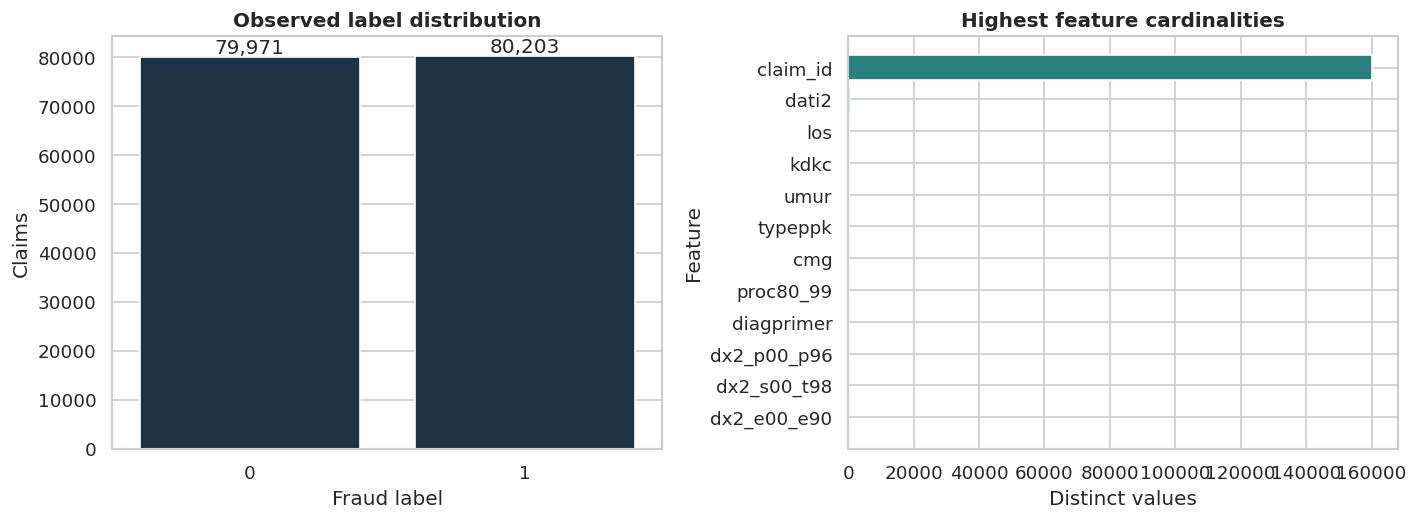

*Figure 4.1. Observed target distribution and the highest-cardinality fields in the labeled data.*

**Question.** What data-quality conditions constrain a defensible model?

**Method.** Schema, missing/blank/special-code checks, robust numeric ranges, identifiers, exact duplicates, feature-signature duplicates, conflicting labels, category cardinality, and unseen evaluation levels were inspected before modeling.

**Result.** There are 160,174 labeled and 40,043 evaluation claims. The observed fraud share is 50.07%, which is approximately balanced; this is unusual for many operational fraud streams and is consistent with a curated or sampled competition set. The raw training matrix contains 0 missing cells, 0 blank strings, 76,189 values changed by whitespace normalization, 0 flagged special numeric codes, and 1 detected binary fields. 5 features contain at least one evaluation-only level. Repeated signatures cover 17,906 rows; 1,737 signatures contain both labels.

**Decision implication.** Whitespace normalization and unknown-level handling are mandatory. Repeated signatures justify grouped validation. Conflicting labels set an empirical ceiling for any deterministic feature-only rule and warn against interpreting every error as model failure. Pure IDs and constants remain excluded.

**Limitation / alternative explanation.** Plausibility rules flag 10 rows, but these are administrative checks rather than clinical adjudications. No outlier is removed solely because it is extreme, and the competition prevalence is not assumed to equal NHPA's operational prevalence.

In [16]:
target_counts = pd.Series(y).value_counts().sort_index()
whitespace_changes = 0
for column in train_raw.select_dtypes(include="object"):
    whitespace_changes += int(train_raw[column].astype("string").ne(train_raw[column].astype("string").str.strip()).sum())
high_cardinality = QUALITY_PROFILE.sort_values("cardinality", ascending=False).head(12)
unseen_features = int((QUALITY_PROFILE["test_only_levels"] > 0).sum())
plausibility_total = int(PLAUSIBILITY["flagged_claims"].sum())

show_table(DUPLICATE_SUMMARY, "4.1", "Duplicate, repeated-signature, and label-conflict audit", precision=0)
show_table(
    QUALITY_PROFILE.sort_values(["missing_pct", "cardinality"], ascending=False).head(15),
    "4.2", "Highest-priority completeness, cardinality, and train–test level checks",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, color=COLORS["navy"], ax=axes[0])
axes[0].set(title="Observed label distribution", xlabel="Fraud label", ylabel="Claims")
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}")
quality_plot = high_cardinality.sort_values("cardinality")
axes[1].barh(quality_plot["feature"], quality_plot["cardinality"], color=COLORS["teal"])
axes[1].set(title="Highest feature cardinalities", xlabel="Distinct values", ylabel="Feature")
finish_figure(fig, "4.1", "Observed target distribution and the highest-cardinality fields in the labeled data.")

balance_interpretation = (
    "approximately balanced; this is unusual for many operational fraud streams and is consistent with a curated or sampled competition set"
    if 0.40 <= y.mean() <= 0.60 else
    "materially imbalanced, so ranking metrics and minority-class stability require particular attention"
)
report_block(
    "What data-quality conditions constrain a defensible model?",
    "Schema, missing/blank/special-code checks, robust numeric ranges, identifiers, exact duplicates, feature-signature duplicates, conflicting labels, category cardinality, and unseen evaluation levels were inspected before modeling.",
    f"There are {len(train_raw):,} labeled and {len(test_raw):,} evaluation claims. The observed fraud share is {y.mean():.2%}, which is {balance_interpretation}. The raw training matrix contains {REPORT_FACTS['missing_cells']:,} missing cells, {REPORT_FACTS['blank_cells']:,} blank strings, {whitespace_changes:,} values changed by whitespace normalization, {special_code_count:,} flagged special numeric codes, and {len(BINARY_PROFILE):,} detected binary fields. {unseen_features} features contain at least one evaluation-only level. Repeated signatures cover {REPORT_FACTS['repeated_signature_rows']:,} rows; {REPORT_FACTS['conflicting_signatures']:,} signatures contain both labels.",
    "Whitespace normalization and unknown-level handling are mandatory. Repeated signatures justify grouped validation. Conflicting labels set an empirical ceiling for any deterministic feature-only rule and warn against interpreting every error as model failure. Pure IDs and constants remain excluded.",
    f"Plausibility rules flag {plausibility_total:,} rows, but these are administrative checks rather than clinical adjudications. No outlier is removed solely because it is extreme, and the competition prevalence is not assumed to equal NHPA's operational prevalence."
)


## 4.2 Fraud Distribution and Important Associations


**Table 4.3. Largest categorical label associations (descriptive, BH-adjusted)**

,feature,test,p_value,effect_size,effect,levels_after_pooling,p_bh
1,dati2,chi-square,0.0000,0.2983,Cramer's V,452,0.0000
0,kdkc,chi-square,0.0000,0.2509,Cramer's V,126,0.0000
2,typeppk,chi-square,0.0000,0.1229,Cramer's V,25,0.0000
5,cmg,chi-square,0.0000,0.1122,Cramer's V,23,0.0000
6,severitylevel,chi-square,0.0000,0.0777,Cramer's V,4,0.0000
4,jnspelsep,chi-square,0.0000,0.0533,Cramer's V,2,0.0000
7,diagprimer,chi-square,0.0000,0.0194,Cramer's V,21,0.0000
3,jkpst,chi-square,0.0000,0.0114,Cramer's V,2,0.0000


**Table 4.4. Largest numeric label associations and effect sizes**

,feature,test,p_value,effect_size,signed_rank_biserial,KS,fraud_median,nonfraud_median,p_bh
1,los,Mann–Whitney U,0.0000,0.0757,-0.0757,0.0805,0.0000,0.0000,0.0000
38,proc80_99,Mann–Whitney U,0.0000,0.0338,-0.0338,0.0285,0.0000,0.0000,0.0000
0,umur,Mann–Whitney U,0.0000,0.0177,0.0177,0.0153,39.0000,38.0000,0.0000
28,proc39_45,Mann–Whitney U,0.0000,0.0115,-0.0115,0.0115,0.0000,0.0000,0.0000
35,proc74_75,Mann–Whitney U,0.0000,0.0102,-0.0102,0.0102,0.0000,0.0000,0.0000
21,dx2_z00_z99,Mann–Whitney U,0.0000,0.0100,-0.0100,0.0100,0.0000,0.0000,0.0000
5,dx2_e00_e90,Mann–Whitney U,0.0000,0.0070,-0.0070,0.0069,0.0000,0.0000,0.0000
10,dx2_i00_i99,Mann–Whitney U,0.0000,0.0066,-0.0066,0.0066,0.0000,0.0000,0.0000
16,dx2_p00_p96,Mann–Whitney U,0.0000,0.0058,-0.0058,0.0058,0.0000,0.0000,0.0000
14,dx2_n00_n99,Mann–Whitney U,0.0000,0.0055,0.0055,0.0055,0.0000,0.0000,0.0000


**Table 4.5. Observed subgroup fraud rates with 95% Wilson intervals**

,attribute,group,claims,frauds,fraud_rate,ci_low,ci_high
0,gender,L,74284,37650,0.5068,0.5032,0.5104
1,gender,P,85890,42553,0.4954,0.4921,0.4988
2,age_group,60+,30814,15812,0.5131,0.5076,0.5187
3,age_group,40–59,47844,24021,0.5021,0.4976,0.5065
4,age_group,18–39,41391,20605,0.4978,0.4930,0.5026
5,age_group,0–17,40125,19765,0.4926,0.4877,0.4975


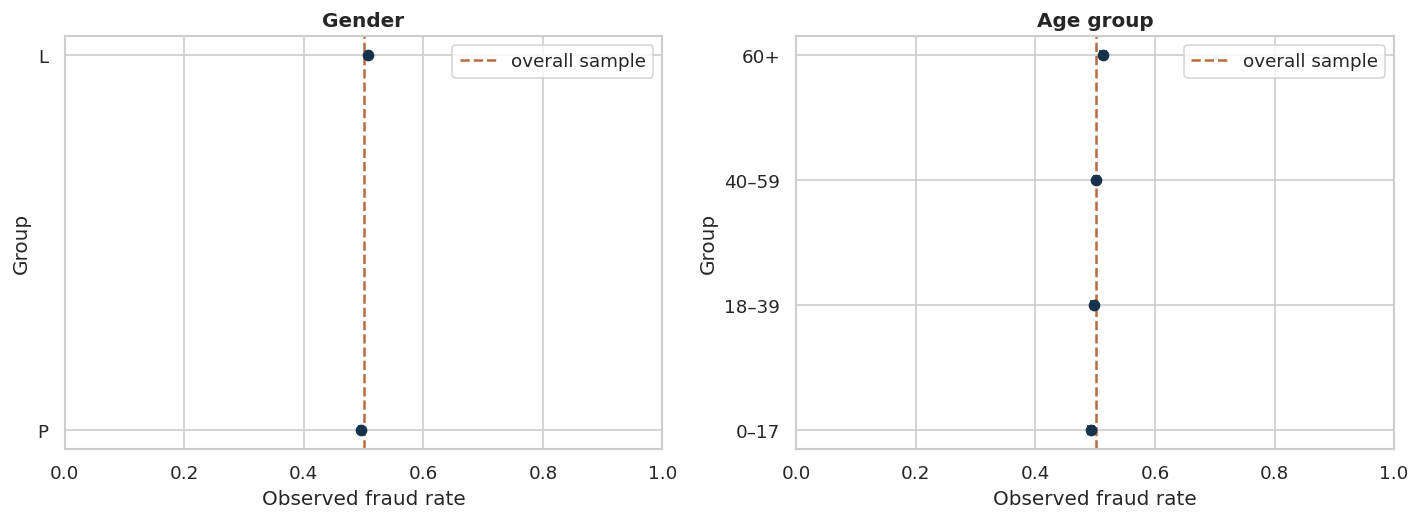

*Figure 4.2. Observed label prevalence by protected subgroup; bars are 95% Wilson intervals.*

**Question.** Which recorded characteristics are associated with the fraud label, and how strong is the evidence?

**Method.** Categorical chi-square tests are paired with Cramér's V; numeric Mann–Whitney tests are paired with rank-biserial and KS effects; all screened p-values are BH-adjusted. Protected-group rates include Wilson uncertainty.

**Result.** The largest categorical effect is `dati2` (Cramér's V=0.298, BH-adjusted p=0). The largest numeric rank effect is `los` (absolute rank-biserial=0.076, KS=0.080, BH-adjusted p=2.89e-219).

**Decision implication.** Features with non-trivial effects merit modeling and investigative interpretation; subgroup patterns motivate the later false-positive exposure analysis, not a group-specific decision rule.

**Limitation / alternative explanation.** These are unadjusted associations in a selected labeled sample. Statistical significance may reflect sample size, and neither a feature effect nor a subgroup rate establishes fraud causation or wrongdoing by an individual.

In [17]:
def wilson_interval(successes, trials, confidence=0.95):
    if trials == 0:
        return np.nan, np.nan
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p = successes / trials
    denominator = 1 + z**2 / trials
    center = (p + z**2 / (2 * trials)) / denominator
    half = z * math.sqrt(p * (1 - p) / trials + z**2 / (4 * trials**2)) / denominator
    return max(0, center - half), min(1, center + half)


def subgroup_rate_table(values, target, attribute):
    frame = pd.DataFrame({"group": pd.Series(values).astype("string").fillna("Missing"), "label": target})
    summary = frame.groupby("group", observed=True)["label"].agg(claims="size", frauds="sum", fraud_rate="mean").reset_index()
    intervals = [wilson_interval(int(row.frauds), int(row.claims)) for row in summary.itertuples()]
    summary["ci_low"] = [value[0] for value in intervals]
    summary["ci_high"] = [value[1] for value in intervals]
    summary.insert(0, "attribute", attribute)
    return summary.sort_values("fraud_rate", ascending=False)


gender_rates = subgroup_rate_table(PROTECTED["gender"], y, "gender")
age_rates = subgroup_rate_table(age_groups(PROTECTED["age"]), y, "age_group")
SUBGROUP_RATES = pd.concat([gender_rates, age_rates], ignore_index=True)
show_table(CATEGORICAL_ASSOCIATIONS.head(10), "4.3", "Largest categorical label associations (descriptive, BH-adjusted)")
show_table(NUMERIC_ASSOCIATIONS.head(10), "4.4", "Largest numeric label associations and effect sizes")
show_table(SUBGROUP_RATES, "4.5", "Observed subgroup fraud rates with 95% Wilson intervals")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, table, title in ((axes[0], gender_rates, "Gender"), (axes[1], age_rates, "Age group")):
    plot = table.sort_values("fraud_rate")
    errors = np.vstack([plot["fraud_rate"] - plot["ci_low"], plot["ci_high"] - plot["fraud_rate"]])
    ax.errorbar(plot["fraud_rate"], plot["group"], xerr=errors, fmt="o", color=COLORS["navy"], capsize=3)
    ax.axvline(y.mean(), color=COLORS["orange"], ls="--", label="overall sample")
    ax.set(title=title, xlabel="Observed fraud rate", ylabel="Group", xlim=(0, 1))
    ax.legend()
finish_figure(fig, "4.2", "Observed label prevalence by protected subgroup; bars are 95% Wilson intervals.")

top_cat = CATEGORICAL_ASSOCIATIONS.iloc[0] if len(CATEGORICAL_ASSOCIATIONS) else None
top_num = NUMERIC_ASSOCIATIONS.iloc[0] if len(NUMERIC_ASSOCIATIONS) else None
association_result = []
if top_cat is not None:
    association_result.append(f"The largest categorical effect is `{top_cat.feature}` (Cramér's V={top_cat.effect_size:.3f}, BH-adjusted p={top_cat.p_bh:.3g}).")
if top_num is not None:
    association_result.append(f"The largest numeric rank effect is `{top_num.feature}` (absolute rank-biserial={top_num.effect_size:.3f}, KS={top_num.KS:.3f}, BH-adjusted p={top_num.p_bh:.3g}).")
report_block(
    "Which recorded characteristics are associated with the fraud label, and how strong is the evidence?",
    "Categorical chi-square tests are paired with Cramér's V; numeric Mann–Whitney tests are paired with rank-biserial and KS effects; all screened p-values are BH-adjusted. Protected-group rates include Wilson uncertainty.",
    " ".join(association_result) if association_result else "No non-constant feature produced an estimable association table.",
    "Features with non-trivial effects merit modeling and investigative interpretation; subgroup patterns motivate the later false-positive exposure analysis, not a group-specific decision rule.",
    "These are unadjusted associations in a selected labeled sample. Statistical significance may reflect sample size, and neither a feature effect nor a subgroup rate establishes fraud causation or wrongdoing by an individual."
)


## 4.3 Leakage and Proxy Audit


In [18]:
show_table(LEAKAGE_REGISTER, "4.6", "Feature-role, leakage, identifier, and proxy decision register")
show_table(UNIVARIATE_AUDIT.head(15), "4.7", "Highest fold-safe univariate Average Precision values")
show_table(DETERMINISTIC_LEVELS.head(15), "4.8", "Near-deterministic level coverage (minimum level support 20)")

top_univariate = UNIVARIATE_AUDIT.iloc[0]
suspicious_text = (
    "The empirical screen marked " + ", ".join(f"`{feature}`" for feature in SUSPICIOUS_SIGNAL_FEATURES) + " for ablation."
    if SUSPICIOUS_SIGNAL_FEATURES else
    "No retained raw feature crossed the predeclared extreme univariate or deterministic-coverage screen."
)
report_block(
    "Does performance depend on an identifier, post-outcome field, or suspicious proxy?",
    "Semantic availability was combined with uniqueness, fold-safe univariate AP, level-specific determinism, repeated signatures, later importance concentration, and protected/location ablations.",
    f"`claim_id` is unique alignment information and is excluded. The strongest single raw feature is `{top_univariate.feature}` with OOF AP={top_univariate.univariate_oof_AP:.4f}. {suspicious_text}",
    "Only semantically available claim information enters the main model. Protected and location variables are not presumed harmless: their incremental score and disparity effects are measured in Section 4.12.",
    "A high univariate score can be legitimate in a sampled competition dataset. Conversely, absence of an obvious leak does not rule out undocumented post-outcome semantics; the supplied feature dictionary and NHPA process owners remain necessary governance inputs."
)


**Table 4.6. Feature-role, leakage, identifier, and proxy decision register**

,feature_set,classification,decision,rationale
0,claim_id,identifier,excluded,unique row alignment key; no legitimate risk meaning
1,"dx2_koo_k93, dx2_u00_u99, procv00_v89",non-informative,excluded,constant in the labeled sample
2,"jkpst, umur, age_band, is_pediatric, is_older_adult",protected / proxy-sensitive,retain then ablate,evaluate direct and proxy reliance; never post-process by group
3,"kdkc, dati2, geo__facility",possible structural proxy,retain then ablate,"location may encode case mix, access, or institutional practice"
4,none,empirically suspicious,semantic review and ablation,"extreme univariate or near-deterministic behavior, if present"
5,"diagnosis, procedure, stay, service codes",claim information,retained,available within a submitted claim; effects remain associational


**Table 4.7. Highest fold-safe univariate Average Precision values**

,feature,univariate_oof_AP,uniqueness_ratio
1,dati2,0.6546,0.0030
0,kdkc,0.6276,0.0008
2,typeppk,0.5525,0.0002
7,cmg,0.5426,0.0001
8,severitylevel,0.5218,0.0000
6,los,0.5213,0.0008
5,jnspelsep,0.5147,0.0000
48,proc80_99,0.5106,0.0001
4,umur,0.5071,0.0007
3,jkpst,0.5039,0.0000


**Table 4.8. Near-deterministic level coverage (minimum level support 20)**

,feature,qualifying_levels,coverage
1,dati2,1,0.0001
0,kdkc,0,0.0000
2,typeppk,0,0.0000
3,jkpst,0,0.0000
4,umur,0,0.0000
5,jnspelsep,0,0.0000
6,los,0,0.0000
7,cmg,0,0.0000
8,severitylevel,0,0.0000
9,diagprimer,0,0.0000


**Question.** Does performance depend on an identifier, post-outcome field, or suspicious proxy?

**Method.** Semantic availability was combined with uniqueness, fold-safe univariate AP, level-specific determinism, repeated signatures, later importance concentration, and protected/location ablations.

**Result.** `claim_id` is unique alignment information and is excluded. The strongest single raw feature is `dati2` with OOF AP=0.6546. No retained raw feature crossed the predeclared extreme univariate or deterministic-coverage screen.

**Decision implication.** Only semantically available claim information enters the main model. Protected and location variables are not presumed harmless: their incremental score and disparity effects are measured in Section 4.12.

**Limitation / alternative explanation.** A high univariate score can be legitimate in a sampled competition dataset. Conversely, absence of an obvious leak does not rule out undocumented post-outcome semantics; the supplied feature dictionary and NHPA process owners remain necessary governance inputs.

## 4.4 Train–Test Distribution Assessment


**Table 4.9. Largest feature-level train–test distribution differences**

,feature,type,KS,abs_SMD,JS_divergence,unseen_test_levels,shift_magnitude
38,proc39_45,numeric,0.0018,0.0133,—,—,0.0133
17,dx2_h60_h95,numeric,0.0010,0.0126,—,—,0.0126
18,dx2_i00_i99,numeric,0.0021,0.0111,—,—,0.0111
46,proc76_77,numeric,0.0004,0.0108,—,—,0.0108
34,proc24_27,numeric,0.0006,0.0103,—,—,0.0103
39,proc46_51,numeric,0.0006,0.0103,—,—,0.0103
42,proc63_67,numeric,0.0008,0.0099,—,—,0.0099
35,proc28_28,numeric,0.0002,0.0094,—,—,0.0094
26,dx2_q00_q99,numeric,0.0003,0.0089,—,—,0.0089
36,proc29_31,numeric,0.0003,0.0073,—,—,0.0073


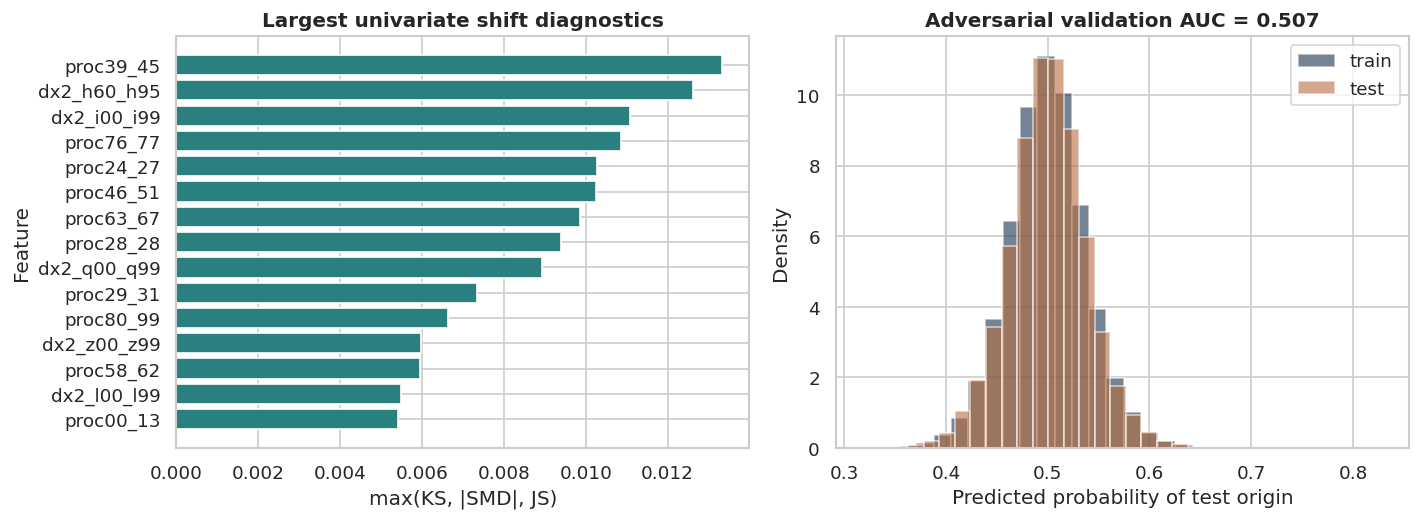

*Figure 4.3. Feature-level covariate shift and cross-validated adversarial train–test separability.*

**Question.** Does the evaluation covariate distribution resemble the labeled data?

**Method.** Numeric KS and standardized mean differences, categorical Jensen–Shannon divergence, unseen levels, and three-fold adversarial validation were triangulated.

**Result.** Adversarial AUC is 0.507, indicating weak separability. The largest univariate diagnostic is `proc39_45` at 0.013; 0 features contain evaluation-only levels.

**Decision implication.** Native unknown-category handling is required. Stronger shift increases the value of simple models, ablation stability, location holdout, and conservative calibration; it also lowers confidence in tiny CV differences.

**Limitation / alternative explanation.** Adversarial validation detects covariate differences only. It does not measure label shift, concept drift, or private-leaderboard behavior.

In [19]:
show_table(SHIFT_TABLE.head(15), "4.9", "Largest feature-level train–test distribution differences")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot = SHIFT_TABLE.head(15).sort_values("shift_magnitude")
axes[0].barh(plot["feature"], plot["shift_magnitude"], color=COLORS["teal"])
axes[0].set(title="Largest univariate shift diagnostics", xlabel="max(KS, |SMD|, JS)", ylabel="Feature")
axes[1].hist(ADVERSARIAL_PREDICTIONS[ADVERSARIAL_TARGET == 0], bins=30, alpha=0.6, density=True, label="train", color=COLORS["navy"])
axes[1].hist(ADVERSARIAL_PREDICTIONS[ADVERSARIAL_TARGET == 1], bins=30, alpha=0.6, density=True, label="test", color=COLORS["orange"])
axes[1].set(title=f"Adversarial validation AUC = {ADVERSARIAL_AUC:.3f}", xlabel="Predicted probability of test origin", ylabel="Density")
axes[1].legend()
finish_figure(fig, "4.3", "Feature-level covariate shift and cross-validated adversarial train–test separability.")

shift_interpretation = (
    "weak separability" if ADVERSARIAL_AUC < 0.60 else
    "detectable separability" if ADVERSARIAL_AUC < 0.75 else
    "strong separability"
)
top_shift = SHIFT_TABLE.iloc[0]
report_block(
    "Does the evaluation covariate distribution resemble the labeled data?",
    "Numeric KS and standardized mean differences, categorical Jensen–Shannon divergence, unseen levels, and three-fold adversarial validation were triangulated.",
    f"Adversarial AUC is {ADVERSARIAL_AUC:.3f}, indicating {shift_interpretation}. The largest univariate diagnostic is `{top_shift.feature}` at {top_shift.shift_magnitude:.3f}; {int((SHIFT_TABLE['unseen_test_levels'].fillna(0) > 0).sum())} features contain evaluation-only levels.",
    "Native unknown-category handling is required. Stronger shift increases the value of simple models, ablation stability, location holdout, and conservative calibration; it also lowers confidence in tiny CV differences.",
    "Adversarial validation detects covariate differences only. It does not measure label shift, concept drift, or private-leaderboard behavior."
)


## 4.5 Validation Strategy Evidence


**Table 4.10. Primary fold size, prevalence, and signature separation**

,fold,train_n,valid_n,train_fraud_rate,valid_fraud_rate,signature_overlap
0,1,128018,32156,0.5011,0.4993,0
1,2,128162,32012,0.5022,0.4948,0
2,3,128180,31994,0.5006,0.5012,0
3,4,128151,32023,0.5001,0.5033,0
4,5,128185,31989,0.4997,0.5050,0


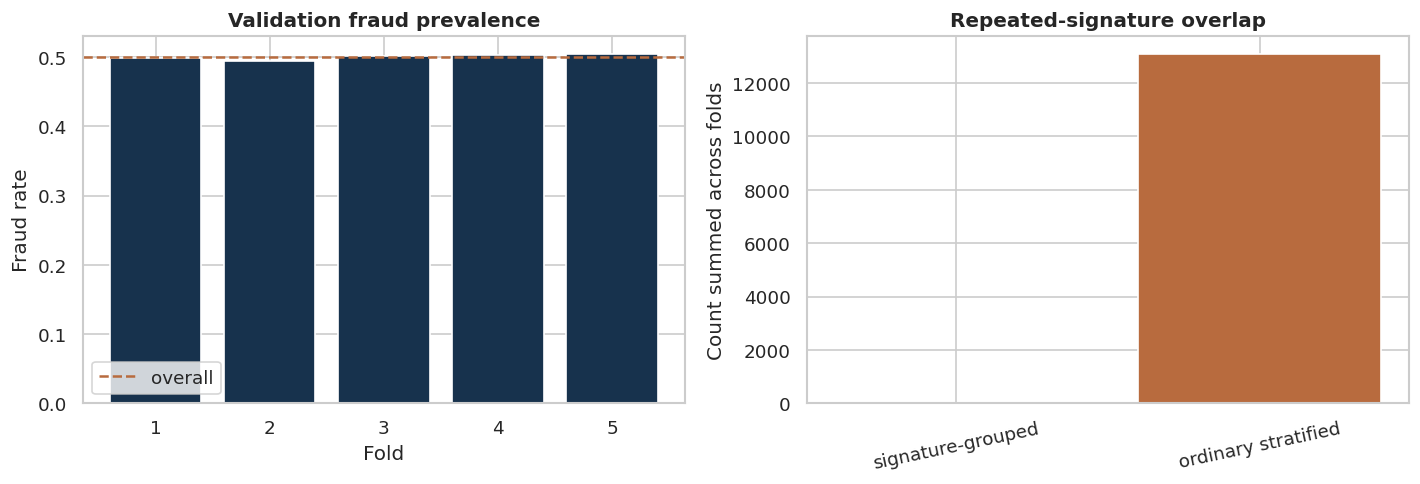

*Figure 4.4. Primary-fold label balance and repeated-signature leakage diagnostic.*

**Question.** Which validation design best protects against optimistic repeated-pattern performance?

**Method.** Identical cleaned feature signatures are assigned to a single stratified group fold; ordinary row stratification is retained only as a comparator.

**Result.** The primary design has 0 signature overlaps across train–validation boundaries. Ordinary stratification creates 13,092 counted overlaps. Fold fraud rates range from 49.48% to 50.50%.

**Decision implication.** All serious OOF comparisons use the grouped design. This is a more conservative test of generalization to distinct claim patterns; the later location holdout answers a separate transportability question.

**Limitation / alternative explanation.** A feature signature is not a policyholder or provider identity. In the absence of entity and time fields, the validation cannot fully reproduce future operational dependence.

In [20]:
show_table(VALIDATION_TABLE, "4.10", "Primary fold size, prevalence, and signature separation")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(VALIDATION_TABLE["fold"].astype(str), VALIDATION_TABLE["valid_fraud_rate"], color=COLORS["navy"])
axes[0].axhline(y.mean(), ls="--", color=COLORS["orange"], label="overall")
axes[0].set(title="Validation fraud prevalence", xlabel="Fold", ylabel="Fraud rate")
axes[0].legend()
axes[1].bar(["signature-grouped", "ordinary stratified"], [REPORT_FACTS["primary_signature_overlap"], REPORT_FACTS["ordinary_signature_overlap"]], color=[COLORS["teal"], COLORS["orange"]])
axes[1].set(title="Repeated-signature overlap", ylabel="Count summed across folds")
axes[1].tick_params(axis="x", rotation=12)
finish_figure(fig, "4.4", "Primary-fold label balance and repeated-signature leakage diagnostic.")

report_block(
    "Which validation design best protects against optimistic repeated-pattern performance?",
    "Identical cleaned feature signatures are assigned to a single stratified group fold; ordinary row stratification is retained only as a comparator.",
    f"The primary design has {REPORT_FACTS['primary_signature_overlap']:,} signature overlaps across train–validation boundaries. Ordinary stratification creates {REPORT_FACTS['ordinary_signature_overlap']:,} counted overlaps. Fold fraud rates range from {VALIDATION_TABLE['valid_fraud_rate'].min():.2%} to {VALIDATION_TABLE['valid_fraud_rate'].max():.2%}.",
    "All serious OOF comparisons use the grouped design. This is a more conservative test of generalization to distinct claim patterns; the later location holdout answers a separate transportability question.",
    "A feature signature is not a policyholder or provider identity. In the absence of entity and time fields, the validation cannot fully reproduce future operational dependence."
)


## 4.6 Baseline and Strong-Model Performance


**Table 4.11. Uncalibrated OOF model comparison under identical primary folds**

,model,NormalizedRecall@5%,AveragePrecision,Brier,CalibrationScore,ProtectionScore,TechnicalScore,ROC_AUC,LogLoss,fold_std,runtime_minutes
0,CatBoost,0.9702,0.8234,0.1722,0.8278,0.9992,0.9224,0.8221,0.5154,0.0032,8.3373
1,XGBoost,0.9527,0.7968,0.1833,0.8167,0.9978,0.9056,0.7989,0.5437,0.0040,0.8208
2,Fold prevalence,1.0000,0.4982,0.2500,0.7500,1.0000,0.8621,0.4961,0.6932,0.0008,0.0000
3,Logistic regression,0.8824,0.7328,0.2056,0.7944,0.9954,0.8506,0.7426,0.5973,0.0061,9.6496
4,Burden baseline,0.6020,0.5246,0.2487,0.7513,0.9907,0.6478,0.5377,0.6914,0.0010,0.0321


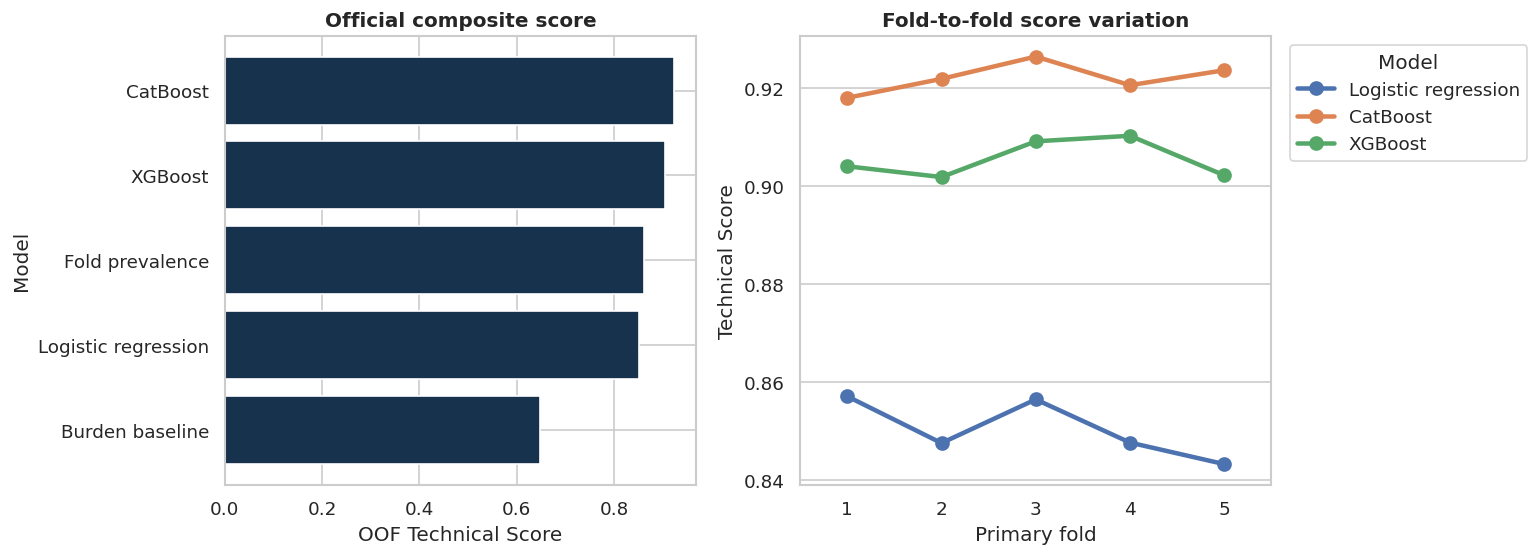

*Figure 4.5. OOF composite performance and fold stability before calibration.*

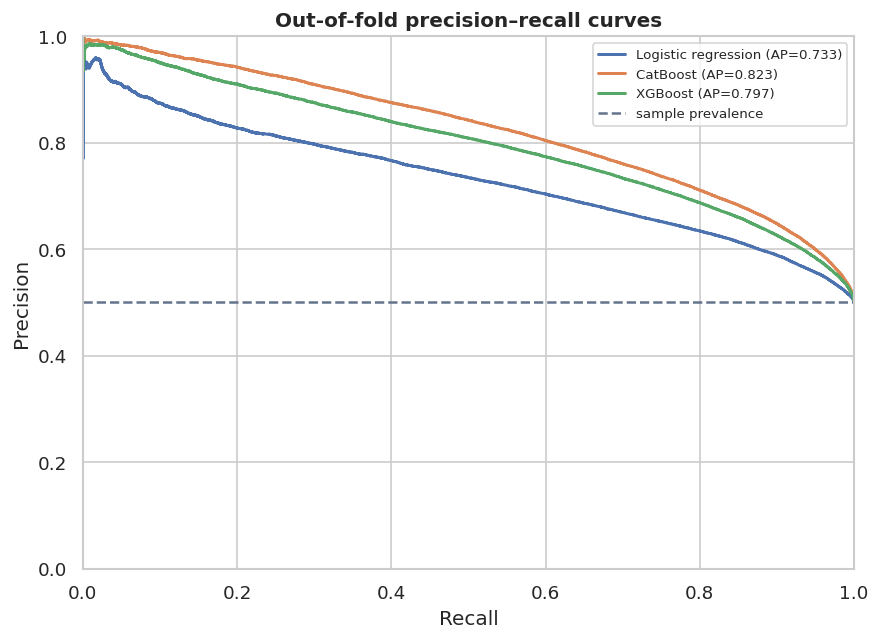

*Figure 4.6. OOF precision–recall curves under signature-grouped validation.*

**Question.** How much predictive value is added by progressively stronger models?

**Method.** Five signature-grouped OOF folds, identical feature availability, early stopping for boosted trees, and the exact official composite were used for every serious comparison.

**Result.** The highest uncalibrated composite is `CatBoost` at 0.92236 (Normalized Recall@5%=0.9702, AP=0.8234, Brier=0.1722). The fold-prevalence score is 0.86213. No resampling or weighting was applied because the observed classes are not meaningfully imbalanced; ranking metrics still govern evaluation.

**Decision implication.** The strongest candidates proceed to honest calibration and the multi-criteria decision table. Fold variation and shift sensitivity are considered alongside the mean score.

**Limitation / alternative explanation.** OOF estimates remain conditional on the supplied labels and fold structure. A small score difference below observed fold/seed variation is not treated as a durable advantage.

In [21]:
performance_columns = [
    "model", "NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore",
    "ProtectionScore", "TechnicalScore", "ROC_AUC", "LogLoss", "fold_std", "runtime_minutes",
]
show_table(EXPERIMENT_REGISTRY[performance_columns], "4.11", "Uncalibrated OOF model comparison under identical primary folds")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
registry_plot = EXPERIMENT_REGISTRY.sort_values("TechnicalScore")
axes[0].barh(registry_plot["model"], registry_plot["TechnicalScore"], color=COLORS["navy"])
axes[0].set(title="Official composite score", xlabel="OOF Technical Score", ylabel="Model")
fold_plot = FOLD_METRICS[FOLD_METRICS["model"].isin(SERIOUS_MODELS)]
sns.pointplot(data=fold_plot, x="fold", y="TechnicalScore", hue="model", errorbar=None, ax=axes[1])
axes[1].set(title="Fold-to-fold score variation", xlabel="Primary fold", ylabel="Technical Score")
axes[1].legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
finish_figure(fig, "4.5", "OOF composite performance and fold stability before calibration.")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name in SERIOUS_MODELS:
    precision, recall, _ = precision_recall_curve(y, OOF_PREDICTIONS[name])
    ax.plot(recall, precision, lw=1.8, label=f"{name} (AP={average_precision_score(y, OOF_PREDICTIONS[name]):.3f})")
ax.axhline(y.mean(), color=COLORS["gray"], ls="--", label="sample prevalence")
ax.set(title="Out-of-fold precision–recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
finish_figure(fig, "4.6", "OOF precision–recall curves under signature-grouped validation.")

best_raw = EXPERIMENT_REGISTRY.iloc[0]
baseline = EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY["model"].eq("Fold prevalence")].iloc[0]
imbalance_action = (
    "A weighted sensitivity model was fitted because the observed minority share was below 20%."
    if minority_share < 0.20 else
    "No resampling or weighting was applied because the observed classes are not meaningfully imbalanced; ranking metrics still govern evaluation."
)
report_block(
    "How much predictive value is added by progressively stronger models?",
    "Five signature-grouped OOF folds, identical feature availability, early stopping for boosted trees, and the exact official composite were used for every serious comparison.",
    f"The highest uncalibrated composite is `{best_raw.model}` at {best_raw.TechnicalScore:.5f} (Normalized Recall@5%={best_raw['NormalizedRecall@5%']:.4f}, AP={best_raw.AveragePrecision:.4f}, Brier={best_raw.Brier:.4f}). The fold-prevalence score is {baseline.TechnicalScore:.5f}. {imbalance_action}",
    "The strongest candidates proceed to honest calibration and the multi-criteria decision table. Fold variation and shift sensitivity are considered alongside the mean score.",
    "OOF estimates remain conditional on the supplied labels and fold structure. A small score difference below observed fold/seed variation is not treated as a durable advantage."
)


## 4.7 Probability Calibration


**Table 4.12. Cross-fitted calibration comparison**

,model,calibration,Brier,CalibrationScore,AveragePrecision,NormalizedRecall@5%,ProtectionScore,TechnicalScore,unique_probabilities,largest_tie
4,CatBoost,sigmoid,0.1722,0.8278,0.8234,0.9699,0.9993,0.9222,156522,14
3,CatBoost,raw,0.1722,0.8278,0.8234,0.9702,0.9992,0.9224,149013,53
5,CatBoost,isotonic,0.1722,0.8278,0.8220,0.9709,0.9991,0.9225,728,1486
10,CatBoost–XGBoost blend,sigmoid,0.1718,0.8282,0.8239,0.9714,0.9989,0.9232,156522,14
11,CatBoost–XGBoost blend,isotonic,0.1718,0.8282,0.8226,0.9715,0.9988,0.9230,726,1661
9,CatBoost–XGBoost blend,raw,0.1721,0.8279,0.8239,0.9714,0.9988,0.9231,149015,53
2,Logistic regression,isotonic,0.2055,0.7945,0.7313,0.8815,0.9954,0.8498,611,1830
1,Logistic regression,sigmoid,0.2056,0.7944,0.7328,0.8824,0.9954,0.8506,156522,14
0,Logistic regression,raw,0.2056,0.7944,0.7328,0.8824,0.9954,0.8506,149015,53
7,XGBoost,sigmoid,0.1829,0.8171,0.7968,0.9527,0.9978,0.9057,156357,14


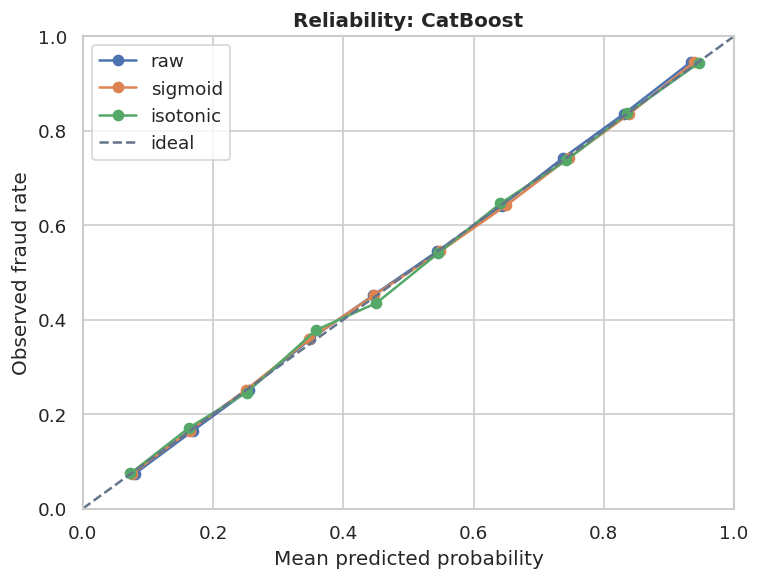

*Figure 4.7. Cross-fitted reliability curves for the ultimately selected candidate; equal-frequency bins.*

**Question.** Can the probability scale be improved without calibration leakage?

**Method.** Raw, sigmoid, and isotonic mappings were compared with a second cross-fitting layer; Brier improvement, ranking behavior, and tie size jointly determined the method.

**Result.** `sigmoid` was selected for `CatBoost`. Cross-fitted Brier changes from 0.17219 to 0.17218, while the composite changes from 0.92236 to 0.92223. Its monotone mapping preserves the audit ranking.

**Decision implication.** The final mapping is fitted on all OOF base predictions and then applied to evaluation predictions from models trained without evaluation labels.

**Limitation / alternative explanation.** If the competition sample prevalence differs from NHPA's operational prevalence, even cross-fitted sample calibration may not be operationally calibrated. A labeled production window is needed before probabilities are used as absolute risk estimates.

In [22]:
calibration_columns = [
    "model", "calibration", "Brier", "CalibrationScore", "AveragePrecision",
    "NormalizedRecall@5%", "ProtectionScore", "TechnicalScore", "unique_probabilities", "largest_tie",
]
show_table(CALIBRATION_COMPARISON[calibration_columns].sort_values(["model", "Brier"]), "4.12", "Cross-fitted calibration comparison")

def reliability_points(target, prediction, bins=10):
    frame = pd.DataFrame({"y": target, "p": prediction})
    frame["bin"] = pd.qcut(frame["p"].rank(method="first"), q=min(bins, frame["p"].nunique()), duplicates="drop")
    return frame.groupby("bin", observed=True).agg(mean_prediction=("p", "mean"), observed_rate=("y", "mean"), n=("y", "size")).reset_index(drop=True)


fig, ax = plt.subplots(figsize=(6.5, 5))
for method in ("raw", "sigmoid", "isotonic"):
    if FINAL_CHOICE in CALIBRATION_TABLES:
        _, predictions, _ = calibration_diagnostics(FINAL_CHOICE, OOF_PREDICTIONS[FINAL_CHOICE])
        values = predictions[method]
    else:
        values = cross_fitted_calibration(OOF_PREDICTIONS[FINAL_CHOICE], y, method, CFG.seed + 83)
    reliability = reliability_points(y, values)
    ax.plot(reliability["mean_prediction"], reliability["observed_rate"], marker="o", label=method)
ax.plot([0, 1], [0, 1], ls="--", color=COLORS["gray"], label="ideal")
ax.set(title=f"Reliability: {FINAL_CHOICE}", xlabel="Mean predicted probability", ylabel="Observed fraud rate", xlim=(0, 1), ylim=(0, 1))
ax.legend()
finish_figure(fig, "4.7", "Cross-fitted reliability curves for the ultimately selected candidate; equal-frequency bins.")

chosen_row = CALIBRATION_COMPARISON[
    CALIBRATION_COMPARISON["model"].eq(FINAL_CHOICE) & CALIBRATION_COMPARISON["calibration"].eq(FINAL_CALIBRATION_METHOD)
].iloc[0]
raw_row = CALIBRATION_COMPARISON[
    CALIBRATION_COMPARISON["model"].eq(FINAL_CHOICE) & CALIBRATION_COMPARISON["calibration"].eq("raw")
].iloc[0]
rank_note = (
    "Its monotone mapping preserves the audit ranking." if FINAL_CALIBRATION_METHOD == "sigmoid" else
    "Its non-parametric mapping may introduce tied plateaus, which were constrained by the selection rule." if FINAL_CALIBRATION_METHOD == "isotonic" else
    "Calibration was left unchanged because alternative mappings did not improve honest Brier performance."
)
report_block(
    "Can the probability scale be improved without calibration leakage?",
    "Raw, sigmoid, and isotonic mappings were compared with a second cross-fitting layer; Brier improvement, ranking behavior, and tie size jointly determined the method.",
    f"`{FINAL_CALIBRATION_METHOD}` was selected for `{FINAL_CHOICE}`. Cross-fitted Brier changes from {raw_row.Brier:.5f} to {chosen_row.Brier:.5f}, while the composite changes from {raw_row.TechnicalScore:.5f} to {chosen_row.TechnicalScore:.5f}. {rank_note}",
    "The final mapping is fitted on all OOF base predictions and then applied to evaluation predictions from models trained without evaluation labels.",
    "If the competition sample prevalence differs from NHPA's operational prevalence, even cross-fitted sample calibration may not be operationally calibrated. A labeled production window is needed before probabilities are used as absolute risk estimates."
)


## 4.8 Final Candidate Selection


In [23]:
decision_columns = [
    "selected", "candidate", "calibration", "NormalizedRecall@5%", "AveragePrecision", "Brier",
    "ProtectionScore", "TechnicalScore", "fold_std", "prediction_shift_KS", "complexity", "explainability",
]
show_table(MODEL_DECISION_TABLE[decision_columns], "4.13", "Multi-criterion final model decision table")

blend_text = "No blend was evaluated because both strong component predictions were unavailable."
if BLEND_EVIDENCE:
    blend_text = (
        f"The component correlation is {BLEND_EVIDENCE['correlation']:.4f}; cross-fitted blend gain is "
        f"{BLEND_EVIDENCE['global_gain_over_best_single']:+.5f} versus the best single candidate, it wins "
        f"{BLEND_EVIDENCE['fold_wins']}/{CFG.folds} component-comparison folds, "
        f"and its deployable CatBoost weight is {BLEND_EVIDENCE['final_weight']:.2f}. "
        f"It {'passes' if BLEND_EVIDENCE['eligible'] else 'does not pass'} the predeclared eligibility rule."
    )
report_block(
    "Which candidate offers the strongest defensible trade-off rather than merely the largest mean score?",
    "The decision table combines all official components, fold variation, calibration, train–test prediction-distribution KS, implementation complexity, explanation route, prediction diversity, and a simplicity preference within 0.002 composite points.",
    f"The selected candidate is **{FINAL_CHOICE}** with **{FINAL_CALIBRATION_METHOD}** calibration and OOF Technical Score **{FINAL_METRICS['TechnicalScore']:.5f}**. {blend_text}",
    "This candidate becomes the audit-allocation, fairness, explanation, robustness, and submission pipeline. A validated single-model fallback remains available in the experiment registry.",
    "The decision rule limits but cannot eliminate model-selection optimism. Private evaluation may favor another statistically tied candidate, so leaderboard feedback should not be used to alter individual rows or infer labels."
)


**Table 4.13. Multi-criterion final model decision table**

,selected,candidate,calibration,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore,fold_std,prediction_shift_KS,complexity,explainability
0,False,CatBoost–XGBoost blend,sigmoid,0.9714,0.8239,0.1718,0.9989,0.9232,0.0023,0.0104,higher,component-level
1,True,CatBoost,sigmoid,0.9699,0.8234,0.1722,0.9993,0.9222,0.0032,0.0108,medium,direct
2,False,XGBoost,sigmoid,0.9527,0.7968,0.1829,0.9978,0.9057,0.0041,0.0073,medium,direct
3,False,Logistic regression,sigmoid,0.8824,0.7328,0.2056,0.9954,0.8506,0.0059,0.0054,low,direct


**Question.** Which candidate offers the strongest defensible trade-off rather than merely the largest mean score?

**Method.** The decision table combines all official components, fold variation, calibration, train–test prediction-distribution KS, implementation complexity, explanation route, prediction diversity, and a simplicity preference within 0.002 composite points.

**Result.** The selected candidate is **CatBoost** with **sigmoid** calibration and OOF Technical Score **0.92223**. The component correlation is 0.8932; cross-fitted blend gain is +0.00094 versus the best single candidate, it wins 3/5 component-comparison folds, and its deployable CatBoost weight is 0.75. It does not pass the predeclared eligibility rule.

**Decision implication.** This candidate becomes the audit-allocation, fairness, explanation, robustness, and submission pipeline. A validated single-model fallback remains available in the experiment registry.

**Limitation / alternative explanation.** The decision rule limits but cannot eliminate model-selection optimism. Private evaluation may favor another statistically tied candidate, so leaderboard feedback should not be used to alter individual rows or infer labels.

## 4.9 Audit Allocation at 3%, 5%, and 7%


**Table 4.14. Audit allocation outcomes at the three official sensitivity capacities**

,strategy,capacity,K,fraud_captured,raw_recall,normalized_recall,audit_precision,legitimate_audits,audit_FPR,lift_over_random
0,CatBoost,0.0300,4805,4722.0000,0.0589,0.9827,0.9827,83.0000,0.0010,1.9626
1,CatBoost,0.0500,8008,7767.0000,0.0968,0.9699,0.9699,241.0000,0.0030,1.9370
2,CatBoost,0.0700,11212,10739.0000,0.1339,0.9578,0.9578,473.0000,0.0059,1.9129
3,Burden baseline,0.0300,4805,4805.0000,0.0599,1.0000,1.0000,0.0000,0.0000,1.9971
4,Burden baseline,0.0500,8008,4821.0000,0.0601,0.6020,0.6020,3187.0000,0.0399,1.2023
5,Burden baseline,0.0700,11212,5993.0000,0.0747,0.5345,0.5345,5219.0000,0.0653,1.0675
6,Logistic regression,0.0300,4805,4346.0000,0.0542,0.9045,0.9045,459.0000,0.0057,1.8063
7,Logistic regression,0.0500,8008,7066.0000,0.0881,0.8824,0.8824,942.0000,0.0118,1.7622
8,Logistic regression,0.0700,11212,9680.0000,0.1207,0.8634,0.8634,1532.0000,0.0192,1.7242
9,Random audit (expectation),0.0300,4805,2405.9798,0.0300,0.5007,0.5007,2399.0202,0.0300,1.0000


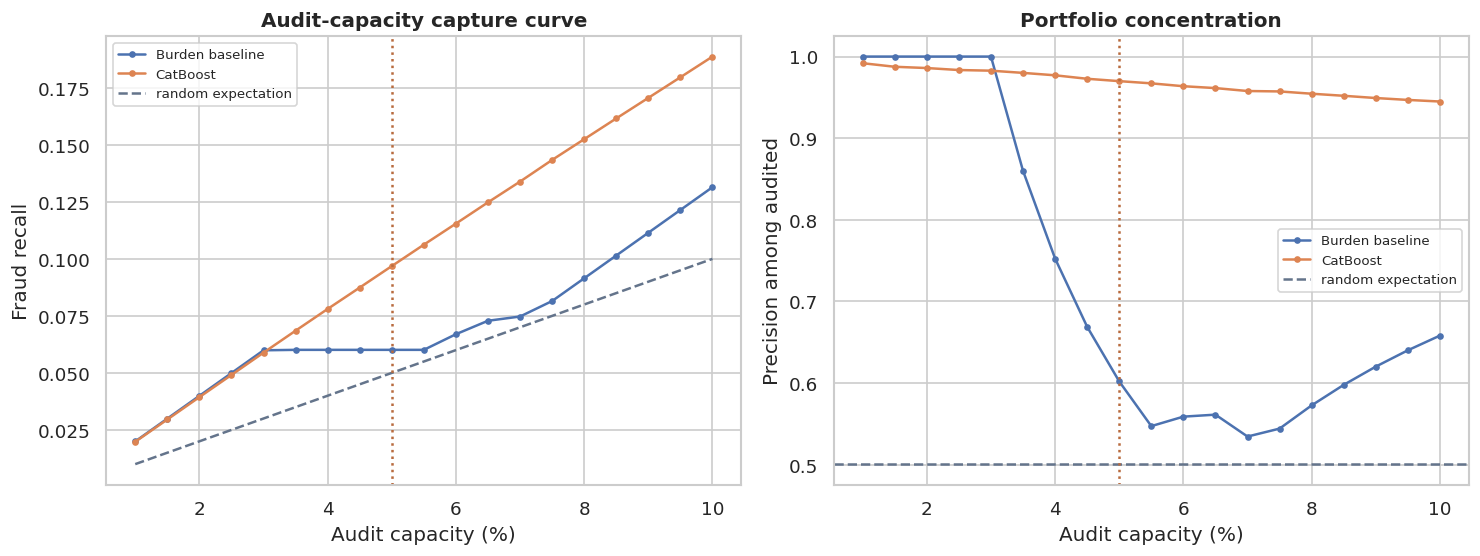

*Figure 4.8. Sensitivity of fraud capture and audit precision to capacity; dashed lines are random expectations.*

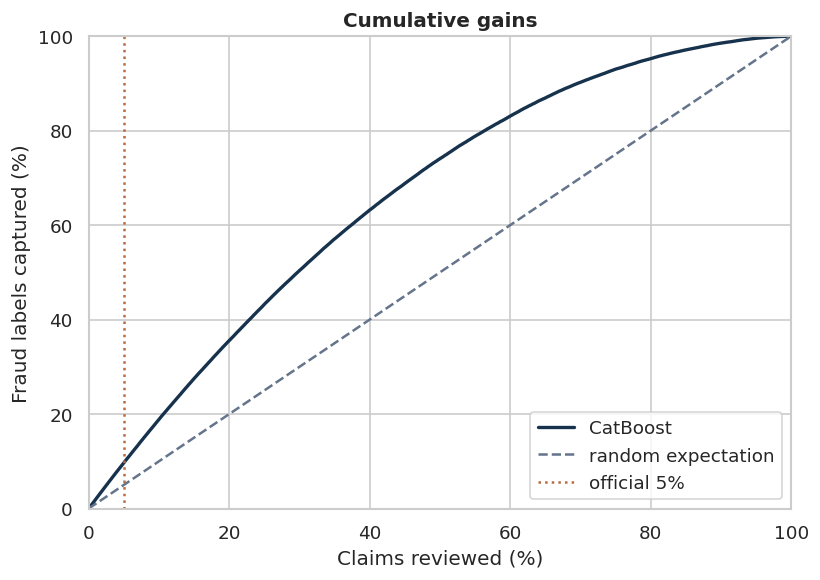

*Figure 4.9. OOF cumulative gains for the selected audit-ranking strategy.*

**Question.** What operational trade-off follows from 3%, 5%, and 7% audit capacity?

**Method.** Stable OOF rankings were evaluated at each capacity against random-audit expectation and a transparent low-dimensional burden heuristic baseline.

**Result.** At 3%, the model captures 4,722 fraud labels (5.89% recall) while auditing 83 legitimate claims. At the official 5%, it captures 7,767 (9.68%) with precision 96.99% and lift 1.94×. At 7%, capture rises to 10,739 (13.39%) while legitimate audits rise to 473.

**Decision implication.** The 5% portfolio is the competition decision point. The 3% and 7% results quantify the marginal benefit and policyholder burden if investigator capacity changes; they do not prescribe a cost-optimal capacity because no verified cost matrix was supplied.

**Limitation / alternative explanation.** Random values are expectations, not a realized random draw. Offline labels may omit undetected fraud, so apparent false positives can include mislabeled or unresolved cases and still require respectful human review.

In [24]:
def allocation_table(target, prediction, groups, capacities, strategy):
    rows = []
    for capacity in capacities:
        metric = official_metrics(target, prediction, groups, capacity)
        rows.append({
            "strategy": strategy, "capacity": capacity, "K": metric["K"],
            "fraud_captured": metric["TP_K"], "raw_recall": metric["Recall@capacity"],
            "normalized_recall": metric["NormalizedRecall@capacity"],
            "audit_precision": metric["Precision@capacity"],
            "legitimate_audits": metric["LegitimateAudits"], "audit_FPR": metric["AuditFPR"],
            "lift_over_random": metric["Lift@capacity"],
        })
    return pd.DataFrame(rows)


allocation_frames = [allocation_table(y, FINAL_OOF, PROTECTED, CFG.capacities, FINAL_CHOICE)]
for baseline_name in ("Burden baseline", "Logistic regression"):
    if baseline_name in OOF_PREDICTIONS:
        allocation_frames.append(allocation_table(y, OOF_PREDICTIONS[baseline_name], PROTECTED, CFG.capacities, baseline_name))

random_rows = []
for capacity in CFG.capacities:
    k = int(np.floor(capacity * len(y)))
    expected_fraud = k * y.mean()
    random_rows.append({
        "strategy": "Random audit (expectation)", "capacity": capacity, "K": k,
        "fraud_captured": expected_fraud, "raw_recall": k / len(y) if y.sum() else np.nan,
        "normalized_recall": min(1.0, (k / len(y)) / min(1, k / y.sum())) if k and y.sum() else np.nan,
        "audit_precision": y.mean(), "legitimate_audits": k - expected_fraud,
        "audit_FPR": k / len(y), "lift_over_random": 1.0,
    })
allocation_frames.append(pd.DataFrame(random_rows))
AUDIT_ALLOCATION = pd.concat(allocation_frames, ignore_index=True)
FINAL_ALLOCATION = AUDIT_ALLOCATION[AUDIT_ALLOCATION["strategy"].eq(FINAL_CHOICE)].copy()
show_table(AUDIT_ALLOCATION, "4.14", "Audit allocation outcomes at the three official sensitivity capacities")

capacity_grid = np.linspace(0.01, 0.10, 19)
capacity_curves = pd.concat([
    allocation_table(y, FINAL_OOF, PROTECTED, capacity_grid, FINAL_CHOICE),
    allocation_table(y, OOF_PREDICTIONS["Burden baseline"], PROTECTED, capacity_grid, "Burden baseline"),
], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for name, frame in capacity_curves.groupby("strategy"):
    axes[0].plot(frame["capacity"] * 100, frame["raw_recall"], marker="o", ms=3, label=name)
    axes[1].plot(frame["capacity"] * 100, frame["audit_precision"], marker="o", ms=3, label=name)
axes[0].plot(capacity_grid * 100, capacity_grid, ls="--", color=COLORS["gray"], label="random expectation")
axes[1].axhline(y.mean(), ls="--", color=COLORS["gray"], label="random expectation")
for ax, ylabel in zip(axes, ["Fraud recall", "Precision among audited"]):
    ax.axvline(5, color=COLORS["orange"], ls=":")
    ax.set(xlabel="Audit capacity (%)", ylabel=ylabel)
    ax.legend(fontsize=8)
axes[0].set_title("Audit-capacity capture curve")
axes[1].set_title("Portfolio concentration")
finish_figure(fig, "4.8", "Sensitivity of fraud capture and audit precision to capacity; dashed lines are random expectations.")

order = np.argsort(-FINAL_OOF, kind="mergesort")
cumulative_fraud = np.cumsum(y[order]) / max(y.sum(), 1)
cumulative_claims = np.arange(1, len(y) + 1) / len(y)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cumulative_claims * 100, cumulative_fraud * 100, color=COLORS["navy"], lw=2, label=FINAL_CHOICE)
ax.plot([0, 100], [0, 100], ls="--", color=COLORS["gray"], label="random expectation")
ax.axvline(5, color=COLORS["orange"], ls=":", label="official 5%")
ax.set(title="Cumulative gains", xlabel="Claims reviewed (%)", ylabel="Fraud labels captured (%)", xlim=(0, 100), ylim=(0, 100))
ax.legend()
finish_figure(fig, "4.9", "OOF cumulative gains for the selected audit-ranking strategy.")

row3 = FINAL_ALLOCATION.loc[np.isclose(FINAL_ALLOCATION["capacity"], 0.03)].iloc[0]
row5 = FINAL_ALLOCATION.loc[np.isclose(FINAL_ALLOCATION["capacity"], 0.05)].iloc[0]
row7 = FINAL_ALLOCATION.loc[np.isclose(FINAL_ALLOCATION["capacity"], 0.07)].iloc[0]
report_block(
    "What operational trade-off follows from 3%, 5%, and 7% audit capacity?",
    "Stable OOF rankings were evaluated at each capacity against random-audit expectation and a transparent low-dimensional burden heuristic baseline.",
    f"At 3%, the model captures {row3.fraud_captured:,.0f} fraud labels ({row3.raw_recall:.2%} recall) while auditing {row3.legitimate_audits:,.0f} legitimate claims. At the official 5%, it captures {row5.fraud_captured:,.0f} ({row5.raw_recall:.2%}) with precision {row5.audit_precision:.2%} and lift {row5.lift_over_random:.2f}×. At 7%, capture rises to {row7.fraud_captured:,.0f} ({row7.raw_recall:.2%}) while legitimate audits rise to {row7.legitimate_audits:,.0f}.",
    "The 5% portfolio is the competition decision point. The 3% and 7% results quantify the marginal benefit and policyholder burden if investigator capacity changes; they do not prescribe a cost-optimal capacity because no verified cost matrix was supplied.",
    "Random values are expectations, not a realized random draw. Offline labels may omit undetected fraud, so apparent false positives can include mislabeled or unresolved cases and still require respectful human review."
)


## 4.10 Explainability and Representative Claims

Explanations use a model fitted on the first primary training partition and evaluated on its untouched validation partition. The explanation anchor is CatBoost for a selected CatBoost/blend system; otherwise it is the selected single family. Global native importance is compared with held-out permutation AP loss. SHAP is computed on a bounded held-out sample when CatBoost is the anchor. All claims remain anonymized by competition identifier.


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


**Table 4.15. Global model-native importance for the held-out explanation anchor**

,feature,native_importance
9,diagprimer,12.1429
62,geo__facility,12.1329
0,kdkc,9.6576
60,cmg__severity,8.9745
7,cmg,7.0446
1,dati2,6.0234
4,umur,5.0765
61,service__facility,4.2428
8,severitylevel,4.2044
2,typeppk,3.7331


**Table 4.15b. Cross-fold stability of model-native global importance**

,comparison,Spearman_importance,top10_jaccard
0,primary folds 1 vs 2,0.9781,1.0000


**Table 4.16. Held-out permutation importance measured as AP loss**

,feature,AP_loss_mean,AP_loss_std
1,geo__facility,0.1192,0.0017
0,diagprimer,0.0735,0.0008
3,cmg__severity,0.0274,0.0021
8,severitylevel,0.0228,0.0012
4,cmg,0.0226,0.0006
2,kdkc,0.0137,0.0003
11,los,0.0095,0.0006
12,log1p_los,0.0046,0.0001
5,dati2,0.0041,0.0008
7,service__facility,0.0035,0.0002


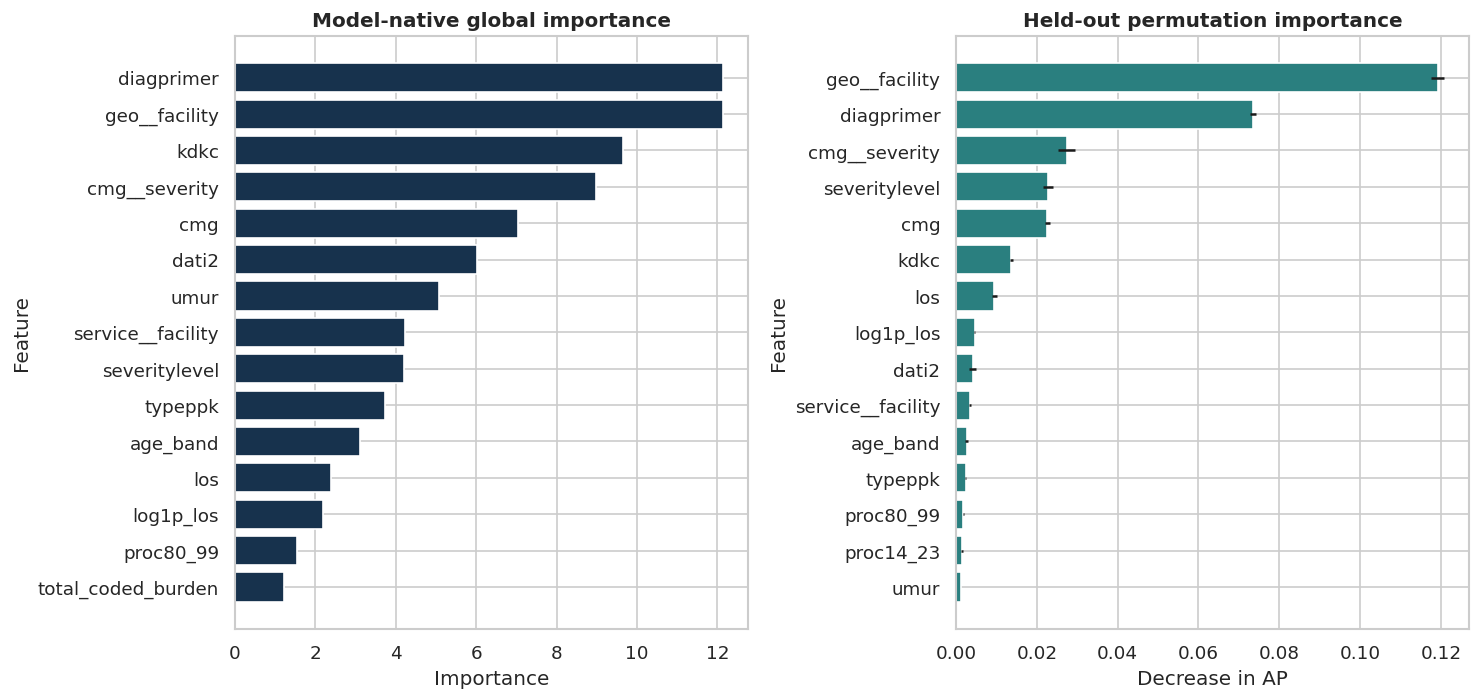

*Figure 4.10. Model-native and held-out permutation importance; neither measure is causal.*

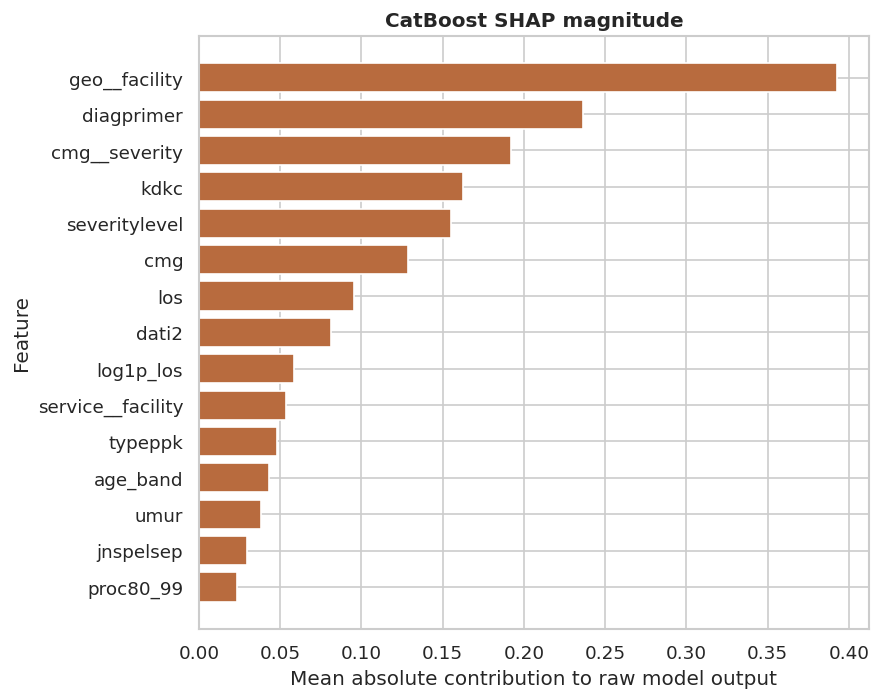

*Figure 4.11. Held-out CatBoost SHAP magnitude on a bounded sample; attribution is not causation.*

**Table 4.17. Largest local CatBoost SHAP contributions for the highest-scored held-out representative claim**

,feature,value,SHAP_contribution,abs_contribution
9,diagprimer,h60_h95,1.1296,1.1296
62,geo__facility,75__C,0.9720,0.9720
60,cmg__severity,J__0,0.7402,0.7402
7,cmg,J,0.6781,0.6781
0,kdkc,502,0.4656,0.4656
1,dati2,75,0.3880,0.3880
56,procedure_nonzero_groups,3,0.2404,0.2404
31,proc14_23,2,0.1918,0.1918
34,proc29_31,1,0.1792,0.1792
8,severitylevel,0,0.1488,0.1488


**Table 4.18. Anonymized held-out cases for investigator-oriented review**

,case_type,claim_id,observed_label,fold_probability
0,audited fraud label,CLM_286024439BBCFD,1,0.9967
1,audited legitimate label,CLM_01B5212510BC50,0,0.9846
2,highest-scored non-audited fraud label,CLM_1863E1ACFC52CC,1,0.9313


**Question.** Which recorded factors drive high-risk predictions, and can a specific ranking be explained?

**Method.** A held-out anchor model supplies model-native importance, repeated permutation AP loss, bounded-sample SHAP when available, and representative audited/missed cases.

**Result.** The leading native feature is `diagprimer`; the largest held-out permutation effect is `geo__facility`. Cross-fold importance Spearman correlation is 0.978 and top-10 Jaccard overlap is 1.000. No single feature exceeds 50% of native importance. Agreement or disagreement is visible in Tables 4.15–4.16. Table 4.17 reports signed CatBoost SHAP contributions for one high-scored claim, while Table 4.18 includes a true-positive, false-positive, and missed-fraud review case when each exists.

**Decision implication.** Investigators should see the probability, raw supporting fields, and the largest case-level drivers. A driver is a prompt to inspect evidence, never an independent rejection reason. Importance concentration in a suspicious/proxy feature triggers the documented ablation and process-owner review.

**Limitation / alternative explanation.** Correlated features can substitute for one another under permutation and split attribution under SHAP. All explanations describe this fitted model on this sample, not causal mechanisms or individual intent.

In [25]:
def predict_artifact(kind, artifact, frame, features):
    categorical = [c for c in features if c in CATEGORICAL_COLUMNS]
    if kind == "CatBoost":
        return artifact.predict_proba(catboost_ready(frame[features], categorical))[:, 1]
    if kind == "XGBoost":
        transformed = artifact["transformer"].transform(frame[features])
        return artifact["model"].predict_proba(transformed)[:, 1]
    return artifact.predict_proba(frame[features])[:, 1]


EXPLANATION_NAME = "CatBoost" if FINAL_CHOICE in {"CatBoost", "CatBoost–XGBoost blend"} else FINAL_CHOICE
EXPLANATION_KIND = MODEL_ARTIFACTS[EXPLANATION_NAME]["kind"]
EXPLANATION_FEATURES = MODEL_ARTIFACTS[EXPLANATION_NAME]["features"]
explain_train_idx, explain_valid_idx = PRIMARY_SPLITS[0]
explanation_weight_mode = MODEL_ARTIFACTS[EXPLANATION_NAME].get("cv_weight")
explanation_weight = (
    float((y[explain_train_idx] == 0).sum() / max((y[explain_train_idx] == 1).sum(), 1))
    if explanation_weight_mode == "balanced" else explanation_weight_mode
)
explain_prediction, _, EXPLANATION_ARTIFACT, _ = fit_predict_fold(
    EXPLANATION_KIND, X.iloc[explain_train_idx], y[explain_train_idx],
    X.iloc[explain_valid_idx], y[explain_valid_idx], None,
    EXPLANATION_FEATURES, CFG.seed + 901, weight=explanation_weight,
)

native_importance = None
if EXPLANATION_KIND == "CatBoost":
    native_importance = pd.DataFrame({
        "feature": EXPLANATION_FEATURES,
        "native_importance": EXPLANATION_ARTIFACT.get_feature_importance(type="FeatureImportance"),
    }).sort_values("native_importance", ascending=False)
elif EXPLANATION_KIND == "XGBoost":
    transformed_features = [c for c in EXPLANATION_FEATURES if c in CATEGORICAL_COLUMNS] + [c for c in EXPLANATION_FEATURES if c not in CATEGORICAL_COLUMNS]
    native_importance = pd.DataFrame({
        "feature": transformed_features,
        "native_importance": EXPLANATION_ARTIFACT["model"].feature_importances_,
    }).sort_values("native_importance", ascending=False)

EXPLANATION_STABILITY = pd.DataFrame([{
    "comparison": "not estimable for this anchor family",
    "Spearman_importance": np.nan,
    "top10_jaccard": np.nan,
}])
if native_importance is not None and len(PRIMARY_SPLITS) > 1:
    stability_train_idx, stability_valid_idx = PRIMARY_SPLITS[1]
    stability_weight = (
        float((y[stability_train_idx] == 0).sum() / max((y[stability_train_idx] == 1).sum(), 1))
        if explanation_weight_mode == "balanced" else explanation_weight_mode
    )
    _, _, stability_artifact, _ = fit_predict_fold(
        EXPLANATION_KIND, X.iloc[stability_train_idx], y[stability_train_idx],
        X.iloc[stability_valid_idx], y[stability_valid_idx], None,
        EXPLANATION_FEATURES, CFG.seed + 902, weight=stability_weight,
    )
    if EXPLANATION_KIND == "CatBoost":
        second_importance = pd.DataFrame({
            "feature": EXPLANATION_FEATURES,
            "second_importance": stability_artifact.get_feature_importance(type="FeatureImportance"),
        })
    else:
        transformed_features = [c for c in EXPLANATION_FEATURES if c in CATEGORICAL_COLUMNS] + [c for c in EXPLANATION_FEATURES if c not in CATEGORICAL_COLUMNS]
        second_importance = pd.DataFrame({
            "feature": transformed_features,
            "second_importance": stability_artifact["model"].feature_importances_,
        })
    aligned_importance = native_importance.merge(second_importance, on="feature", how="outer").fillna(0)
    rank_correlation = stats.spearmanr(
        aligned_importance["native_importance"], aligned_importance["second_importance"]
    ).statistic
    first_top = set(native_importance.head(10)["feature"])
    second_top = set(second_importance.nlargest(10, "second_importance")["feature"])
    EXPLANATION_STABILITY = pd.DataFrame([{
        "comparison": "primary folds 1 vs 2",
        "Spearman_importance": rank_correlation,
        "top10_jaccard": len(first_top & second_top) / max(len(first_top | second_top), 1),
    }])

importance_concentration_feature = None
if native_importance is not None and native_importance["native_importance"].sum() > 0:
    leading_share = float(native_importance["native_importance"].iloc[0] / native_importance["native_importance"].sum())
    if leading_share >= 0.50:
        importance_concentration_feature = str(native_importance["feature"].iloc[0])
        SUSPICIOUS_SIGNAL_FEATURES = sorted(set(SUSPICIOUS_SIGNAL_FEATURES + [importance_concentration_feature]))
REPORT_FACTS["importance_concentration_feature"] = importance_concentration_feature

permutation_candidates = native_importance.head(20)["feature"].tolist() if native_importance is not None else list(EXPLANATION_FEATURES)
rng = np.random.default_rng(CFG.seed)
base_ap = average_precision_score(y[explain_valid_idx], explain_prediction)
permutation_rows = []
for feature in permutation_candidates:
    losses = []
    for repeat in range(3):
        permuted = X.iloc[explain_valid_idx][EXPLANATION_FEATURES].copy()
        permuted[feature] = rng.permutation(permuted[feature].to_numpy())
        permuted_prediction = predict_artifact(EXPLANATION_KIND, EXPLANATION_ARTIFACT, permuted, EXPLANATION_FEATURES)
        losses.append(base_ap - average_precision_score(y[explain_valid_idx], permuted_prediction))
    permutation_rows.append({"feature": feature, "AP_loss_mean": np.mean(losses), "AP_loss_std": np.std(losses, ddof=1)})
PERMUTATION_IMPORTANCE = pd.DataFrame(permutation_rows).sort_values("AP_loss_mean", ascending=False)

show_table(
    native_importance.head(20) if native_importance is not None else PERMUTATION_IMPORTANCE.head(20),
    "4.15",
    "Global model-native importance for the held-out explanation anchor"
    if native_importance is not None else "Global held-out permutation importance for the explanation anchor",
)
show_table(EXPLANATION_STABILITY, "4.15b", "Cross-fold stability of model-native global importance")
show_table(PERMUTATION_IMPORTANCE.head(20), "4.16", "Held-out permutation importance measured as AP loss")

perm_plot = PERMUTATION_IMPORTANCE.head(15).sort_values("AP_loss_mean")
if native_importance is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
    native_plot = native_importance.head(15).sort_values("native_importance")
    axes[0].barh(native_plot["feature"], native_plot["native_importance"], color=COLORS["navy"])
    axes[0].set(title="Model-native global importance", xlabel="Importance", ylabel="Feature")
    permutation_axis = axes[1]
else:
    fig, permutation_axis = plt.subplots(figsize=(7.5, 6))
permutation_axis.barh(perm_plot["feature"], perm_plot["AP_loss_mean"], xerr=perm_plot["AP_loss_std"], color=COLORS["teal"])
permutation_axis.set(title="Held-out permutation importance", xlabel="Decrease in AP", ylabel="Feature")
finish_figure(
    fig, "4.10",
    "Model-native and held-out permutation importance; neither measure is causal."
    if native_importance is not None else "Held-out permutation importance; it is predictive, not causal.",
)

SHAP_IMPORTANCE = pd.DataFrame()
LOCAL_EXPLANATION = pd.DataFrame()
local_explanation_method = "one-feature reference replacement"
if EXPLANATION_KIND == "CatBoost":
    sample_size = min(CFG.shap_sample, len(explain_valid_idx))
    sample_positions = rng.choice(len(explain_valid_idx), sample_size, replace=False)
    shap_index = explain_valid_idx[sample_positions]
    explanation_cats = [c for c in EXPLANATION_FEATURES if c in CATEGORICAL_COLUMNS]
    shap_frame = catboost_ready(X.iloc[shap_index][EXPLANATION_FEATURES], explanation_cats)
    shap_values = EXPLANATION_ARTIFACT.get_feature_importance(
        Pool(shap_frame, cat_features=explanation_cats), type="ShapValues"
    )
    contributions = shap_values[:, :-1]
    SHAP_IMPORTANCE = pd.DataFrame({
        "feature": EXPLANATION_FEATURES,
        "mean_abs_SHAP": np.abs(contributions).mean(axis=0),
    }).sort_values("mean_abs_SHAP", ascending=False)
    shap_plot = SHAP_IMPORTANCE.head(15).sort_values("mean_abs_SHAP")
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.barh(shap_plot["feature"], shap_plot["mean_abs_SHAP"], color=COLORS["orange"])
    ax.set(title="CatBoost SHAP magnitude", xlabel="Mean absolute contribution to raw model output", ylabel="Feature")
    finish_figure(fig, "4.11", "Held-out CatBoost SHAP magnitude on a bounded sample; attribution is not causation.")

    representative_position = int(np.argmax(explain_prediction))
    representative_index = explain_valid_idx[representative_position]
    representative_frame = catboost_ready(X.iloc[[representative_index]][EXPLANATION_FEATURES], explanation_cats)
    local_values = EXPLANATION_ARTIFACT.get_feature_importance(
        Pool(representative_frame, cat_features=explanation_cats), type="ShapValues"
    )[0, :-1]
    LOCAL_EXPLANATION = pd.DataFrame({
        "feature": EXPLANATION_FEATURES,
        "value": [representative_frame.iloc[0][c] for c in EXPLANATION_FEATURES],
        "SHAP_contribution": local_values,
    }).assign(abs_contribution=lambda d: d["SHAP_contribution"].abs()).sort_values("abs_contribution", ascending=False).head(12)
    local_explanation_method = "CatBoost SHAP contribution"

if LOCAL_EXPLANATION.empty:
    representative_position = int(np.argmax(explain_prediction))
    representative_index = explain_valid_idx[representative_position]
    representative_frame = X.iloc[[representative_index]][EXPLANATION_FEATURES].copy()
    reference_frame = X.iloc[explain_train_idx][EXPLANATION_FEATURES]
    local_rows = []
    for feature in EXPLANATION_FEATURES:
        if feature in CATEGORICAL_COLUMNS:
            mode = reference_frame[feature].mode(dropna=True)
            reference_value = mode.iloc[0] if len(mode) else "__MISSING__"
        else:
            reference_value = pd.to_numeric(reference_frame[feature], errors="coerce").median()
        perturbed = representative_frame.copy()
        perturbed.loc[:, feature] = reference_value
        perturbed_probability = float(predict_artifact(
            EXPLANATION_KIND, EXPLANATION_ARTIFACT, perturbed, EXPLANATION_FEATURES
        )[0])
        change = float(explain_prediction[representative_position] - perturbed_probability)
        local_rows.append({
            "feature": feature, "value": representative_frame.iloc[0][feature],
            "reference_value": reference_value, "probability_change": change,
            "abs_contribution": abs(change),
        })
    LOCAL_EXPLANATION = pd.DataFrame(local_rows).sort_values("abs_contribution", ascending=False).head(12)

show_table(
    LOCAL_EXPLANATION, "4.17",
    f"Largest local {local_explanation_method}s for the highest-scored held-out representative claim",
)

selected_explain = top_k_mask(explain_prediction, 0.05)
representatives = []
for case_type, mask in {
    "audited fraud label": selected_explain & (y[explain_valid_idx] == 1),
    "audited legitimate label": selected_explain & (y[explain_valid_idx] == 0),
    "highest-scored non-audited fraud label": (~selected_explain) & (y[explain_valid_idx] == 1),
}.items():
    positions = np.flatnonzero(mask)
    if len(positions):
        pos = positions[np.argmax(explain_prediction[positions])]
        original = explain_valid_idx[pos]
        representatives.append({
            "case_type": case_type, ID_COL: train_raw.iloc[original][ID_COL],
            "observed_label": int(y[original]), "fold_probability": explain_prediction[pos],
        })
REPRESENTATIVE_CLAIMS = pd.DataFrame(representatives)
show_table(REPRESENTATIVE_CLAIMS, "4.18", "Anonymized held-out cases for investigator-oriented review")

top_native = native_importance.iloc[0]["feature"] if native_importance is not None and len(native_importance) else "not estimable"
top_permutation = PERMUTATION_IMPORTANCE.iloc[0]["feature"] if len(PERMUTATION_IMPORTANCE) else "not estimable"
stability_text = (
    f"Cross-fold importance Spearman correlation is {EXPLANATION_STABILITY['Spearman_importance'].iloc[0]:.3f} and top-10 Jaccard overlap is {EXPLANATION_STABILITY['top10_jaccard'].iloc[0]:.3f}."
    if EXPLANATION_STABILITY["Spearman_importance"].notna().any() else
    "Cross-fold native importance stability is not estimable for the selected explanation family."
)
concentration_text = (
    f"`{importance_concentration_feature}` exceeds 50% of native importance and is added to the suspicious-feature ablation."
    if importance_concentration_feature else
    "No single feature exceeds 50% of native importance."
)
report_block(
    "Which recorded factors drive high-risk predictions, and can a specific ranking be explained?",
    "A held-out anchor model supplies model-native importance, repeated permutation AP loss, bounded-sample SHAP when available, and representative audited/missed cases.",
    f"The leading native feature is `{top_native}`; the largest held-out permutation effect is `{top_permutation}`. {stability_text} {concentration_text} Agreement or disagreement is visible in Tables 4.15–4.16. Table 4.17 reports signed {local_explanation_method}s for one high-scored claim, while Table 4.18 includes a true-positive, false-positive, and missed-fraud review case when each exists.",
    "Investigators should see the probability, raw supporting fields, and the largest case-level drivers. A driver is a prompt to inspect evidence, never an independent rejection reason. Importance concentration in a suspicious/proxy feature triggers the documented ablation and process-owner review.",
    "Correlated features can substitute for one another under permutation and split attribution under SHAP. All explanations describe this fitted model on this sample, not causal mechanisms or individual intent."
)


## 4.11 Policyholder Protection at 3%, 5%, and 7%


**Table 4.19. Official policyholder-protection gaps by audit capacity**

,capacity,gender_gap,age_gap,ProtectionScore,eligible_gender_groups,eligible_age_groups
0,0.0300,0.0001,0.0008,0.9992,2,4
1,0.0500,0.0002,0.0007,0.9993,2,4
2,0.0700,0.0009,0.0029,0.9971,2,4


**Table 4.20. Group audit exposure, legitimate-audit FPR, eligibility, and Wilson intervals**

,attribute,group,population,nonfraud,audit_count,legitimate_audits,FPR,eligible,FPR_ci_low,FPR_ci_high,capacity
0,gender,L,74284,36634,2186,40,0.0011,True,0.0008,0.0015,0.0300
1,gender,P,85890,43337,2619,43,0.0010,True,0.0007,0.0013,0.0300
2,age_group,0–17,40125,20360,920,13,0.0006,True,0.0004,0.0011,0.0300
3,age_group,18–39,41391,20786,1196,21,0.0010,True,0.0007,0.0015,0.0300
4,age_group,40–59,47844,23823,1540,34,0.0014,True,0.0010,0.0020,0.0300
5,age_group,60+,30814,15002,1149,15,0.0010,True,0.0006,0.0016,0.0300
6,gender,L,74284,36634,3668,114,0.0031,True,0.0026,0.0037,0.0500
7,gender,P,85890,43337,4340,127,0.0029,True,0.0025,0.0035,0.0500
8,age_group,0–17,40125,20360,1620,54,0.0027,True,0.0020,0.0035,0.0500
9,age_group,18–39,41391,20786,2138,69,0.0033,True,0.0026,0.0042,0.0500


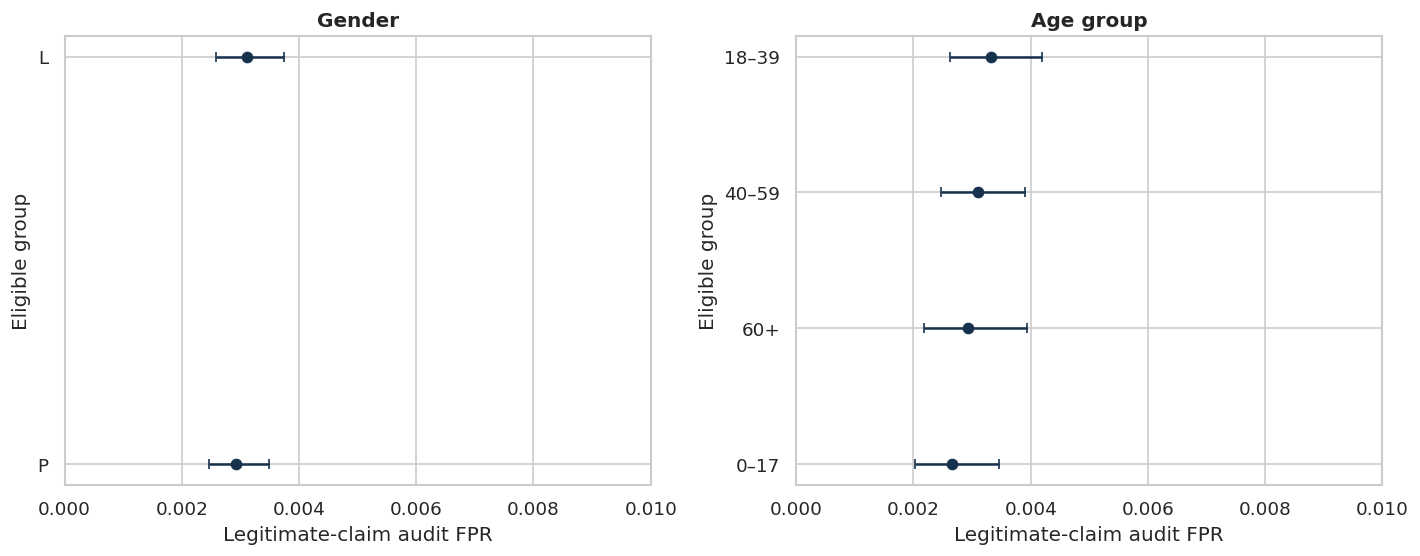

*Figure 4.12. Eligible-group false-positive audit exposure at the official 5% capacity; 95% Wilson intervals.*

**Question.** Do legitimate claims from eligible demographic groups face differential audit exposure?

**Method.** The exact DAC denominator and minimum of 100 non-fraud claims were applied independently at 3%, 5%, and 7%; every group table reports population, denominator, audits, legitimate audits, FPR, and Wilson intervals.

**Result.** At 5% capacity, the gender FPR gap is 0.0002, the age gap is 0.0007, and Protection Score is 0.9993. The larger observed gap is for age (0.0007). Gap behavior across capacities is reported in Table 4.19.

**Decision implication.** A larger gap identifies differential legitimate-claim audit exposure for investigation. It is monitored alongside capture, denominators, uncertainty, case mix, and ablation results; no protected-group score adjustment is applied.

**Limitation / alternative explanation.** The metric excludes small groups, reflects only labeled non-fraud claims, and cannot distinguish model artifacts from case mix, access, service patterns, geography, or label error. It measures disparity, not intent or causation.

In [26]:
def add_fpr_intervals(table):
    result = table.copy()
    intervals = [wilson_interval(int(row.legitimate_audits), int(row.nonfraud)) for row in result.itertuples()]
    result["FPR_ci_low"] = [interval[0] for interval in intervals]
    result["FPR_ci_high"] = [interval[1] for interval in intervals]
    return result


fairness_tables, fairness_gap_rows = [], []
for capacity in CFG.capacities:
    selected = top_k_mask(FINAL_OOF, capacity)
    score, gender_gap, age_gap, gender_table, age_table = protection_score(y, selected, PROTECTED)
    gender_table = add_fpr_intervals(gender_table).assign(capacity=capacity)
    age_table = add_fpr_intervals(age_table).assign(capacity=capacity)
    fairness_tables.extend([gender_table, age_table])
    fairness_gap_rows.append({
        "capacity": capacity, "gender_gap": gender_gap, "age_gap": age_gap,
        "ProtectionScore": score, "eligible_gender_groups": int(gender_table["eligible"].sum()),
        "eligible_age_groups": int(age_table["eligible"].sum()),
    })
FAIRNESS_DETAIL = pd.concat(fairness_tables, ignore_index=True)
FAIRNESS_GAPS = pd.DataFrame(fairness_gap_rows)
show_table(FAIRNESS_GAPS, "4.19", "Official policyholder-protection gaps by audit capacity")
show_table(FAIRNESS_DETAIL, "4.20", "Group audit exposure, legitimate-audit FPR, eligibility, and Wilson intervals")

fair5 = FAIRNESS_DETAIL[np.isclose(FAIRNESS_DETAIL["capacity"], 0.05) & FAIRNESS_DETAIL["eligible"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, attribute, title in ((axes[0], "gender", "Gender"), (axes[1], "age_group", "Age group")):
    plot = fair5[fair5["attribute"].eq(attribute)].sort_values("FPR")
    if len(plot):
        errors = np.vstack([plot["FPR"] - plot["FPR_ci_low"], plot["FPR_ci_high"] - plot["FPR"]])
        ax.errorbar(plot["FPR"], plot["group"], xerr=errors, fmt="o", color=COLORS["navy"], capsize=3)
    upper = max(0.01, float(fair5["FPR_ci_high"].max()) * 1.1) if len(fair5) else 0.1
    ax.set(title=title, xlabel="Legitimate-claim audit FPR", ylabel="Eligible group", xlim=(0, upper))
finish_figure(fig, "4.12", "Eligible-group false-positive audit exposure at the official 5% capacity; 95% Wilson intervals.")

GEOGRAPHIC_FAIRNESS = pd.DataFrame()
if "dati2" in train_clean:
    GEOGRAPHIC_FAIRNESS, geographic_gap = group_fpr_table(y, top_k_mask(FINAL_OOF, 0.05), train_clean["dati2"], "dati2")
    GEOGRAPHIC_FAIRNESS = add_fpr_intervals(GEOGRAPHIC_FAIRNESS).sort_values("FPR", ascending=False)
    TABLES["A.geographic_fairness"] = GEOGRAPHIC_FAIRNESS
else:
    geographic_gap = np.nan

fair5_gap = FAIRNESS_GAPS.loc[np.isclose(FAIRNESS_GAPS["capacity"], 0.05)].iloc[0]
widest_attribute = "gender" if fair5_gap.gender_gap >= fair5_gap.age_gap else "age"
widest_gap = max(fair5_gap.gender_gap, fair5_gap.age_gap)
report_block(
    "Do legitimate claims from eligible demographic groups face differential audit exposure?",
    "The exact DAC denominator and minimum of 100 non-fraud claims were applied independently at 3%, 5%, and 7%; every group table reports population, denominator, audits, legitimate audits, FPR, and Wilson intervals.",
    f"At 5% capacity, the gender FPR gap is {fair5_gap.gender_gap:.4f}, the age gap is {fair5_gap.age_gap:.4f}, and Protection Score is {fair5_gap.ProtectionScore:.4f}. The larger observed gap is for {widest_attribute} ({widest_gap:.4f}). Gap behavior across capacities is reported in Table 4.19.",
    "A larger gap identifies differential legitimate-claim audit exposure for investigation. It is monitored alongside capture, denominators, uncertainty, case mix, and ablation results; no protected-group score adjustment is applied.",
    "The metric excludes small groups, reflects only labeled non-fraud claims, and cannot distinguish model artifacts from case mix, access, service patterns, geography, or label error. It measures disparity, not intent or causation."
)


## 4.12 Ablation, Fairness Stability, and Robustness

Robustness experiments test specific hypotheses rather than enumerate arbitrary settings: direct protected-feature dependence, location-proxy dependence, engineered-feature value, empirically suspicious signals, model stochasticity, geographic transport, blend weight, calibration method, and bootstrap sampling variation. Each feature ablation uses the same signature-grouped folds and CatBoost family so that representation is the controlled difference. Removing a protected variable does not remove its proxies; a null disparity change is therefore informative rather than surprising.


Default metric period is 5 because AUC is/are not implemented for GPU


Ablation Protected attributes removed fold 1/5 | Technical=0.91784 | AP=0.82204


Default metric period is 5 because AUC is/are not implemented for GPU


Ablation Protected attributes removed fold 2/5 | Technical=0.92177 | AP=0.81838


Default metric period is 5 because AUC is/are not implemented for GPU


...

**Table 4.24. Selected-system fold and demographic-gap stability**

,fold,NormalizedRecall@5%,AveragePrecision,Brier,Gap_gender,Gap_age,ProtectionScore,TechnicalScore
0,1,0.9627,0.8226,0.1714,0.0013,0.0015,0.9985,0.9181
1,2,0.9719,0.8189,0.1727,0.0001,0.0013,0.9987,0.9223
2,3,0.9756,0.8284,0.1703,0.0004,0.0019,0.9981,0.9265
3,4,0.9675,0.8235,0.1732,0.0003,0.0020,0.9980,0.9207
4,5,0.9731,0.8236,0.1733,0.0005,0.0022,0.9978,0.9237


**Table 4.25. Low-dimensional CatBoost–XGBoost weight sensitivity**

,CatBoost_weight,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore
0,0.0000,0.9527,0.7968,0.1829,0.9978,0.9057
1,0.1250,0.9584,0.8051,0.1796,0.9980,0.9110
2,0.2500,0.9639,0.8117,0.1769,0.9983,0.9158
3,0.3750,0.9663,0.8167,0.1747,0.9985,0.9184
4,0.5000,0.9684,0.8203,0.1732,0.9987,0.9206
5,0.6250,0.9714,0.8227,0.1722,0.9987,0.9228
6,0.7500,0.9714,0.8239,0.1718,0.9989,0.9232
7,0.8750,0.9712,0.8241,0.1718,0.9991,0.9231
8,1.0000,0.9699,0.8234,0.1722,0.9993,0.9222


/tmp/ipykernel_24/834971845.py:141: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


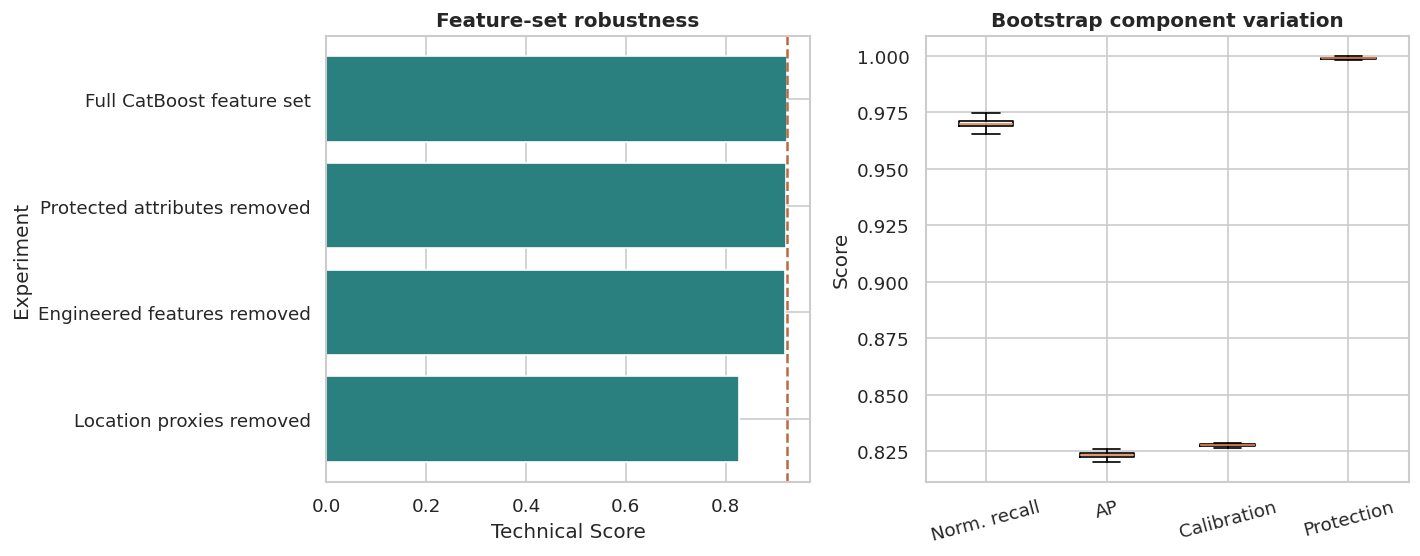

*Figure 4.13. Targeted feature-ablation and bootstrap stability evidence.*

**Question.** Does the selected conclusion survive reasonable perturbations?

**Method.** Controlled ablations, an alternate model seed, location holdout, fold inspection, calibration and blend sensitivity, capacity variation, and stratified bootstrap intervals were combined.

**Result.** Removing direct protected features changes Technical Score by -0.00040 and Protection Score by -0.00053. The CatBoost-anchor unseen-location holdout Technical Score is 0.75150 with zero location overlap. The selected Technical Score is 0.92223; its bootstrap 95% interval is [0.91998, 0.92438]. Alternate-seed CatBoost scores 0.92271.

**Decision implication.** Claims about superiority are restricted to differences that exceed ordinary fold/seed/feature perturbation. Material degradation after removing a suspicious set blocks operational use until semantics are resolved; persistent disparity after removing protected attributes indicates proxy pathways remain possible.

**Limitation / alternative explanation.** Bootstrap intervals are conditional on fixed OOF predictions and do not refit the learner; rows are not independent policyholder histories, geographic holdout is only one partition, and GPU boosting can be slightly nondeterministic. Robustness narrows uncertainty but does not establish future external validity.

In [27]:
def calibrated_summary(name, raw_prediction):
    table, predictions, method = calibration_diagnostics(name, raw_prediction)
    prediction = predictions[method]
    metric = augmented_metrics(y, prediction, PROTECTED)
    return prediction, method, metric, table


ENGINEERED_COLUMNS = [c for c in FEATURE_COLUMNS if c not in raw_feature_columns]
interaction_parents = {
    "cmg__severity": {"cmg", "severitylevel"},
    "service__facility": {"jnspelsep", "typeppk"},
    "geo__facility": {"dati2", "typeppk"},
}
suspicious_ablation_features = set(SUSPICIOUS_SIGNAL_FEATURES)
suspicious_ablation_features.update(
    engineered for engineered, parents in interaction_parents.items()
    if parents & suspicious_ablation_features
)
ablation_feature_sets = {
    "Full CatBoost feature set": FEATURE_COLUMNS,
    "Protected attributes removed": [c for c in FEATURE_COLUMNS if c not in PROTECTED_FEATURES],
    "Location proxies removed": [c for c in FEATURE_COLUMNS if c not in LOCATION_PROXY_FEATURES],
    "Engineered features removed": [c for c in FEATURE_COLUMNS if c not in ENGINEERED_COLUMNS],
}
if SUSPICIOUS_SIGNAL_FEATURES:
    ablation_feature_sets["Suspicious-screen features removed"] = [c for c in FEATURE_COLUMNS if c not in suspicious_ablation_features]

ABLATION_PREDICTIONS = {"Full CatBoost feature set": CALIBRATED_OOF["CatBoost"]}
ablation_rows = []
base_ablation_metric = augmented_metrics(y, ABLATION_PREDICTIONS["Full CatBoost feature set"], PROTECTED)
ablation_rows.append({
    "experiment": "Full CatBoost feature set", "removed_features": 0,
    "calibration": CALIBRATION_METHOD["CatBoost"], **base_ablation_metric,
})
seen_feature_sets = {tuple(FEATURE_COLUMNS)}
for experiment, features in list(ablation_feature_sets.items())[1:]:
    key = tuple(features)
    if key in seen_feature_sets or not features:
        continue
    seen_feature_sets.add(key)
    raw_prediction, _, _ = run_cv(
        "CatBoost", f"Ablation {experiment}", features, seed=CFG.seed,
        predict_test=False, notes="controlled CatBoost feature ablation",
    )
    calibrated, method, metric, _ = calibrated_summary(experiment, raw_prediction)
    ABLATION_PREDICTIONS[experiment] = calibrated
    ablation_rows.append({
        "experiment": experiment, "removed_features": len(FEATURE_COLUMNS) - len(features),
        "calibration": method, **metric,
    })

ABLATION_RESULTS = pd.DataFrame(ablation_rows)
for metric_name in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "Gap_gender", "Gap_age", "ProtectionScore", "TechnicalScore"]:
    baseline_value = float(ABLATION_RESULTS.loc[ABLATION_RESULTS["experiment"].eq("Full CatBoost feature set"), metric_name].iloc[0])
    ABLATION_RESULTS[f"delta_{metric_name}"] = ABLATION_RESULTS[metric_name] - baseline_value
show_table(
    ABLATION_RESULTS[[
        "experiment", "removed_features", "calibration", "NormalizedRecall@5%", "AveragePrecision",
        "Brier", "Gap_gender", "Gap_age", "ProtectionScore", "TechnicalScore",
        "delta_Gap_gender", "delta_Gap_age", "delta_ProtectionScore", "delta_TechnicalScore",
    ]],
    "4.21", "Controlled feature-ablation effects on performance and policyholder protection",
)

ALT_SEED = CFG.seed + 101
SEED_ANCHOR_NAME = "CatBoost" if FINAL_CHOICE == "CatBoost–XGBoost blend" else FINAL_CHOICE
seed_anchor = MODEL_ARTIFACTS[SEED_ANCHOR_NAME]
ALT_RAW, _, _ = run_cv(
    seed_anchor["kind"], f"{SEED_ANCHOR_NAME} seed {ALT_SEED}", seed_anchor["features"], seed=ALT_SEED,
    weight=seed_anchor.get("cv_weight"), predict_test=False, notes="selected-family stochastic robustness run",
)
ALT_OOF, ALT_CALIBRATION, ALT_METRICS, _ = calibrated_summary(f"Alternate-seed {SEED_ANCHOR_NAME}", ALT_RAW)

GEOGRAPHIC_HOLDOUT_METRICS = None
if "kdkc" in train_clean and train_clean["kdkc"].nunique() >= 5:
    geo_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=CFG.seed)
    geo_train_idx, geo_valid_idx = next(geo_splitter.split(X, y, groups=train_clean["kdkc"]))
    geo_prediction, _, _, _ = fit_predict_fold(
        "CatBoost", X.iloc[geo_train_idx], y[geo_train_idx], X.iloc[geo_valid_idx], y[geo_valid_idx],
        None, FEATURE_COLUMNS, CFG.seed + 707,
    )
    GEOGRAPHIC_HOLDOUT_METRICS = augmented_metrics(
        y[geo_valid_idx], geo_prediction, PROTECTED.iloc[geo_valid_idx].reset_index(drop=True)
    )
    GEOGRAPHIC_HOLDOUT_METRICS.update({
        "train_n": len(geo_train_idx), "holdout_n": len(geo_valid_idx),
        "train_locations": train_clean.iloc[geo_train_idx]["kdkc"].nunique(),
        "holdout_locations": train_clean.iloc[geo_valid_idx]["kdkc"].nunique(),
        "location_overlap": len(set(train_clean.iloc[geo_train_idx]["kdkc"]) & set(train_clean.iloc[geo_valid_idx]["kdkc"])),
    })

bootstrap_rng = np.random.default_rng(CFG.seed + 404)
positive_idx, negative_idx = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
bootstrap_rows = []
for repetition in range(CFG.bootstrap_repetitions):
    sample_idx = np.r_[
        bootstrap_rng.choice(positive_idx, len(positive_idx), replace=True),
        bootstrap_rng.choice(negative_idx, len(negative_idx), replace=True),
    ]
    bootstrap_rng.shuffle(sample_idx)
    metric = official_metrics(y[sample_idx], FINAL_OOF[sample_idx], PROTECTED.iloc[sample_idx].reset_index(drop=True))
    bootstrap_rows.append({"repetition": repetition, **metric})
BOOTSTRAP_METRICS = pd.DataFrame(bootstrap_rows)
ci_rows = []
for metric_name in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "Gap_gender", "Gap_age", "ProtectionScore", "TechnicalScore"]:
    low, median, high = BOOTSTRAP_METRICS[metric_name].quantile([0.025, 0.5, 0.975])
    ci_rows.append({"metric": metric_name, "estimate": FINAL_METRICS[metric_name], "bootstrap_median": median, "ci_2.5%": low, "ci_97.5%": high})
BOOTSTRAP_INTERVALS = pd.DataFrame(ci_rows)

fold_stability_rows = []
for fold in range(CFG.folds):
    idx = np.flatnonzero(FOLD_ID == fold)
    fold_stability_rows.append({"fold": fold + 1, **official_metrics(y[idx], FINAL_OOF[idx], PROTECTED.iloc[idx].reset_index(drop=True))})
FINAL_FOLD_STABILITY = pd.DataFrame(fold_stability_rows)

BLEND_WEIGHT_SENSITIVITY = pd.DataFrame()
if {"CatBoost", "XGBoost"}.issubset(OOF_PREDICTIONS):
    rows = []
    for weight in np.linspace(0, 1, 9):
        raw = weight * OOF_PREDICTIONS["CatBoost"] + (1 - weight) * OOF_PREDICTIONS["XGBoost"]
        calibrated = cross_fitted_calibration(raw, y, FINAL_CALIBRATION_METHOD, CFG.seed + 83)
        rows.append({"CatBoost_weight": weight, **augmented_metrics(y, calibrated, PROTECTED)})
    BLEND_WEIGHT_SENSITIVITY = pd.DataFrame(rows)

ALL_FOLD_METRICS = pd.DataFrame(FOLD_RECORDS)
ROBUSTNESS_SUMMARY = pd.DataFrame([
    {"scenario": "Selected OOF system", **FINAL_METRICS},
    {"scenario": f"{SEED_ANCHOR_NAME} alternate seed {ALT_SEED}", **ALT_METRICS},
] + ([{"scenario": "CatBoost anchor: unseen-kdkc holdout", **GEOGRAPHIC_HOLDOUT_METRICS}] if GEOGRAPHIC_HOLDOUT_METRICS else []))
show_table(ROBUSTNESS_SUMMARY, "4.22", "Seed and geographic-holdout robustness summary")
show_table(BOOTSTRAP_INTERVALS, "4.23", f"Stratified bootstrap intervals ({CFG.bootstrap_repetitions} repetitions)")
show_table(FINAL_FOLD_STABILITY[["fold", "NormalizedRecall@5%", "AveragePrecision", "Brier", "Gap_gender", "Gap_age", "ProtectionScore", "TechnicalScore"]], "4.24", "Selected-system fold and demographic-gap stability")
if len(BLEND_WEIGHT_SENSITIVITY):
    show_table(BLEND_WEIGHT_SENSITIVITY[["CatBoost_weight", "NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]], "4.25", "Low-dimensional CatBoost–XGBoost weight sensitivity")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ablation_plot = ABLATION_RESULTS.sort_values("TechnicalScore")
axes[0].barh(ablation_plot["experiment"], ablation_plot["TechnicalScore"], color=COLORS["teal"])
axes[0].axvline(base_ablation_metric["TechnicalScore"], color=COLORS["orange"], ls="--")
axes[0].set(title="Feature-set robustness", xlabel="Technical Score", ylabel="Experiment")
axes[1].boxplot(
    [BOOTSTRAP_METRICS["NormalizedRecall@5%"], BOOTSTRAP_METRICS["AveragePrecision"],
     BOOTSTRAP_METRICS["CalibrationScore"], BOOTSTRAP_METRICS["ProtectionScore"]],
    labels=["Norm. recall", "AP", "Calibration", "Protection"], showfliers=False,
)
axes[1].set(title="Bootstrap component variation", ylabel="Score")
axes[1].tick_params(axis="x", rotation=15)
finish_figure(fig, "4.13", "Targeted feature-ablation and bootstrap stability evidence.")

protected_row = ABLATION_RESULTS[ABLATION_RESULTS["experiment"].eq("Protected attributes removed")]
protected_text = (
    f"Removing direct protected features changes Technical Score by {protected_row['delta_TechnicalScore'].iloc[0]:+.5f} and Protection Score by {protected_row['delta_ProtectionScore'].iloc[0]:+.5f}."
    if len(protected_row) else "No distinct protected-feature ablation could be formed from the available schema."
)
ci_score = BOOTSTRAP_INTERVALS[BOOTSTRAP_INTERVALS["metric"].eq("TechnicalScore")].iloc[0]
geo_text = (
    f"The CatBoost-anchor unseen-location holdout Technical Score is {GEOGRAPHIC_HOLDOUT_METRICS['TechnicalScore']:.5f} with zero location overlap."
    if GEOGRAPHIC_HOLDOUT_METRICS else "The schema did not support a meaningful location-group holdout."
)
report_block(
    "Does the selected conclusion survive reasonable perturbations?",
    "Controlled ablations, an alternate model seed, location holdout, fold inspection, calibration and blend sensitivity, capacity variation, and stratified bootstrap intervals were combined.",
    f"{protected_text} {geo_text} The selected Technical Score is {FINAL_METRICS['TechnicalScore']:.5f}; its bootstrap 95% interval is [{ci_score['ci_2.5%']:.5f}, {ci_score['ci_97.5%']:.5f}]. Alternate-seed {SEED_ANCHOR_NAME} scores {ALT_METRICS['TechnicalScore']:.5f}.",
    "Claims about superiority are restricted to differences that exceed ordinary fold/seed/feature perturbation. Material degradation after removing a suspicious set blocks operational use until semantics are resolved; persistent disparity after removing protected attributes indicates proxy pathways remain possible.",
    "Bootstrap intervals are conditional on fixed OOF predictions and do not refit the learner; rows are not independent policyholder histories, geographic holdout is only one partition, and GPU boosting can be slightly nondeterministic. Robustness narrows uncertainty but does not establish future external validity."
)


## 4.13 Full-Data Fit, Probability Transfer, and Submission

After all choices are frozen, the selected component model or models are refitted on every permitted labeled claim. Boosting rounds are the median early-stopped count across primary folds. The selected calibrator is then fitted on OOF base predictions—not in-sample full-model predictions—and applied to the full-model evaluation output. Evaluation identifiers are restored in sample-submission order and validated before writing.


In [28]:
def median_iterations(name, default):
    values = MODEL_ARTIFACTS.get(name, {}).get("best_iterations", [])
    values = [int(value) for value in values if value and value > 0]
    return int(np.median(values)) if values else default


def fit_full_model(name):
    info = MODEL_ARTIFACTS[name]
    kind, features, seed = info["kind"], info["features"], info["seed"]
    categorical = [c for c in features if c in CATEGORICAL_COLUMNS]
    numeric = [c for c in features if c not in categorical]
    started = time.perf_counter()

    if kind == "Logistic":
        model = Pipeline([
            ("transform", basic_preprocessor(categorical, numeric, ordinal=False)),
            ("model", LogisticRegression(C=0.5, max_iter=700, solver="saga", random_state=seed)),
        ])
        model.fit(X[features], y)
        prediction = model.predict_proba(X_test[features])[:, 1]
        artifact = model
    elif kind == "CatBoost":
        iterations = median_iterations(name, CFG.cat_iterations)
        parameters = dict(
            loss_function="Logloss", iterations=iterations, learning_rate=0.035, depth=8,
            l2_leaf_reg=6.0, random_strength=0.5, bootstrap_type="Bayesian", bagging_temperature=0.8,
            random_seed=seed, allow_writing_files=False, verbose=False, task_type=CAT_TASK,
        )
        if info.get("weight") is not None:
            parameters["scale_pos_weight"] = info["weight"]
        if CAT_DEVICES:
            parameters["devices"] = CAT_DEVICES
        model = CatBoostClassifier(**parameters)
        train_cb = catboost_ready(X[features], categorical)
        test_cb = catboost_ready(X_test[features], categorical)
        try:
            model.fit(train_cb, y, cat_features=categorical, verbose=False)
        except Exception as error:
            message = str(error).lower()
            if CAT_TASK != "GPU" or not any(token in message for token in ("gpu", "cuda", "nccl")):
                raise
            warnings.warn(f"Full CatBoost GPU fit failed ({error}); retrying on CPU.")
            parameters.update(task_type="CPU"); parameters.pop("devices", None)
            model = CatBoostClassifier(**parameters)
            model.fit(train_cb, y, cat_features=categorical, verbose=False)
        prediction = model.predict_proba(test_cb)[:, 1]
        artifact = model
    elif kind == "XGBoost":
        iterations = median_iterations(name, CFG.xgb_estimators)
        transformer = basic_preprocessor(categorical, numeric, ordinal=True)
        train_encoded = transformer.fit_transform(X[features])
        test_encoded = transformer.transform(X_test[features])
        model = XGBClassifier(
            n_estimators=iterations, learning_rate=0.035, max_depth=7, min_child_weight=5,
            subsample=0.85, colsample_bytree=0.82, reg_alpha=0.05, reg_lambda=6.0,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", device=XGB_DEVICE,
            random_state=seed, n_jobs=8,
        )
        try:
            model.fit(train_encoded, y)
        except Exception as error:
            message = str(error).lower()
            if XGB_DEVICE != "cuda" or not any(token in message for token in ("gpu", "cuda")):
                raise
            warnings.warn(f"Full XGBoost CUDA fit failed ({error}); retrying on CPU.")
            model.set_params(device="cpu")
            model.fit(train_encoded, y)
        prediction = model.predict_proba(test_encoded)[:, 1]
        artifact = {"transformer": transformer, "model": model, "features": features}
    else:
        raise ValueError(f"Unsupported final family: {kind}")
    return np.clip(prediction, 0, 1), artifact, (time.perf_counter() - started) / 60


FULL_MODELS, FULL_TEST_COMPONENTS, full_fit_rows = {}, {}, []
components = [FINAL_CHOICE]
if FINAL_CHOICE == "CatBoost–XGBoost blend":
    components = ["CatBoost", "XGBoost"]
for component in components:
    prediction, artifact, minutes = fit_full_model(component)
    FULL_TEST_COMPONENTS[component] = prediction
    FULL_MODELS[component] = artifact
    full_fit_rows.append({"component": component, "minutes": minutes, "probability_mean": prediction.mean(), "probability_std": prediction.std()})

if FINAL_CHOICE == "CatBoost–XGBoost blend":
    final_weight = BLEND_EVIDENCE["final_weight"]
    FINAL_FULL_RAW_OOF = final_weight * OOF_PREDICTIONS["CatBoost"] + (1 - final_weight) * OOF_PREDICTIONS["XGBoost"]
    FINAL_TEST_RAW = final_weight * FULL_TEST_COMPONENTS["CatBoost"] + (1 - final_weight) * FULL_TEST_COMPONENTS["XGBoost"]
else:
    FINAL_FULL_RAW_OOF = OOF_PREDICTIONS[FINAL_CHOICE]
    FINAL_TEST_RAW = FULL_TEST_COMPONENTS[FINAL_CHOICE]

FINAL_CALIBRATOR = fit_calibrator(FINAL_CALIBRATION_METHOD, FINAL_FULL_RAW_OOF, y)
FINAL_TEST_PROBABILITY = np.clip(
    apply_calibrator(FINAL_CALIBRATOR, FINAL_CALIBRATION_METHOD, FINAL_TEST_RAW), 0, 1
)


def adjust_for_prior_shift(probabilities, source_prevalence, target_prevalence):
    """Sensitivity only: valid when class-conditional feature distributions are stable."""
    if not 0 < source_prevalence < 1 or not 0 < target_prevalence < 1:
        raise ValueError("source and target prevalence must lie strictly between 0 and 1")
    p = np.clip(np.asarray(probabilities, dtype=float), 1e-8, 1 - 1e-8)
    odds = p / (1 - p)
    correction = (target_prevalence / (1 - target_prevalence)) / (source_prevalence / (1 - source_prevalence))
    adjusted_odds = odds * correction
    return adjusted_odds / (1 + adjusted_odds)


assert np.allclose(adjust_for_prior_shift(np.array([0.2, 0.8]), 0.5, 0.5), [0.2, 0.8])

submission = pd.DataFrame({
    ID_COL: sample_submission[ID_COL].to_numpy(),
    "fraud_probability": FINAL_TEST_PROBABILITY.astype(float),
})
assert list(submission.columns) == ["claim_id", "fraud_probability"]
assert len(submission) == len(sample_submission) == len(test_raw)
assert submission[ID_COL].astype(str).equals(sample_submission[ID_COL].astype(str))
assert not submission[ID_COL].duplicated().any()
assert pd.api.types.is_numeric_dtype(submission["fraud_probability"])
assert np.isfinite(submission["fraud_probability"]).all()
assert submission["fraud_probability"].between(0, 1, inclusive="both").all()
assert not submission.isna().any().any()

SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
assert pd.read_csv(SUBMISSION_PATH).shape == submission.shape

FULL_FIT_SUMMARY = pd.DataFrame(full_fit_rows)
SUBMISSION_SUMMARY = submission["fraud_probability"].describe().to_frame("value")
TABLES["A.full_fit"] = FULL_FIT_SUMMARY
TABLES["A.submission_summary"] = SUBMISSION_SUMMARY
REPORT_FACTS.update({
    "submission_path": str(SUBMISSION_PATH), "submission_rows": len(submission),
    "test_probability_mean": float(FINAL_TEST_PROBABILITY.mean()),
    "test_probability_min": float(FINAL_TEST_PROBABILITY.min()),
    "test_probability_max": float(FINAL_TEST_PROBABILITY.max()),
})

EXPERIMENT_REGISTRY.to_csv(OUTPUT_DIR / "experiment_registry.csv", index=False)
ALL_FOLD_METRICS.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
FAIRNESS_DETAIL.to_csv(OUTPUT_DIR / "fairness_detail.csv", index=False)
BOOTSTRAP_INTERVALS.to_csv(OUTPUT_DIR / "bootstrap_intervals.csv", index=False)

display(Markdown(
    f"### Submission created successfully\n\n"
    f"- **Path:** `{SUBMISSION_PATH}`\n"
    f"- **Shape:** {submission.shape}\n"
    f"- **Model:** {FINAL_CHOICE}\n"
    f"- **Calibration:** {FINAL_CALIBRATION_METHOD}\n"
    f"- **Probability range:** [{FINAL_TEST_PROBABILITY.min():.6f}, {FINAL_TEST_PROBABILITY.max():.6f}]\n"
    f"- **Mean probability:** {FINAL_TEST_PROBABILITY.mean():.6f}"
))
show_table(submission.head(), "4.26", "Validated Kaggle submission preview")
show_table(SUBMISSION_SUMMARY, "4.27", "Evaluation probability distribution summary")


### Submission created successfully

- **Path:** `/kaggle/working/submission.csv`
- **Shape:** (40043, 2)
- **Model:** CatBoost
- **Calibration:** sigmoid
- **Probability range:** [0.006636, 0.998102]
- **Mean probability:** 0.500841

**Table 4.26. Validated Kaggle submission preview**

,claim_id,fraud_probability
0,CLM_8D29A008FB3F6B,0.6842
1,CLM_E15AA2EC5E05DB,0.9754
2,CLM_71FDA31CB6D5B0,0.8241
3,CLM_E478EDD63AA6DB,0.8636
4,CLM_F5407EE803152B,0.7681


**Table 4.27. Evaluation probability distribution summary**

,value
count,40043.0000
mean,0.5008
std,0.2818
min,0.0066
25%,0.2465
50%,0.5005
75%,0.7470
max,0.9981


## 4.14 Operational Interpretation


In [29]:
test_top5 = top_k_mask(FINAL_TEST_PROBABILITY, 0.05)
test_k = int(test_top5.sum())
top5_min = float(FINAL_TEST_PROBABILITY[test_top5].min()) if test_k else np.nan
test_shift_note = (
    "Because adversarial separability is strong, the evaluation ranking should be treated with increased uncertainty."
    if ADVERSARIAL_AUC >= 0.75 else
    "Adversarial separability does not remove the need for post-deployment drift monitoring."
)
report_block(
    "What does the final score mean for an investigator-facing workflow?",
    "The calibrated full-data probability determines rank; exactly floor(5% × N) evaluation claims define the competition audit portfolio. No binary audit label is written to the submission.",
    f"The evaluation file contains {len(submission):,} claims, so {test_k:,} would enter a 5% portfolio. The lowest probability inside that portfolio is {top5_min:.6f}; this value is a capacity-dependent boundary, not a universal fraud threshold. {test_shift_note}",
    "The investigator queue should show rank, calibrated probability, claim facts, leading local drivers, and data-quality warnings. Investigators decide whether evidence warrants escalation; claim payment or denial must follow authorized procedures and independent evidence.",
    "The Kaggle test set has no labels in this notebook. Its capture, calibration, and disparity cannot be asserted until outcomes mature; OOF estimates are the evidence base and must be refreshed on operational cohorts."
)


**Question.** What does the final score mean for an investigator-facing workflow?

**Method.** The calibrated full-data probability determines rank; exactly floor(5% × N) evaluation claims define the competition audit portfolio. No binary audit label is written to the submission.

**Result.** The evaluation file contains 40,043 claims, so 2,002 would enter a 5% portfolio. The lowest probability inside that portfolio is 0.937428; this value is a capacity-dependent boundary, not a universal fraud threshold. Adversarial separability does not remove the need for post-deployment drift monitoring.

**Decision implication.** The investigator queue should show rank, calibrated probability, claim facts, leading local drivers, and data-quality warnings. Investigators decide whether evidence warrants escalation; claim payment or denial must follow authorized procedures and independent evidence.

**Limitation / alternative explanation.** The Kaggle test set has no labels in this notebook. Its capture, calibration, and disparity cannot be asserted until outcomes mature; OOF estimates are the evidence base and must be refreshed on operational cohorts.

# CHAPTER V: Conclusion and Recommendation

## 5.1 Conclusion

The conclusions below answer every research question from Chapter I using the executed OOF evidence. They deliberately separate what the analysis supports from what remains unknown.


In [30]:
top_quality_issues = []
if REPORT_FACTS["missing_cells"]:
    top_quality_issues.append(f"{REPORT_FACTS['missing_cells']:,} missing cells")
if whitespace_changes:
    top_quality_issues.append(f"{whitespace_changes:,} whitespace-normalized categorical values")
if REPORT_FACTS["conflicting_signatures"]:
    top_quality_issues.append(f"{REPORT_FACTS['conflicting_signatures']:,} identical signatures with conflicting labels")
if unseen_features:
    top_quality_issues.append(f"evaluation-only levels in {unseen_features} features")
quality_sentence = ", ".join(top_quality_issues) if top_quality_issues else "no material issue under the implemented checks"

protected_conclusion = "not estimable"
if len(protected_row):
    protected_conclusion = (
        f"direct protected-feature removal changes Technical Score by {protected_row['delta_TechnicalScore'].iloc[0]:+.5f} "
        f"and Protection Score by {protected_row['delta_ProtectionScore'].iloc[0]:+.5f}"
    )

top_explanation = ", ".join(f"`{name}`" for name in PERMUTATION_IMPORTANCE.head(3)["feature"].tolist())
rq_answers = [
    ("RQ1 — data fitness", f"The sample contains {len(train_raw):,} labeled claims with an observed fraud prevalence of {y.mean():.2%}. The principal documented conditions are {quality_sentence}. These conditions are handled explicitly; the labeled prevalence is not generalized to operations."),
    ("RQ2 — signal and leakage", f"`claim_id` and {len(CONSTANT_COLUMNS)} constant fields are excluded. The strongest fold-safe univariate AP is {top_univariate.univariate_oof_AP:.4f} for `{top_univariate.feature}`. Suspicious, protected, and location-proxy sets are tested by ablation rather than retained solely for score."),
    ("RQ3 — validation", f"{PRIMARY_VALIDATION} eliminates repeated-signature train–validation overlap ({REPORT_FACTS['primary_signature_overlap']:,} versus {REPORT_FACTS['ordinary_signature_overlap']:,} under ordinary stratification). The geographic holdout is reported separately because deployment robustness and leaderboard-proxy validation answer different questions."),
    ("RQ4 — predictive performance", f"The selected `{FINAL_CHOICE}` reaches OOF Normalized Recall@5%={FINAL_METRICS['NormalizedRecall@5%']:.4f}, AP={FINAL_METRICS['AveragePrecision']:.4f}, and Technical Score={FINAL_METRICS['TechnicalScore']:.5f}. Its 95% stratified-bootstrap Technical Score interval is [{ci_score['ci_2.5%']:.5f}, {ci_score['ci_97.5%']:.5f}]."),
    ("RQ5 — calibration", f"Cross-fitted `{FINAL_CALIBRATION_METHOD}` calibration yields Brier={FINAL_METRICS['Brier']:.5f} and Calibration Score={FINAL_METRICS['CalibrationScore']:.5f}. This is calibration to the labeled competition distribution; operational reliability requires fresh labels and, if prevalence differs, explicit prior-shift assessment."),
    ("RQ6 — capacity", f"Fraud capture changes from {row3.fraud_captured:,.0f} labels at 3% to {row5.fraud_captured:,.0f} at 5% and {row7.fraud_captured:,.0f} at 7%; legitimate audits change from {row3.legitimate_audits:,.0f} to {row5.legitimate_audits:,.0f} and {row7.legitimate_audits:,.0f}. Capacity is therefore a transparent service trade-off, not a model threshold chosen in isolation."),
    ("RQ7 — policyholder protection", f"At 5%, the observed eligible-group gaps are {fair5_gap.gender_gap:.4f} for gender and {fair5_gap.age_gap:.4f} for age, producing Protection Score={fair5_gap.ProtectionScore:.4f}; {protected_conclusion}. These are disparities in labeled legitimate-claim exposure, not causal findings."),
    ("RQ8 — explanation", f"The three largest held-out permutation AP effects are {top_explanation or 'not estimable'}. Global, permutation, and local contribution evidence is available to investigators, but correlated predictors, proxy pathways, and non-causal attribution limit interpretation."),
    ("RQ9 — operation", f"The validated artifact contains {len(submission):,} probability rows at `{SUBMISSION_PATH}`. It supports a ranked human review queue with monitoring, override logging, appeal, drift response, recalibration, and retraining; it does not authorize automatic rejection."),
]
for title, answer in rq_answers:
    display(Markdown(f"### {title}\n\n{answer}"))


### RQ1 — data fitness

The sample contains 160,174 labeled claims with an observed fraud prevalence of 50.07%. The principal documented conditions are 76,189 whitespace-normalized categorical values, 1,737 identical signatures with conflicting labels, evaluation-only levels in 5 features. These conditions are handled explicitly; the labeled prevalence is not generalized to operations.

### RQ2 — signal and leakage

`claim_id` and 3 constant fields are excluded. The strongest fold-safe univariate AP is 0.6546 for `dati2`. Suspicious, protected, and location-proxy sets are tested by ablation rather than retained solely for score.

### RQ3 — validation

StratifiedGroupKFold by cleaned feature signature eliminates repeated-signature train–validation overlap (0 versus 13,092 under ordinary stratification). The geographic holdout is reported separately because deployment robustness and leaderboard-proxy validation answer different questions.

### RQ4 — predictive performance

The selected `CatBoost` reaches OOF Normalized Recall@5%=0.9699, AP=0.8234, and Technical Score=0.92223. Its 95% stratified-bootstrap Technical Score interval is [0.91998, 0.92438].

### RQ5 — calibration

Cross-fitted `sigmoid` calibration yields Brier=0.17218 and Calibration Score=0.82782. This is calibration to the labeled competition distribution; operational reliability requires fresh labels and, if prevalence differs, explicit prior-shift assessment.

### RQ6 — capacity

Fraud capture changes from 4,722 labels at 3% to 7,767 at 5% and 10,739 at 7%; legitimate audits change from 83 to 241 and 473. Capacity is therefore a transparent service trade-off, not a model threshold chosen in isolation.

### RQ7 — policyholder protection

At 5%, the observed eligible-group gaps are 0.0002 for gender and 0.0007 for age, producing Protection Score=0.9993; direct protected-feature removal changes Technical Score by -0.00040 and Protection Score by -0.00053. These are disparities in labeled legitimate-claim exposure, not causal findings.

### RQ8 — explanation

The three largest held-out permutation AP effects are `geo__facility`, `diagprimer`, `cmg__severity`. Global, permutation, and local contribution evidence is available to investigators, but correlated predictors, proxy pathways, and non-causal attribution limit interpretation.

### RQ9 — operation

The validated artifact contains 40,043 probability rows at `/kaggle/working/submission.csv`. It supports a ranked human review queue with monitoring, override logging, appeal, drift response, recalibration, and retraining; it does not authorize automatic rejection.

## 5.2 Recommendation

### 5.2.1 Investigator Interface and Decision Boundary

NHPA should deploy the system first in shadow mode. For each prioritized claim, the interface should display: audit rank and capacity context; calibrated fraud probability; the original claim fields needed to verify the case; the strongest signed local drivers; relevant data-quality warnings; model/version timestamp; and links to applicable investigation procedures. The screen should say explicitly that a driver is predictive evidence, not proof of fraud.

The model recommends **investigation priority only**. It must not automatically reject, suspend, or reduce a claim. An authorized investigator should review documentary and procedural evidence, record the disposition, and separate data-entry error, abuse, suspected fraud, and insufficient evidence. A small random sample outside the top 5% should also be reviewed to estimate missed fraud and selection-biased labels; this governance sample is analytically valuable even though it is outside the competition portfolio.

### 5.2.2 Human Override, Escalation, and Appeal

Investigators may override rank when new verified information is unavailable to the model, an urgent safety or statutory issue exists, a known data defect invalidates the score, or a linked case makes joint review operationally necessary. Every override should record initiator, time, reason category, evidence, prior score, and final disposition. Override rates and outcomes should be reviewed for systematic model blind spots and inconsistent practice.

Adverse operational action should require independent evidence and the existing authorization chain, not a score alone. A policyholder or provider should receive an intelligible reason tied to the underlying administrative evidence, a route to correct data, and an appeal reviewed by personnel independent of the original decision where feasible. Successful appeals feed label-quality review; they are not silently converted into training labels without adjudication.

### 5.2.3 Monitoring, Recalibration, and Retraining

Monitoring should compare like-for-like labeled outcome windows with the OOF reference and its uncertainty, rather than use arbitrary universal cutoffs. The runtime table below instantiates the baseline. Ranking metrics require matured labels; input and prediction drift can be monitored earlier. A trigger opens investigation—it does not automatically retrain.


In [31]:
monitoring_rows = [
    {"domain": "audit effectiveness", "measure": "Normalized Recall@5%, AP, precision@5%, fraud captured", "reference": f"OOF NR={FINAL_METRICS['NormalizedRecall@5%']:.4f}; AP={FINAL_METRICS['AveragePrecision']:.4f}", "investigate when": "a comparable matured-label window falls outside the OOF fold/bootstrap envelope or degrades repeatedly"},
    {"domain": "probability reliability", "measure": "Brier, reliability curve, calibration intercept/slope", "reference": f"OOF Brier={FINAL_METRICS['Brier']:.5f}; method={FINAL_CALIBRATION_METHOD}", "investigate when": "observed risk departs systematically from predicted risk or Brier deterioration persists"},
    {"domain": "policyholder protection", "measure": "eligible-group FPRs and gender/age gaps at 3/5/7%", "reference": f"5% gaps: gender={fair5_gap.gender_gap:.4f}; age={fair5_gap.age_gap:.4f}", "investigate when": "a gap exceeds its historical uncertainty or changes with case mix, labels, or overrides"},
    {"domain": "inputs", "measure": "missingness, unknown levels, ranges, KS/SMD/JS, schema", "reference": f"authoring adversarial AUC={ADVERSARIAL_AUC:.3f}", "investigate when": "a field breaks contract or drift exceeds the training/validation operating envelope"},
    {"domain": "predictions", "measure": "score distribution, top-5% boundary, tie size, alert volume", "reference": f"evaluation mean={FINAL_TEST_PROBABILITY.mean():.5f}; top-5% boundary={top5_min:.5f}", "investigate when": "distribution or portfolio composition changes without an explained business change"},
    {"domain": "process", "measure": "review time, override, escalation, appeal, confirmation and correction rates", "reference": "establish during shadow deployment", "investigate when": "workflow burden, disagreement, or successful appeals show a sustained adverse change"},
    {"domain": "drift and adaptation", "measure": "fraud prevalence, new typologies, feature–outcome relation, explanation mix", "reference": "establish by versioned outcome window", "investigate when": "covariate drift becomes error-linked or concept relationships materially change"},
]
MONITORING_PLAN = pd.DataFrame(monitoring_rows)
show_table(MONITORING_PLAN, "5.1", "Evidence-based production monitoring and investigation triggers")


**Table 5.1. Evidence-based production monitoring and investigation triggers**

,domain,measure,reference,investigate when
0,audit effectiveness,"Normalized Recall@5%, AP, precision@5%, fraud captured",OOF NR=0.9699; AP=0.8234,a comparable matured-label window falls outside the OOF fold/bootstrap envelope or degrades repeatedly
1,probability reliability,"Brier, reliability curve, calibration intercept/slope",OOF Brier=0.17218; method=sigmoid,observed risk departs systematically from predicted risk or Brier deterioration persists
2,policyholder protection,eligible-group FPRs and gender/age gaps at 3/5/7%,5% gaps: gender=0.0002; age=0.0007,"a gap exceeds its historical uncertainty or changes with case mix, labels, or overrides"
3,inputs,"missingness, unknown levels, ranges, KS/SMD/JS, schema",authoring adversarial AUC=0.507,a field breaks contract or drift exceeds the training/validation operating envelope
4,predictions,"score distribution, top-5% boundary, tie size, alert volume",evaluation mean=0.50084; top-5% boundary=0.93743,distribution or portfolio composition changes without an explained business change
5,process,"review time, override, escalation, appeal, confirmation and correction rates",establish during shadow deployment,"workflow burden, disagreement, or successful appeals show a sustained adverse change"
6,drift and adaptation,"fraud prevalence, new typologies, feature–outcome relation, explanation mix",establish by versioned outcome window,covariate drift becomes error-linked or concept relationships materially change


If ranking remains stable but reliability degrades, recalibrate on a sufficiently large, recent, adjudicated, representative window and validate it prospectively. Retrain when evidence indicates concept change, material and error-linked covariate drift, new fraud typologies, label-policy change, or sustained ranking degradation—not merely because a calendar date arrives. Re-run leakage, calibration, fairness, explanation, and shadow evaluation after every material model or data-pipeline change. Maintain a model card, data lineage, immutable versioning, approval record, and rollback path consistent with WHO and NIST governance principles [29], [30].

### 5.2.4 Deployment Sequence

1. Validate the data contract and reproduce this notebook in the controlled Kaggle/engineering environment.
2. Run shadow scoring without changing claim outcomes; compare investigator findings and collect a random-audit governance sample.
3. Review calibration and group exposure on matured adjudicated labels; resolve suspicious-feature semantics with process owners.
4. Pilot the ranked queue with trained investigators, logged overrides, independent escalation, and appeal.
5. Expand only after pre-specified effectiveness, reliability, burden, and protection evidence is acceptable; retain a tested rollback and manual-review route.

## 5.3 Limitations

The supplied labels may contain adjudication error, unresolved cases, or selection bias. The near-balanced labeled prevalence may not represent operations, so absolute probabilities may require future prevalence-aware recalibration. The schema lacks a verified event time, policyholder entity, provider entity, cost matrix, detailed clinical narrative, and label-generation history; signature grouping and location holdout cannot replace those structures. Observational associations, SHAP, and importance are not causal. Demographic FPR gaps depend on recorded categories, exclude groups with fewer than 100 legitimate claims, and do not cover all dimensions of equity or intersectional harm. Offline OOF validation cannot measure future fraud adaptation, operational feedback loops, investigator behavior, or private-test outcomes. CatBoost GPU arithmetic can be slightly nondeterministic. Finally, the competition score weights are a stated evaluation policy, not a complete social-welfare function; operational adoption requires legal, clinical, actuarial, privacy, and policy review beyond this notebook.


# REFERENCES

[1] DAC 2026 Competition Committee, “Preliminary-Round Competition Specification and Evaluation Rules,” official competition materials, 2026.

[2] World Health Organization, *Use of Machine Learning for Fraud Detection within the Claims Management Process in the Philippines: Insights from the National Health Insurance Scheme PhilHealth*. Geneva, Switzerland: WHO, 2024, ISBN 978-92-4-010133-3. [Online]. Available: https://www.who.int/publications/i/item/9789240101333

[3] World Health Organization, *The Implications of Artificial Intelligence and Machine Learning in Health Financing for Achieving Universal Health Coverage: Findings from a Rapid Literature Review*. Geneva, Switzerland: WHO, 2023, ISBN 978-92-4-006401-0. [Online]. Available: https://www.who.int/publications/i/item/9789240064010

[4] OECD, *Tackling Wasteful Spending on Health*. Paris, France: OECD Publishing, 2017, doi: 10.1787/9789264266414-en.

[5] H. Joudaki, A. Rashidian, B. Minaei-Bidgoli, M. Mahmoodi, B. Geraili, M. Nasiri, M. Arab, and E. Qorbani, “Using data mining to detect health care fraud and abuse: A review of literature,” *Global Journal of Health Science*, vol. 7, no. 1, pp. 194–202, 2015, doi: 10.5539/gjhs.v7n1p194.

[6] A. du Preez, S. Bhattacharya, P. Beling, and E. Bowen, “Fraud detection in healthcare claims using machine learning: A systematic review,” *Artificial Intelligence in Medicine*, vol. 160, Art. no. 103061, 2025, doi: 10.1016/j.artmed.2024.103061.

[7] J. M. Johnson and T. M. Khoshgoftaar, “Data-centric AI for healthcare fraud detection,” *SN Computer Science*, vol. 4, Art. no. 389, 2023, doi: 10.1007/s42979-023-01809-x.

[8] J. Davis and M. Goadrich, “The relationship between Precision-Recall and ROC curves,” in *Proc. 23rd International Conference on Machine Learning*, 2006, pp. 233–240, doi: 10.1145/1143844.1143874.

[9] T. Saito and M. Rehmsmeier, “The Precision-Recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets,” *PLOS ONE*, vol. 10, no. 3, Art. no. e0118432, 2015, doi: 10.1371/journal.pone.0118432.

[10] G. W. Brier, “Verification of forecasts expressed in terms of probability,” *Monthly Weather Review*, vol. 78, no. 1, pp. 1–3, 1950, doi: 10.1175/1520-0493(1950)078&lt;0001:VOFEIT&gt;2.0.CO;2.

[11] B. Van Calster, D. J. McLernon, M. van Smeden, L. Wynants, and E. W. Steyerberg, “Calibration: The Achilles heel of predictive analytics,” *BMC Medicine*, vol. 17, Art. no. 230, 2019, doi: 10.1186/s12916-019-1466-7.

[12] M. Saerens, P. Latinne, and C. Decaestecker, “Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure,” *Neural Computation*, vol. 14, no. 1, pp. 21–41, 2002, doi: 10.1162/089976602753284446.

[13] S. Kaufman, S. Rosset, C. Perlich, and O. Stitelman, “Leakage in data mining: Formulation, detection, and avoidance,” *ACM Transactions on Knowledge Discovery from Data*, vol. 6, no. 4, Art. no. 15, 2012, doi: 10.1145/2382577.2382579.

[14] D. R. Roberts *et al.*, “Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure,” *Ecography*, vol. 40, no. 8, pp. 913–929, 2017, doi: 10.1111/ecog.02881.

[15] G. C. Cawley and N. L. C. Talbot, “On over-fitting in model selection and subsequent selection bias in performance evaluation,” *Journal of Machine Learning Research*, vol. 11, pp. 2079–2107, 2010. [Online]. Available: https://www.jmlr.org/papers/v11/cawley10a.html

[16] J. H. Friedman, “Greedy function approximation: A gradient boosting machine,” *The Annals of Statistics*, vol. 29, no. 5, pp. 1189–1232, 2001, doi: 10.1214/aos/1013203451.

[17] L. Prokhorenkova, G. Gusev, A. Vorobev, A. V. Dorogush, and A. Gulin, “CatBoost: Unbiased boosting with categorical features,” in *Advances in Neural Information Processing Systems 31*, 2018, pp. 6638–6648. [Online]. Available: https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html

[18] T. Chen and C. Guestrin, “XGBoost: A scalable tree boosting system,” in *Proc. 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016, pp. 785–794, doi: 10.1145/2939672.2939785.

[19] Y. Benjamini and Y. Hochberg, “Controlling the false discovery rate: A practical and powerful approach to multiple testing,” *Journal of the Royal Statistical Society: Series B*, vol. 57, no. 1, pp. 289–300, 1995, doi: 10.1111/j.2517-6161.1995.tb02031.x.

[20] J. Lin, “Divergence measures based on the Shannon entropy,” *IEEE Transactions on Information Theory*, vol. 37, no. 1, pp. 145–151, 1991, doi: 10.1109/18.61115.

[21] B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. New York, NY, USA: Chapman & Hall, 1993, doi: 10.1007/978-1-4899-4541-9.

[22] E. B. Wilson, “Probable inference, the law of succession, and statistical inference,” *Journal of the American Statistical Association*, vol. 22, no. 158, pp. 209–212, 1927, doi: 10.1080/01621459.1927.10502953.

[23] M. Hardt, E. Price, and N. Srebro, “Equality of opportunity in supervised learning,” in *Advances in Neural Information Processing Systems 29*, 2016, pp. 3315–3323. [Online]. Available: https://papers.nips.cc/paper/6374-equality-of-opportunity-in-supervised-learning

[24] A. Rajkomar, M. Hardt, M. D. Howell, G. Corrado, and M. H. Chin, “Ensuring fairness in machine learning to advance health equity,” *Annals of Internal Medicine*, vol. 169, no. 12, pp. 866–872, 2018, doi: 10.7326/M18-1990.

[25] Z. Obermeyer, B. Powers, C. Vogeli, and S. Mullainathan, “Dissecting racial bias in an algorithm used to manage the health of populations,” *Science*, vol. 366, no. 6464, pp. 447–453, 2019, doi: 10.1126/science.aax2342.

[26] S. M. Lundberg and S.-I. Lee, “A unified approach to interpreting model predictions,” in *Advances in Neural Information Processing Systems 30*, 2017, pp. 4765–4774. [Online]. Available: https://papers.nips.cc/paper/7062-a-unified-approach-to-interpreting-model-predictions

[27] I. E. Kumar, S. Venkatasubramanian, C. Scheidegger, and S. Friedler, “Problems with Shapley-value-based explanations as feature importance measures,” in *Proc. 37th International Conference on Machine Learning*, PMLR, vol. 119, 2020, pp. 5491–5500. [Online]. Available: https://proceedings.mlr.press/v119/kumar20e.html

[28] J. Amann, A. Blasimme, E. Vayena, D. Frey, and V. I. Madai, “Explainability for artificial intelligence in healthcare: A multidisciplinary perspective,” *BMC Medical Informatics and Decision Making*, vol. 20, Art. no. 310, 2020, doi: 10.1186/s12911-020-01332-6.

[29] World Health Organization, *Ethics and Governance of Artificial Intelligence for Health*. Geneva, Switzerland: WHO, 2021, ISBN 978-92-4-002920-0. [Online]. Available: https://www.who.int/publications/i/item/9789240029200

[30] E. Tabassi, *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*, NIST AI 100-1. Gaithersburg, MD, USA: National Institute of Standards and Technology, 2023, doi: 10.6028/NIST.AI.100-1.

[31] J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, and A. Bouchachia, “A survey on concept drift adaptation,” *ACM Computing Surveys*, vol. 46, no. 4, Art. no. 44, 2014, doi: 10.1145/2523813.

[32] C. J. Kelly, A. Karthikesalingam, M. Suleyman, G. Corrado, and D. King, “Key challenges for delivering clinical impact with artificial intelligence,” *BMC Medicine*, vol. 17, Art. no. 195, 2019, doi: 10.1186/s12916-019-1426-2.

[33] A. Niculescu-Mizil and R. Caruana, “Predicting good probabilities with supervised learning,” in *Proc. 22nd International Conference on Machine Learning*, 2005, pp. 625–632, doi: 10.1145/1102351.1102430.

[34] S. Varma and R. Simon, “Bias in error estimation when using cross-validation for model selection,” *BMC Bioinformatics*, vol. 7, Art. no. 91, 2006, doi: 10.1186/1471-2105-7-91.

[35] CatBoost, “Training on GPU,” *CatBoost Documentation*. [Online]. Available: https://catboost.ai/docs/en/features/training-on-gpu. Accessed: Aug. 28, 2026.

[36] XGBoost Developers, “XGBoost GPU Support,” *XGBoost Documentation*. [Online]. Available: https://xgboost.readthedocs.io/en/stable/gpu/index.html. Accessed: Aug. 28, 2026.


# ATTACHMENT

## A.1 Literature Evidence Matrix

This matrix documents why each source family appears in the report. It is not an additional source of labels or predictive data.


In [32]:
LITERATURE_MATRIX = pd.DataFrame([
    {"citations": "[2]–[7]", "claim supported": "health-financing context, fraud-analytics workflow, data/label limitations", "chapter": "I, II, V"},
    {"citations": "[8]–[12], [33]", "claim supported": "PR evaluation, Brier score, calibration, prevalence shift", "chapter": "II, III, IV"},
    {"citations": "[13]–[15], [34]", "claim supported": "leakage, structured validation, selection bias", "chapter": "II, III"},
    {"citations": "[16]–[18]", "claim supported": "gradient boosting, CatBoost, XGBoost", "chapter": "II, III"},
    {"citations": "[19]–[22]", "claim supported": "multiplicity, shift divergence, bootstrap, Wilson uncertainty", "chapter": "II, III, IV"},
    {"citations": "[23]–[25]", "claim supported": "false-positive disparity and healthcare fairness cautions", "chapter": "II, IV, V"},
    {"citations": "[26]–[28]", "claim supported": "SHAP and limits of explanatory attribution", "chapter": "II, IV"},
    {"citations": "[29]–[32]", "claim supported": "human oversight, risk management, drift, deployment", "chapter": "I, II, V"},
    {"citations": "[35]–[36]", "claim supported": "supported multi-GPU CatBoost and CUDA XGBoost interfaces", "chapter": "III"},
])
show_table(LITERATURE_MATRIX, "A.1", "Verified literature-to-claim matrix")


**Table A.1. Verified literature-to-claim matrix**

,citations,claim supported,chapter
0,[2]–[7],"health-financing context, fraud-analytics workflow, data/label limitations","I, II, V"
1,"[8]–[12], [33]","PR evaluation, Brier score, calibration, prevalence shift","II, III, IV"
2,"[13]–[15], [34]","leakage, structured validation, selection bias","II, III"
3,[16]–[18],"gradient boosting, CatBoost, XGBoost","II, III"
4,[19]–[22],"multiplicity, shift divergence, bootstrap, Wilson uncertainty","II, III, IV"
5,[23]–[25],false-positive disparity and healthcare fairness cautions,"II, IV, V"
6,[26]–[28],SHAP and limits of explanatory attribution,"II, IV"
7,[29]–[32],"human oversight, risk management, drift, deployment","I, II, V"
8,[35]–[36],supported multi-GPU CatBoost and CUDA XGBoost interfaces,III


## A.2 Reproducibility, Feature Dictionary, and Parameters


In [33]:
feature_rows = []
all_columns = list(dict.fromkeys(list(train_raw.columns) + ENGINEERED_COLUMNS))
for column in all_columns:
    if column == ID_COL:
        role, decision = "identifier", "alignment only"
    elif column == TARGET_COL:
        role, decision = "target", "labels only"
    elif column in CONSTANT_COLUMNS:
        role, decision = "constant", "excluded"
    elif column in PROTECTED_FEATURES:
        role, decision = "protected / evaluation-sensitive", "main model plus ablation"
    elif column in LOCATION_PROXY_FEATURES:
        role, decision = "possible structural proxy", "main model plus ablation"
    elif column in ENGINEERED_COLUMNS:
        role, decision = "claim-derived", "included"
    elif column in CATEGORICAL_COLUMNS:
        role, decision = "categorical claim field", "included"
    else:
        role, decision = "numeric claim field", "included"
    feature_rows.append({
        "feature": column, "runtime_dtype": str(train_model[column].dtype) if column in train_model else "derived",
        "role": role, "decision": decision,
    })
FEATURE_DICTIONARY = pd.DataFrame(feature_rows)

MODEL_PARAMETER_TABLE = pd.DataFrame([
    {"model": "Logistic regression", "key settings": "one-hot(min_frequency=20), median imputation, scaling, C=0.5, saga"},
    {"model": "CatBoost", "key settings": f"iterations≤{CFG.cat_iterations}, lr=0.035, depth=8, L2=6, Bayesian bootstrap, early stop={CFG.early_stopping}, {CAT_TASK}"},
    {"model": "XGBoost", "key settings": f"estimators≤{CFG.xgb_estimators}, lr=0.035, depth=7, min_child_weight=5, row=0.85, column=0.82, L2=6, {XGB_DEVICE}"},
    {"model": "Calibration", "key settings": f"{CFG.calibration_folds}-fold cross-fit; raw/sigmoid/isotonic; selected={FINAL_CALIBRATION_METHOD}"},
    {"model": "Blend", "key settings": "CatBoost weight grid 0, .25, .50, .75, 1; outer-fold selection; median deployment weight"},
])

REPRODUCIBILITY_TABLE = pd.DataFrame([
    {"item": "configuration", "value": json.dumps(asdict(CFG), default=str)},
    {"item": "Python", "value": platform.python_version()},
    {"item": "pandas", "value": pd.__version__},
    {"item": "scikit-learn", "value": __import__("sklearn").__version__},
    {"item": "CatBoost GPUs", "value": f"count={GPU_COUNT}; devices={CAT_DEVICES or 'CPU'}"},
    {"item": "XGBoost", "value": __import__("xgboost").__version__},
    {"item": "primary validation", "value": PRIMARY_VALIDATION},
    {"item": "train / test / sample", "value": f"{TRAIN_PATH} | {TEST_PATH} | {SAMPLE_PATH}"},
    {"item": "submission", "value": str(SUBMISSION_PATH)},
])
show_table(REPRODUCIBILITY_TABLE, "A.2", "Runtime and reproducibility record")
show_table(MODEL_PARAMETER_TABLE, "A.3", "Model and selection parameters")
show_table(FEATURE_DICTIONARY, "A.4", "Complete runtime feature-role dictionary")


**Table A.2. Runtime and reproducibility record**

,item,value
0,configuration,"{""seed"": 2026, ""folds"": 5, ""calibration_folds"": 5, ""capacities"": [0.03, 0.05, 0.07], ""fast_mode"": false, ""cat_iterations"": 2200, ""xgb_estimators"": 2200, ""early_stopping"": 180, ""bootstrap_repetitions"": 250, ""shap_sample"": 1000, ""min_group_nonfraud"": 100}"
1,Python,3.12.13
2,pandas,2.3.3
3,scikit-learn,1.6.1
4,CatBoost GPUs,count=2; devices=0:1
5,XGBoost,3.2.0
6,primary validation,StratifiedGroupKFold by cleaned feature signature
7,train / test / sample,/kaggle/input/competitions/dac-its-2026/train.csv | /kaggle/input/competitions/dac-its-2026/test.csv | /kaggle/input/competitions/dac-its-2026/sample_submission.csv
8,submission,/kaggle/working/submission.csv


**Table A.3. Model and selection parameters**

,model,key settings
0,Logistic regression,"one-hot(min_frequency=20), median imputation, scaling, C=0.5, saga"
1,CatBoost,"iterations≤2200, lr=0.035, depth=8, L2=6, Bayesian bootstrap, early stop=180, GPU"
2,XGBoost,"estimators≤2200, lr=0.035, depth=7, min_child_weight=5, row=0.85, column=0.82, L2=6, cuda"
3,Calibration,5-fold cross-fit; raw/sigmoid/isotonic; selected=sigmoid
4,Blend,"CatBoost weight grid 0, .25, .50, .75, 1; outer-fold selection; median deployment weight"


**Table A.4. Complete runtime feature-role dictionary**

,feature,runtime_dtype,role,decision
0,claim_id,object,identifier,alignment only
1,kdkc,string,possible structural proxy,main model plus ablation
2,dati2,string,possible structural proxy,main model plus ablation
3,typeppk,string,categorical claim field,included
4,jkpst,string,protected / evaluation-sensitive,main model plus ablation
5,umur,int64,protected / evaluation-sensitive,main model plus ablation
6,jnspelsep,string,categorical claim field,included
7,los,int64,numeric claim field,included
8,cmg,string,categorical claim field,included
9,severitylevel,string,categorical claim field,included


## A.3 Extended Evidence and Completeness Audit


In [34]:
show_table(QUALITY_PROFILE, "A.5", "Complete data-quality profile")
show_table(EXPERIMENT_REGISTRY, "A.5b", "Complete global experiment registry and selection evidence")
show_table(ALL_FOLD_METRICS, "A.6", "Complete fold-level experiment and robustness metrics")
show_table(CATEGORICAL_ASSOCIATIONS, "A.7", "Complete categorical association screen")
show_table(NUMERIC_ASSOCIATIONS, "A.8", "Complete numeric association screen")
show_table(NUMERIC_SUMMARY, "A.9", "Robust numeric summaries, extreme quantiles, and skewness")
show_table(CATEGORY_LEVEL_RATES, "A.10", "Categorical level counts, fraud rates, and 95% Wilson intervals")
show_table(SPARSITY, "A.11", "Grouped diagnosis/procedure code sparsity")
show_table(BINARY_PROFILE, "A.11b", "Binary-feature prevalence and observed label rates")
show_table(GROUP_COOCCURRENCE.head(50), "A.12", "Strongest grouped-code co-occurrence by Jaccard index")
show_table(SHIFT_TABLE, "A.13", "Complete train–test feature shift screen")
show_table(ABLATION_RESULTS, "A.14", "Complete feature-ablation metrics and deltas")
if len(GEOGRAPHIC_FAIRNESS):
    show_table(GEOGRAPHIC_FAIRNESS, "A.15", "Supplementary geographic legitimate-claim audit exposure")

COMPLETENESS = pd.DataFrame([
    ("Task A", "missing/inconsistent values, duplicates, unusual values, cardinality, proxies, leakage, subgroups, association limits", bool(len(QUALITY_PROFILE) and len(DUPLICATE_SUMMARY) and len(LEAKAGE_REGISTER))),
    ("Task B", "features, preprocessing, models, validation, imbalance, leakage prevention, overfitting, calibration, drivers", bool(len(EXPERIMENT_REGISTRY) and len(CALIBRATION_COMPARISON) and len(PERMUTATION_IMPORTANCE))),
    ("Task C", "3%, 5%, 7%, fraud capture, legitimate audits, random and burden baselines, sensitivity", set(np.round(FINAL_ALLOCATION["capacity"], 2)) == {0.03, 0.05, 0.07}),
    ("Task D", "gender, four official age bands, >=100 eligibility, FPR gaps, uncertainty, careful interpretation", bool(set(age_groups(PROTECTED["age"]).dropna().unique()).issubset({"0–17", "18–39", "40–59", "60+", "Missing"}) and len(FAIRNESS_GAPS) == 3)),
    ("Task E", "verifier interface, alert information, override, appeal, monitoring, disparity, drift, recalibration, retraining, decision-support boundary", len(MONITORING_PLAN) >= 7),
    ("Technical", "exact normalized recall, AP, Brier, calibration, protection, composite and edge checks", all(key in FINAL_METRICS for key in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore", "ProtectionScore", "TechnicalScore"])),
    ("Research", "literature-backed Chapters I–II and verified IEEE bibliography", len(LITERATURE_MATRIX) >= 8),
    ("Reproducibility", "Kaggle discovery, T4×2 handling, seeds, sequential state, validated final submission", SUBMISSION_PATH.exists() and len(submission) == len(test_raw)),
], columns=["area", "evidence", "resolved"])
assert COMPLETENESS["resolved"].all(), COMPLETENESS.loc[~COMPLETENESS["resolved"]]
show_table(COMPLETENESS, "A.16", "DAC task and technical completeness matrix")

report_exports = {
    "model_decision.csv": MODEL_DECISION_TABLE,
    "audit_allocation.csv": AUDIT_ALLOCATION,
    "ablation_results.csv": ABLATION_RESULTS,
    "monitoring_plan.csv": MONITORING_PLAN,
    "quality_profile.csv": QUALITY_PROFILE,
    "train_test_shift.csv": SHIFT_TABLE,
    "categorical_level_rates.csv": CATEGORY_LEVEL_RATES,
}
for filename, frame in report_exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)

artifact_paths = {
    "submission": SUBMISSION_PATH,
    "fold assignments": fold_path,
    "experiment registry": OUTPUT_DIR / "experiment_registry.csv",
    "fold metrics": OUTPUT_DIR / "fold_metrics.csv",
    "fairness detail": OUTPUT_DIR / "fairness_detail.csv",
    "bootstrap intervals": OUTPUT_DIR / "bootstrap_intervals.csv",
    **{filename: OUTPUT_DIR / filename for filename in report_exports},
    **{f"Figure {number}": Path(path) for number, path in FIGURES.items()},
}
ARTIFACT_MANIFEST = pd.DataFrame([
    {"artifact": name, "path": str(path), "exists": Path(path).exists(), "bytes": Path(path).stat().st_size if Path(path).exists() else 0}
    for name, path in artifact_paths.items()
])
assert ARTIFACT_MANIFEST["exists"].all()
show_table(ARTIFACT_MANIFEST, "A.17", "Generated analytical artifact manifest", precision=0)

display(Markdown(
    f"**Reproducibility close.** All completeness checks passed. The competition submission is "
    f"[`{SUBMISSION_PATH.name}`]({SUBMISSION_PATH}) with {len(submission):,} rows; supporting tables and figures "
    f"are under `{OUTPUT_DIR}`. Re-run from the first cell after any data, dependency, configuration, or model change."
))


**Table A.5. Complete data-quality profile**

,feature,dtype,missing_n,missing_pct,blank_n,cardinality,rare_levels_lt20,rows_in_rare_levels,train_only_levels,test_only_levels,min,median,max
0,claim_id,object,0,0.0000,0,160174,160174,160174,160174,40043,—,—,—
1,kdkc,int64,0,0.0000,0,126,0,0,0,0,—,—,—
2,dati2,int64,0,0.0000,0,486,35,391,2,0,—,—,—
3,typeppk,object,0,0.0000,0,25,0,0,0,0,—,—,—
4,jkpst,object,0,0.0000,0,2,0,0,0,0,—,—,—
5,umur,int64,0,0.0000,0,105,13,65,5,0,0.0000,39.0000,109.0000
6,jnspelsep,int64,0,0.0000,0,2,0,0,0,0,—,—,—
7,los,int64,0,0.0000,0,128,96,298,64,14,0.0000,0.0000,592.0000
8,cmg,object,0,0.0000,0,23,1,8,0,0,—,—,—
9,severitylevel,int64,0,0.0000,0,4,0,0,0,0,—,—,—


**Table A.5b. Complete global experiment registry and selection evidence**

,model,family,features,validation,seed,N,K,P,TP_K,Recall@5%,Recall@capacity,Recall_max,NormalizedRecall@5%,NormalizedRecall@capacity,AveragePrecision,Brier,CalibrationScore,Gap_gender,Gap_age,ProtectionScore,TechnicalScore,Precision@capacity,LegitimateAudits,AuditFPR,Lift@capacity,ROC_AUC,LogLoss,fold_std,runtime_minutes,notes
0,CatBoost,CatBoost,63,StratifiedGroupKFold by cleaned feature signature,2026,160174,8008,80203,7769,0.0969,0.0969,0.0998,0.9702,0.9702,0.8234,0.1722,0.8278,0.0002,0.0008,0.9992,0.9224,0.9702,239,0.0030,1.9375,0.8221,0.5154,0.0032,8.3373,native categorical boosting; task=GPU; devices=0:1
1,XGBoost,XGBoost,63,StratifiedGroupKFold by cleaned feature signature,2026,160174,8008,80203,7629,0.0951,0.0951,0.0998,0.9527,0.9527,0.7968,0.1833,0.8167,0.0004,0.0022,0.9978,0.9056,0.9527,379,0.0047,1.9026,0.7989,0.5437,0.0040,0.8208,ordinal categorical representation; device=cuda
2,Fold prevalence,Constant,0,StratifiedGroupKFold by cleaned feature signature,2026,160174,8008,80203,8008,0.0998,0.0998,0.0998,1.0000,1.0000,0.4982,0.2500,0.7500,0.0000,0.0000,1.0000,0.8621,1.0000,0,0.0000,1.9971,0.4961,0.6932,0.0008,0.0000,fold-local prevalence; stable input order breaks ties
3,Logistic regression,Logistic,63,StratifiedGroupKFold by cleaned feature signature,2026,160174,8008,80203,7066,0.0881,0.0881,0.0998,0.8824,0.8824,0.7328,0.2056,0.7944,0.0013,0.0046,0.9954,0.8506,0.8824,942,0.0118,1.7622,0.7426,0.5973,0.0061,9.6496,regularized one-hot linear benchmark
4,Burden baseline,Burden,3,StratifiedGroupKFold by cleaned feature signature,2026,160174,8008,80203,4821,0.0601,0.0601,0.0998,0.6020,0.6020,0.5246,0.2487,0.7513,0.0005,0.0093,0.9907,0.6478,0.6020,3187,0.0399,1.2023,0.5377,0.6914,0.0010,0.0321,compact numeric claim-burden logistic model


**Table A.6. Complete fold-level experiment and robustness metrics**

...

**Table A.16. DAC task and technical completeness matrix**

,area,evidence,resolved
0,Task A,"missing/inconsistent values, duplicates, unusual values, cardinality, proxies, leakage, subgroups, association limits",True
1,Task B,"features, preprocessing, models, validation, imbalance, leakage prevention, overfitting, calibration, drivers",True
2,Task C,"3%, 5%, 7%, fraud capture, legitimate audits, random and burden baselines, sensitivity",True
3,Task D,"gender, four official age bands, >=100 eligibility, FPR gaps, uncertainty, careful interpretation",True
4,Task E,"verifier interface, alert information, override, appeal, monitoring, disparity, drift, recalibration, retraining, decision-support boundary",True
5,Technical,"exact normalized recall, AP, Brier, calibration, protection, composite and edge checks",True
6,Research,literature-backed Chapters I–II and verified IEEE bibliography,True
7,Reproducibility,"Kaggle discovery, T4×2 handling, seeds, sequential state, validated final submission",True


**Table A.17. Generated analytical artifact manifest**

,artifact,path,exists,bytes
0,submission,/kaggle/working/submission.csv,True,1531294
1,fold assignments,/kaggle/working/primary_fold_assignments.csv,True,3363668
2,experiment registry,/kaggle/working/experiment_registry.csv,True,2825
3,fold metrics,/kaggle/working/fold_metrics.csv,True,17281
4,fairness detail,/kaggle/working/fairness_detail.csv,True,2070
5,bootstrap intervals,/kaggle/working/bootstrap_intervals.csv,True,697
6,model_decision.csv,/kaggle/working/model_decision.csv,True,2132
7,audit_allocation.csv,/kaggle/working/audit_allocation.csv,True,1764
8,ablation_results.csv,/kaggle/working/ablation_results.csv,True,2524
9,monitoring_plan.csv,/kaggle/working/monitoring_plan.csv,True,1463


**Reproducibility close.** All completeness checks passed. The competition submission is [`submission.csv`](/kaggle/working/submission.csv) with 40,043 rows; supporting tables and figures are under `/kaggle/working`. Re-run from the first cell after any data, dependency, configuration, or model change.